# Benchmarking sample representation methods with patpy

Single-cell transcriptomics provides extremely high resolution view on biology. But many processes, such as diseases or ageing, manifest on tissue or organism level. To understand them, we need to understand diversity on a patient (or donor) level. Single-cell transcriptomics field is therefore moving to generating massive multi-donor datasets and integrated atlasses, containing hundreds to thousands donors per study ([Hrovatin, Sikkema, et al, Nature Methods 2025](https://www.nature.com/articles/s41592-024-02532-y))

![n_cells_and_donors_per_study](images/benchmarking_tutorial/single_cell_studies_trends.png)

Recently, sample (a.k.a. patient or donor) representation methods emerged to explore diversity on donor-level. But which of them work the best? In this tutorial, we'll show how to use `patpy` to run and compare different sample representation methods from single-cell data. To see more on benchmarking, refer to our benchmarking preprint [Shitov et al, Learning Meaningful Representations of Life (LMRL) Workshop at ICLR 2025](https://openreview.net/forum?id=IoRv5afWtb)

# Installation

Before running the code below, make sure you have dependencies installed. Most of what we use ships with the base install (`pip install patpy`). The deep methods need extras (and ideally a CUDA GPU):

```bash
pip install patpy[donordata]  # For keeping cells and sample-level metadata together
pip install patpy[pilot,mrvi,scpoli,diffusionemd]  # Optional for running deep learning methods
pip install mofapy2  # For running MOFA
```

Note that installing everything into **one enviroment can be challenging**. This is especially the case for deep learning methods. For larger-scale benchmarking, we recommend creating method-specific environments

# Import packages

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
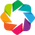

In [1]:
import ehrapy as ep  # Like scanpy, but for clinical data analysis. Convenient to preprocess the sample-level data
import scanpy as sc
import patpy  # Datasets, metrics, and analysis of sample representations
from donordata import DonorData  # Cells and sample-level metadata, aligned on the sample axis
import os  # For reading environment variables (e.g. PATPY_GLOSCOPE_GPU)
import pandas as pd  # Working with data frames

# Plotting
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# For displaying benchmarking metrics
from plottable import ColumnDefinition, Table
from plottable.cmap import normed_cmap
from plottable.plots import bar

import time as _time  # For measuring runtime of the methods

# Use a higher figure DPI for crisper plots in the rendered notebook,
# and remove the top/right spines from any seaborn scatter/bar plots.
matplotlib.rcParams['figure.dpi'] = 150
matplotlib.rcParams['savefig.dpi'] = 150


In [2]:
patpy.__version__

'0.12.1'

## Hallmarks of COVID-19 disease severity

We'll first dive deeply into the COMBAT dataset analysis ([COvid-19 Multi-omics Blood ATlas (COMBAT) Consortium, Cell, 2022](https://pubmed.ncbi.nlm.nih.gov/35216673/)). This dataset contains 783k peripheral blood mononuclear cells (PBMC) from 140 samples obtained from COVID-19, Flu, and Sepsis patients as well as from healthy donors. This dataset is a perfect sandbox for sample representation methods because it does not suffer from batch effects and hides a very clear COVID-19 severity trajectory. Let's see which method can uncover it the best.

`patpy` provides easy access to COMBAT dataset (as well as some others):

In [3]:
adata, adata_info = patpy.datasets.combat(return_dataset_info=True)
adata

AnnData object with n_obs × n_vars = 783677 × 3000
    obs: 'Annotation_cluster_id', 'Annotation_cluster_name', 'Annotation_minor_subset', 'Annotation_major_subset', 'Annotation_cell_type', 'GEX_region', 'QC_ngenes', 'QC_total_UMI', 'QC_pct_mitochondrial', 'QC_scrub_doublet_scores', 'TCR_chain_composition', 'TCR_clone_ID', 'TCR_clone_count', 'TCR_clone_proportion', 'TCR_contains_unproductive', 'TCR_doublet', 'TCR_chain_TRA', 'TCR_v_gene_TRA', 'TCR_d_gene_TRA', 'TCR_j_gene_TRA', 'TCR_c_gene_TRA', 'TCR_productive_TRA', 'TCR_cdr3_TRA', 'TCR_umis_TRA', 'TCR_chain_TRA2', 'TCR_v_gene_TRA2', 'TCR_d_gene_TRA2', 'TCR_j_gene_TRA2', 'TCR_c_gene_TRA2', 'TCR_productive_TRA2', 'TCR_cdr3_TRA2', 'TCR_umis_TRA2', 'TCR_chain_TRB', 'TCR_v_gene_TRB', 'TCR_d_gene_TRB', 'TCR_j_gene_TRB', 'TCR_c_gene_TRB', 'TCR_productive_TRB', 'TCR_chain_TRB2', 'TCR_v_gene_TRB2', 'TCR_d_gene_TRB2', 'TCR_j_gene_TRB2', 'TCR_c_gene_TRB2', 'TCR_productive_TRB2', 'TCR_cdr3_TRB2', 'TCR_umis_TRB2', 'BCR_umis_HC', 'BCR_contig_qc_HC

For quick tests, we recommend subsetting the data:

```py
sample_ids = adata.obs["scRNASeq_sample_ID"].unique()
test_donors = rng.choice(sample_ids, size=min(15, len(sample_ids)), replace=False)
adata = adata[adata.obs["scRNASeq_sample_ID"].isin(test_donors)].copy()

adata = patpy.pp.subsample(
    adata,
    obs_category_col="scRNASeq_sample_ID",
    min_samples_per_category=10,  # Minimum number of cells left for each donor after subsetting
    fraction=0.1,  # Take random 10% of cells in the data
)
```

All the necessary metadata columns are provided by `patpy` in `adata_info`. If you are working with another dataset, it is convenient to set variables for commonly used columns, such as sample ID or cell type:

In [4]:
print(adata_info) # COMBAT metadata information

DatasetInfo(n_samples=138, n_cells=783677, n_features=3000, sample_key='scRNASeq_sample_ID', cell_type_key='Annotation_major_subset', sample_metadata_columns=['Source', 'Outcome', 'Death28', 'Institute', 'Pool_ID'])


In [5]:
sample_key = adata_info.sample_key  # Set a column containing sample IDs from adata.obs for a custom dataset
cell_type_key = adata_info.cell_type_key
sample_level_columns = adata_info.sample_metadata_columns + ["Age"]

print(sample_key, cell_type_key, sample_level_columns, sep=" ; ")

scRNASeq_sample_ID ; Annotation_major_subset ; ['Source', 'Outcome', 'Death28', 'Institute', 'Pool_ID', 'Age']


Let's set up data structures for benchmarking:

In [6]:
# Per-method runtimes accumulated as we go; later cells aggregate per dataset.
runtimes = {"combat": {}}
dataset_summaries = {}

## Store metadata and calculate QC metrics

We want to evaluate how different sample representation methods preserve the useful information and whether they are affected by batch effects. To do that, we need sample-level metadata and cell-level QC metrics aggregated per sample. We keep all of it in a [`DonorData`](https://github.com/theislab/donordata) object. It holds the cells together with a table that has one row per sample, and keeps the two aligned through every filtering step, so the order of samples never has to be checked by hand.

For better readability, we'll first rename a bulky cell type key in the data to a shorter "cell_type":

In [7]:
adata.obs.rename(columns={cell_type_key: "cell_type"}, inplace=True)  # Optional: rename "Annotation_major_subset" to "cell_type"
cell_type_key = "cell_type"

`DonorData.from_anndata` moves sample-level columns into the sample table. With `keep_in_cells=True` they also stay in `adata.obs`, because some methods, such as PILOT, read them from the cells:

In [8]:
dd = DonorData.from_anndata(adata, donor_id=sample_key, columns=sample_level_columns, keep_in_cells=True)
dd.obs

,Source,Outcome,Death28,Institute,Pool_ID,Age
scRNASeq_sample_ID,,,,,,
G05061-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexC,5.0
G05064-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexA,5.0
G05073-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexJ,4.0
G05077-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexF,4.0
G05078-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexD,3.0
...,...,...,...,...,...,...
U00607-Ua005E-PBUa,Flu,2.0,0,St_Georges,gPlexC,4.0
U00613-Ua005E-PBUa,Flu,2.0,0,St_Georges,gPlexB,3.0
U00617-Ua005E-PBUa,Flu,2.0,0,St_Georges,gPlexH,6.0


Cell-level QC metrics are aggregated into the same table. Like `patpy.pp.calculate_cell_qc_metrics`, we use the median for the number of genes per cell, the percentage of mitochondrial genes, and the doublet score:

In [9]:
dd.pull_obs(
    {
        "QC_ngenes": "median_QC_ngenes",
        "QC_pct_mitochondrial": "median_QC_pct_mitochondrial",
        "QC_scrub_doublet_scores": "median_QC_scrub_doublet_scores",
    },
    func="median",
)
dd.obs.head()

,Source,Outcome,Death28,Institute,Pool_ID,Age,median_QC_ngenes,median_QC_pct_mitochondrial,median_QC_scrub_doublet_scores
scRNASeq_sample_ID,,,,,,,,,
G05061-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexC,5.0,1107.0,3.011159,0.050648
G05064-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexA,5.0,975.0,1.332430,0.060894
G05073-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexJ,4.0,1141.0,2.422559,0.044530
G05077-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexF,4.0,1125.0,2.946723,0.048490
G05078-Ja005E-PBCa,COVID_HCW_MILD,6.0,0,Oxford,gPlexD,3.0,999.0,2.825308,0.052783


Let's save number of cells per sample to further make sure it does not effect sample representations:

In [10]:
dd.obs["n_cells"] = dd.n_cells_per_donor
dd.obs["n_cells"]

scRNASeq_sample_ID
G05061-Ja005E-PBCa    6008
G05064-Ja005E-PBCa    8957
G05073-Ja005E-PBCa    8336
G05077-Ja005E-PBCa    5371
G05078-Ja005E-PBCa    9441
                      ... 
U00607-Ua005E-PBUa    1021
U00613-Ua005E-PBUa     970
U00617-Ua005E-PBUa    1142
U00619-Ua005E-PBUa    2007
U00701-Ua005E-PBUa     872
Name: n_cells, Length: 138, dtype: int64

Finally, let's compute cell type proportions to see if they impact sample representations. They are stored as a matrix of samples by cell types in `dd.obsm`:

In [11]:
dd.composition(cell_type_key)

cell_type,B,CD4,CD8,DC,DN,DP,GDT,HSC,MAIT,Mast,NK,PB,PLT,RET,cMono,iNKT,ncMono
scRNASeq_sample_ID,,,,,,,,,,,,,,,,,
G05061-Ja005E-PBCa,0.063249,0.339214,0.123668,0.015979,0.005326,0.004993,0.008988,0.000666,0.046771,0.000000,0.181591,0.003162,0.001664,0.000166,0.158123,0.000333,0.046105
G05064-Ja005E-PBCa,0.034052,0.471475,0.164006,0.018198,0.012281,0.007257,0.021882,0.000223,0.013174,0.000000,0.074579,0.004466,0.000000,0.000000,0.143575,0.000000,0.034833
G05073-Ja005E-PBCa,0.051943,0.456094,0.162788,0.014875,0.012476,0.008397,0.046545,0.000120,0.021953,0.000120,0.037308,0.002039,0.000480,0.000000,0.139635,0.000840,0.044386
G05077-Ja005E-PBCa,0.058462,0.292311,0.145969,0.013778,0.004468,0.013405,0.004655,0.001676,0.008006,0.000186,0.228449,0.010799,0.000745,0.000186,0.180041,0.000559,0.036306
G05078-Ja005E-PBCa,0.013664,0.390001,0.155916,0.023409,0.007626,0.007309,0.026480,0.002118,0.017371,0.000212,0.106662,0.001483,0.000212,0.000000,0.195212,0.004978,0.047347
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
U00607-Ua005E-PBUa,0.036239,0.105779,0.012733,0.047013,0.000979,0.001959,0.001959,0.006856,0.000979,0.000000,0.058766,0.011753,0.019589,0.000979,0.379040,0.000000,0.315377
U00613-Ua005E-PBUa,0.078351,0.263918,0.169072,0.007216,0.004124,0.003093,0.016495,0.000000,0.001031,0.000000,0.051546,0.012371,0.002062,0.000000,0.379381,0.000000,0.011340
U00617-Ua005E-PBUa,0.029772,0.414186,0.164623,0.004378,0.005254,0.002627,0.002627,0.009632,0.000876,0.000000,0.075306,0.175131,0.007881,0.000876,0.097198,0.000000,0.009632


All metadata now lives in one sample table that is aligned with the cells:

In [12]:
dd

╔═ DonorData(n_donors=138, n_cells=783,677, donor_id='scRNASeq_sample_ID') ═══════════════════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃ G (donors)                                         ┃ C (cells, 161..13,918 per donor)                   ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 138 donors × 10 columns             │ View of AnnData object with n_obs × n_vars =       │ ║
║ │                                                    │ 783,677 × 3,000                                    │ ║
║ │     columns: 'Source', 'Outcome', 'Death28',       │     obs: 'Annotation_cluster_id',                  │ ║
║ │ 'Institute', 'Pool_ID', 'Age', 'median_QC_ngenes', │ 'Annotation_cluster_name',                         │ ║
║ │ 'median_QC_pct_mitochondrial',                     │ 'Annotation_minor_subset', 'cell_type',        

## Quality control

We can see that some samples have very few cells:

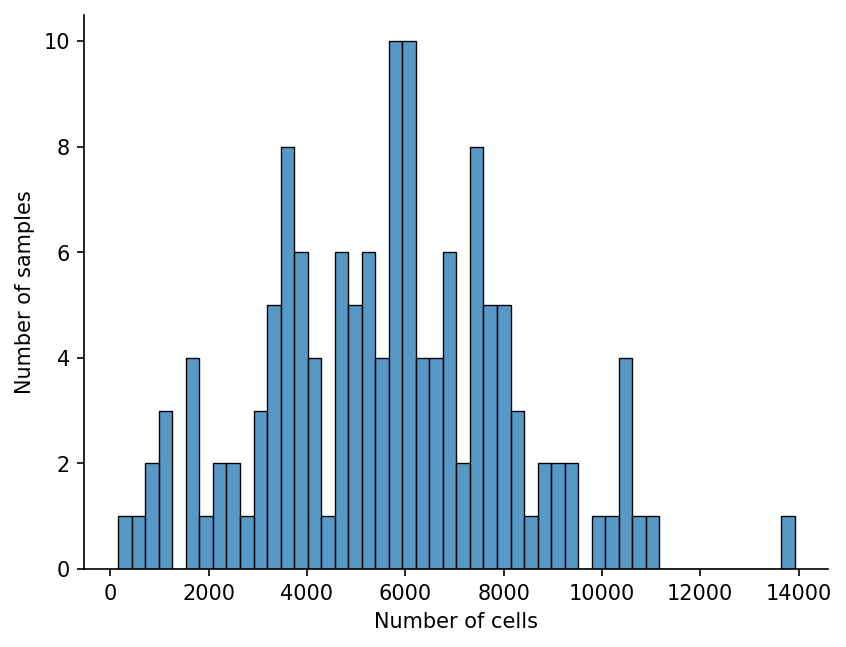

In [13]:
sns.histplot(dd.obs["n_cells"], bins=50)
sns.despine()
plt.xlabel("Number of cells")
plt.ylabel("Number of samples");

It is unlikely that a hundred cells is enough to obtain information about the sample, so we'll filter out samples with too few cells. Filtering `dd` removes these samples together with their cells:

In [14]:
dd.filter_donors_by_cells(200, inplace=True)
print(f"{dd.n_donors} samples with {dd.n_cells} cells left")

137 samples with 783516 cells left


If necessary, we can also remove cell types with too few cells in at least one sample:

`adata_filtered = patpy.pp.filter_small_cell_groups(dd.C, sample_key=sample_key, cell_group_key=cell_type_key, cluster_size_threshold=10)`

This typically leads to filtering out a lot of cell types, especially not very abundant ones. Some methods require this filtering step prior to building representation, but in this notebook we'll focus on simpler methods that can be used with only sample filtering.

## Simple sample representation baseline — Pseudobulk

Pseudobulk is the simplest sample representation: average every cell of a sample into a single vector. It can be interpreted as an "average cell" per sample. As simple as it is, pseudobulk is often a strong baseline. `patpy` provides a convenient interface to quickly run it.

But which cell representations should we use? In the literature, there is an inconsistency: some people prefer using gene expression, while other use latent features of the cells produced by dimensionality reduction methods. We can quickly test different cell representations by changing `layer` parameter

In [15]:
# Set up the sample representation method
pseudobulk_gene_expression = patpy.tl.Pseudobulk(
    sample_key=sample_key,
    cell_group_key=cell_type_key,  
    layer="X"  # Use adata.X that currently contains log-normalised expression
)
pseudobulk_gene_expression.prepare_anndata(dd)  # Prepare data, sample-level metadata is taken from dd
pseudobulk_gene_expression.calculate_distance_matrix(force=True);  # Compute sample representation

Per sample pseudobulks can now be accessed from the object:

In [16]:
pseudobulk_gene_expression.sample_representation

array([[2.54793704e-04, 3.14988256e-01, 5.89412563e-02, ...,
        0.00000000e+00, 2.26958580e-02, 2.64485143e-02],
       [1.94602209e-04, 2.48766482e-01, 3.78837250e-02, ...,
        1.02483413e-04, 1.35264704e-02, 4.66285180e-03],
       [0.00000000e+00, 3.26767832e-01, 3.02075539e-02, ...,
        1.73602253e-04, 4.16745022e-02, 3.90029140e-02],
       ...,
       [0.00000000e+00, 2.97079384e-01, 2.65128575e-02, ...,
        3.93834617e-03, 4.49549593e-02, 1.03619576e-01],
       [0.00000000e+00, 1.88556385e+00, 4.34419028e-02, ...,
        0.00000000e+00, 2.50585377e-02, 3.98881622e-02],
       [0.00000000e+00, 2.63987541e-01, 2.01169942e-02, ...,
        0.00000000e+00, 9.28884372e-03, 0.00000000e+00]],
      shape=(137, 3000))

To pseudobulk a different layer, simply change the `layer` argument. `patpy` will take the data from a corresponding layer or `.obsm` slot. Additionally, `.calculate_distance_matrix` supports different aggregation functions (such as "sum" or "median") and distance types, but changing them does not affect representations much.

In [17]:
pseudobulk_pca = patpy.tl.Pseudobulk(sample_key=sample_key, cell_group_key=cell_type_key, layer="X_pca")
pseudobulk_pca.prepare_anndata(dd)
pseudobulk_pca.calculate_distance_matrix(force=True);

Let's try pseudobulking the latent space, and keep track of runtime to further compare it with other methods:

In [18]:
_t0 = _time.time()

pseudobulk_scvi = patpy.tl.Pseudobulk(sample_key=sample_key, cell_group_key=cell_type_key, layer="X_scVI_batch")
pseudobulk_scvi.prepare_anndata(dd)
pseudobulk_scvi.calculate_distance_matrix(force=True);

runtimes["combat"]["pseudobulk"] = _time.time() - _t0

It is convenient to store representations together with the sample metadata, similarly to single-cell data. Every method can write its results into `dd`: the sample representation into `dd.obsm`, the sample distance matrix into `dd.obsp`, and 2D embeddings such as UMAP into `dd.obsm`. Results are matched to samples by name, so samples left out by a method get missing values instead of shifting the order.

For sample-level analysis, it is handy to have pseudobulk gene expression in `.X`, metadata in `.obs` and sample representations in `.obsm`, as in an [anndata](https://anndata.readthedocs.io/en/latest/) object. We get exactly this by using pseudobulk gene expression as the sample-level data of `dd`. We'll call it `meta_adata`. Because it is part of `dd`, it stays in sync with everything we store later:

In [19]:
dd.D = dd.pseudobulk(func="mean")  # Mean of adata.X per sample, with the sample table as .obs
meta_adata = dd.D
meta_adata

AnnData object with n_obs × n_vars = 137 × 3000
    obs: 'scRNASeq_sample_ID', 'Source', 'Outcome', 'Death28', 'Institute', 'Pool_ID', 'Age', 'median_QC_ngenes', 'median_QC_pct_mitochondrial', 'median_QC_scrub_doublet_scores', 'n_cells'
    var: 'gene_ids', 'feature_types', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    obsm: 'cell_type_fractions'

Let's define a small function that computes a UMAP of the samples and stores all results of a method in `dd`. Neighbor graphs needed for the trajectory analysis below are computed from the stored distances when they are first used:

In [20]:
import numpy as np
import scanpy as sc

In [21]:
def store_representation(method, method_name):
    """Store sample representation, distances and UMAP of a method in dd"""
    method.embed("UMAP")
    method.to_donordata(method_name, donor_data=dd)

In [22]:
store_representation(pseudobulk_gene_expression, "Pseudobulk_expression")

Representations can now easily be visualised using non-linear dimensionality reduction methods (such as UMAP). Note that every point on the plots below means *one sample* (i.e., patient ot a donor):

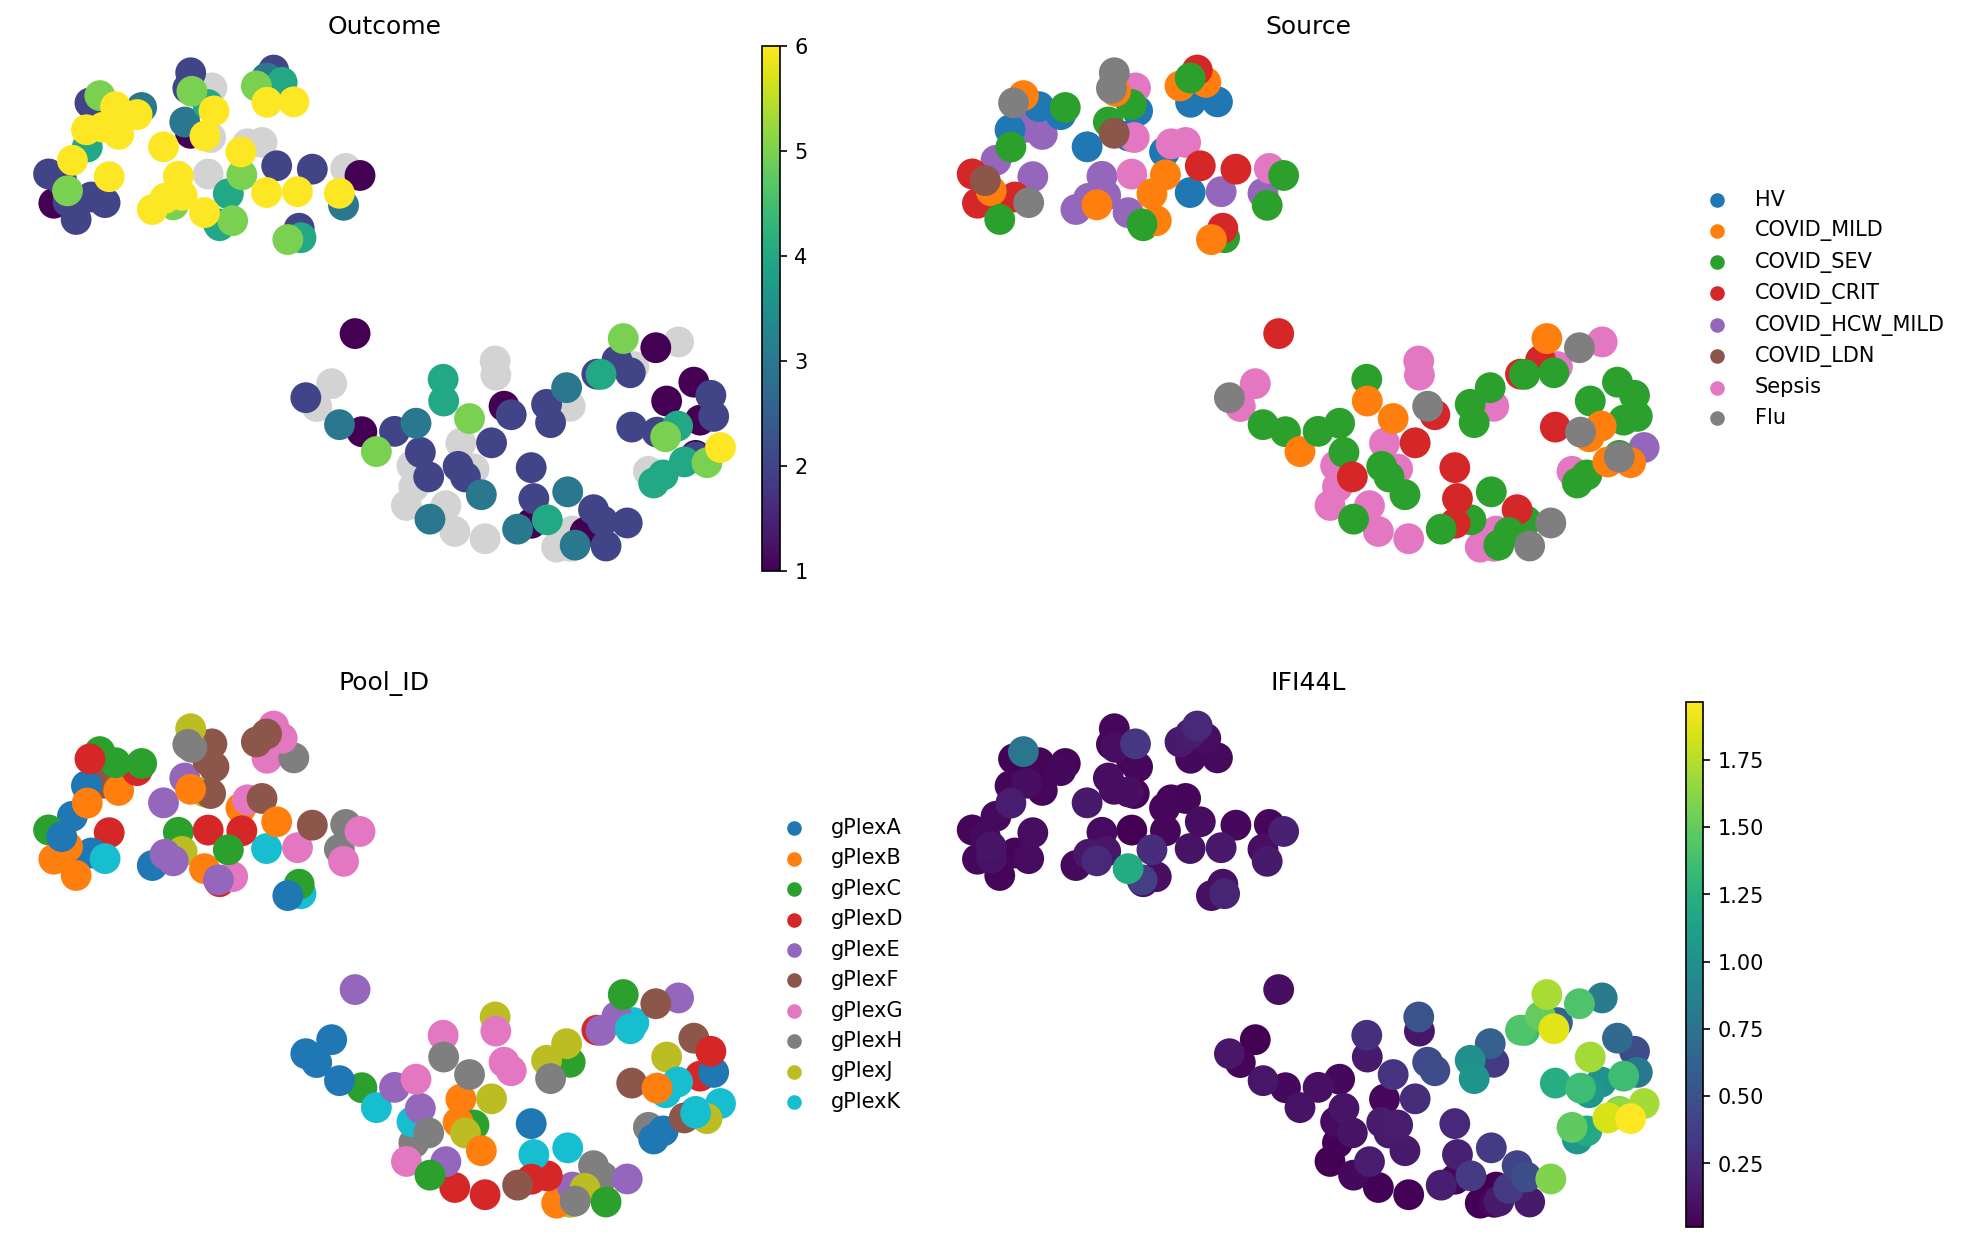

In [23]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_Pseudobulk_expression", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],  # Both metadata columns and gene expression can be visualised. IFI44L is a COVID-19 marker
    frameon=False,
    ncols=2
)


The "Outcome" plot in the top left reflects different severities of COVID-19. It decodes the following:
```
1 = Death
2 = Intubated, ventilated
3 = Non-invasive ventilation
4 = Hospitalized, O2
5 = Hospitalized, no O2
6 = Not hospitalized
```

We can see that people with outcome 6 are mostly close to each other, which is a good sign. Source plot shows a similar story, but additionally shows Flu and Sepsis samples. Pool ID doesn't show grouping, which is good news because this is a batch covariate.

We can define more intuitive palettes and store them in `.uns` for consistent coloring across methods:

In [24]:
meta_adata.obs["Source"].cat.categories

Index(['HV', 'COVID_MILD', 'COVID_SEV', 'COVID_CRIT', 'COVID_HCW_MILD',
       'COVID_LDN', 'Sepsis', 'Flu'],
      dtype='object')

In [25]:
meta_adata.uns["Source_colors"] = [
    "#1f77b4",  # HV
    "#ff9999",  # COVID_MILD
    "#ff4c4c",  # COVID_SEV
    sns.color_palette("Reds")[-1],  # COVID_CRIT
    "skyblue", # COVID_HCW_MILD
    "darkgrey", # COVID_LDN
    "#8c564b",  # Sepsis
    "#ff7f0e",  # Flu
]

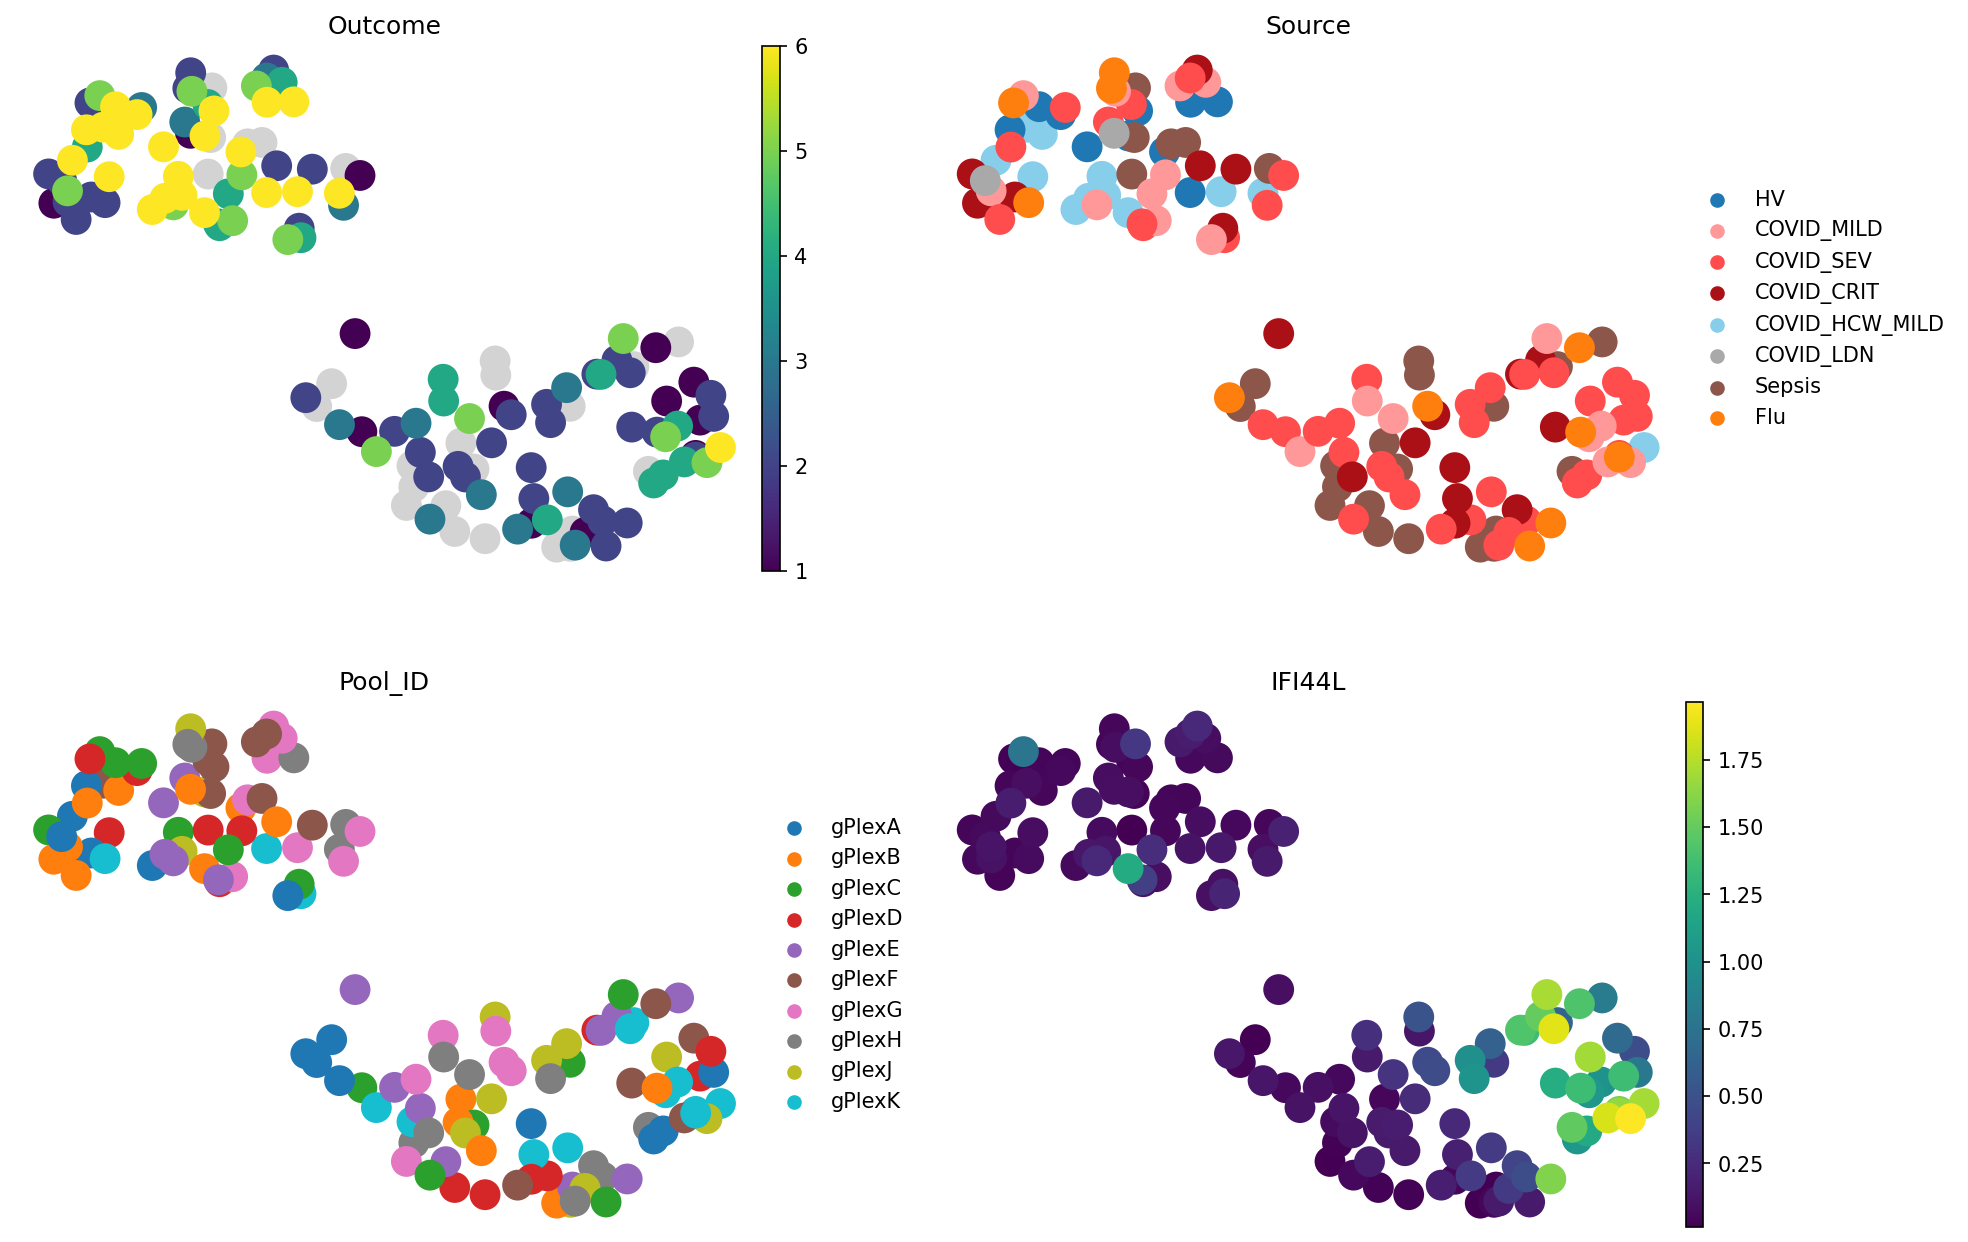

In [26]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_Pseudobulk_expression", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


Let's see what PCA-based representation shows us:

In [27]:
store_representation(pseudobulk_pca, "Pseudobulk_PCA")

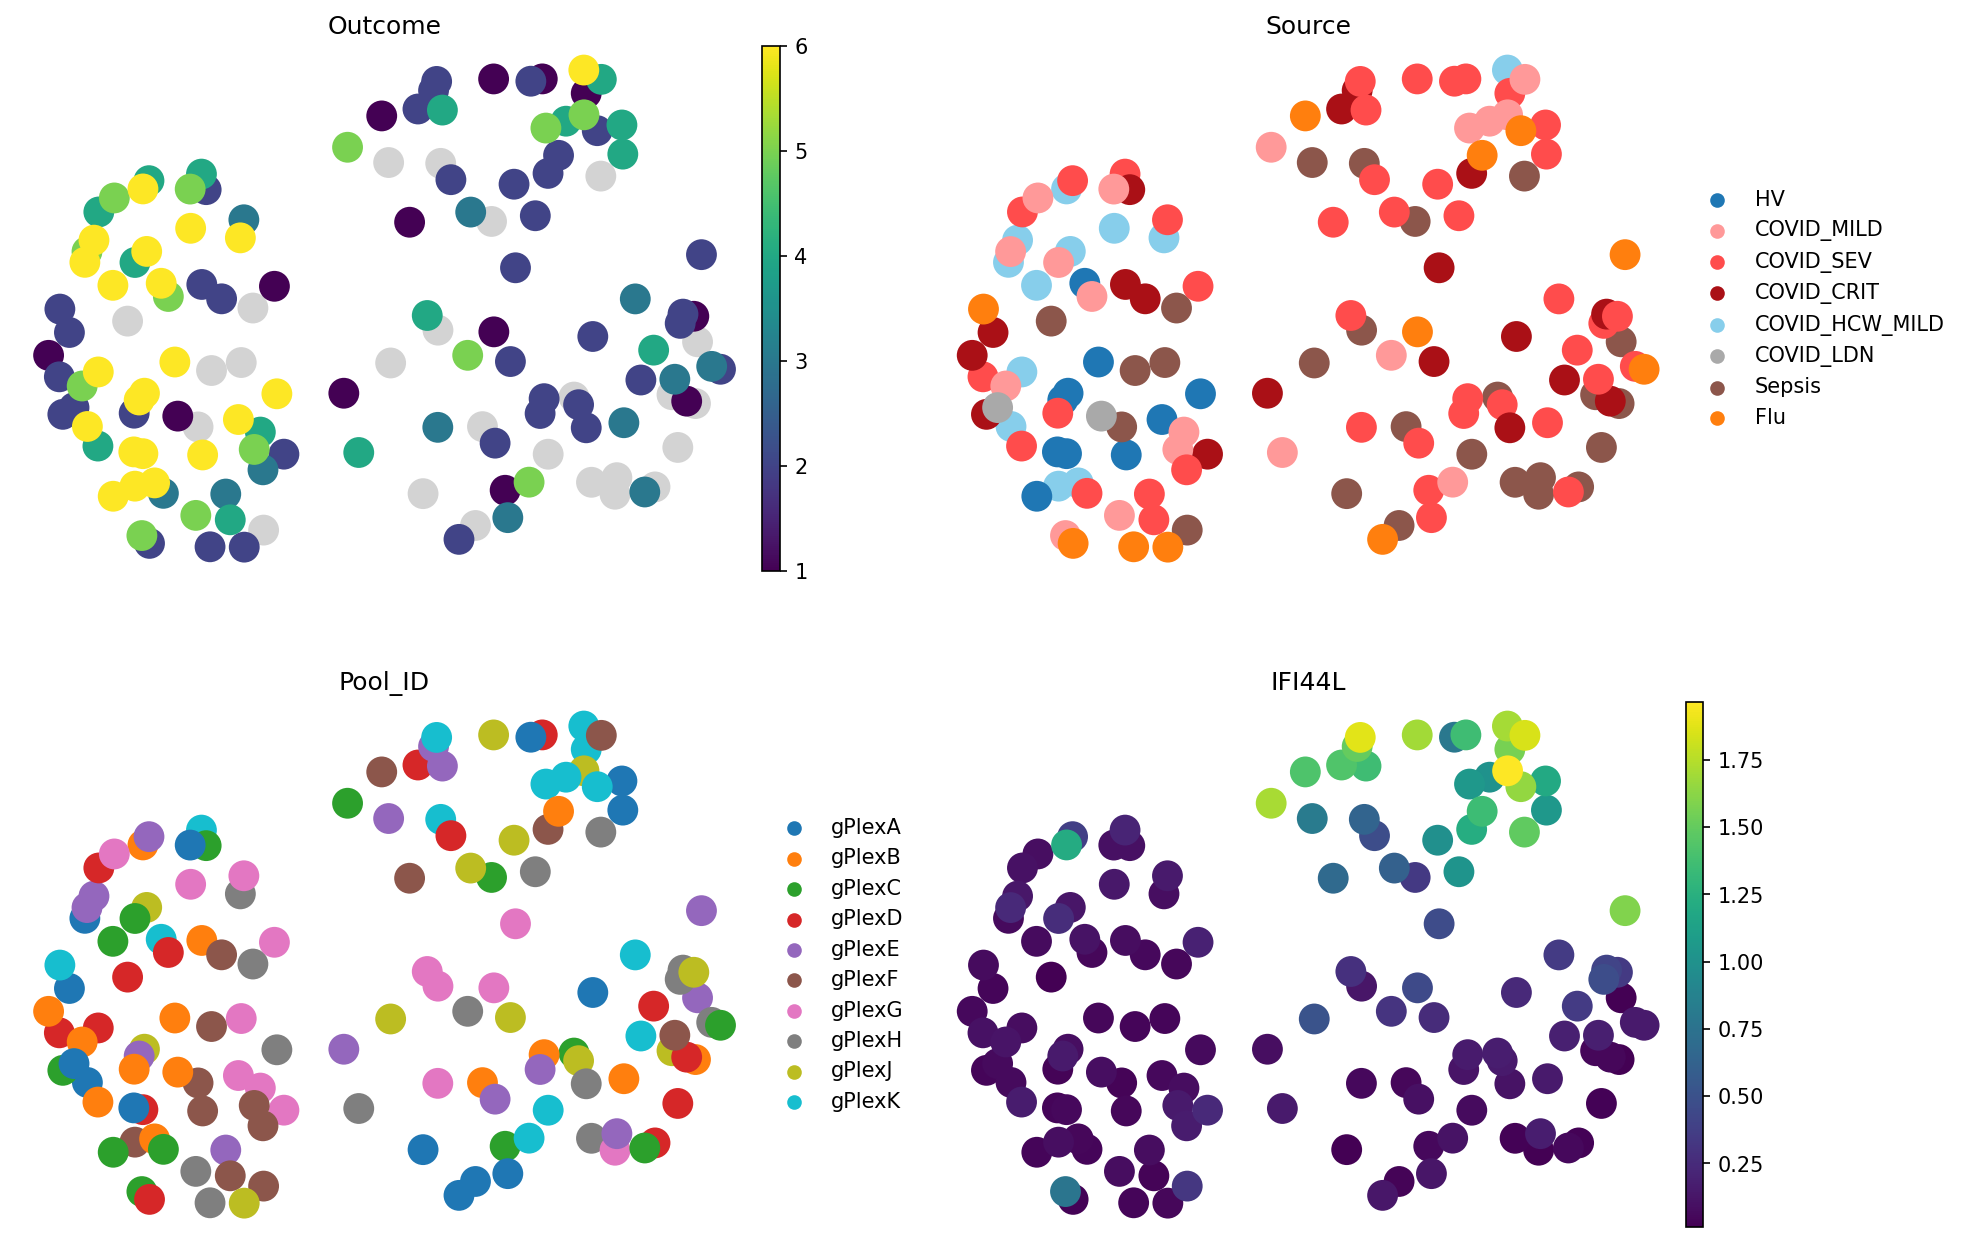

In [28]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_Pseudobulk_PCA", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


PCA-based representations tell a similar story. What about scVI?

In [29]:
store_representation(pseudobulk_scvi, "Pseudobulk_scVI")

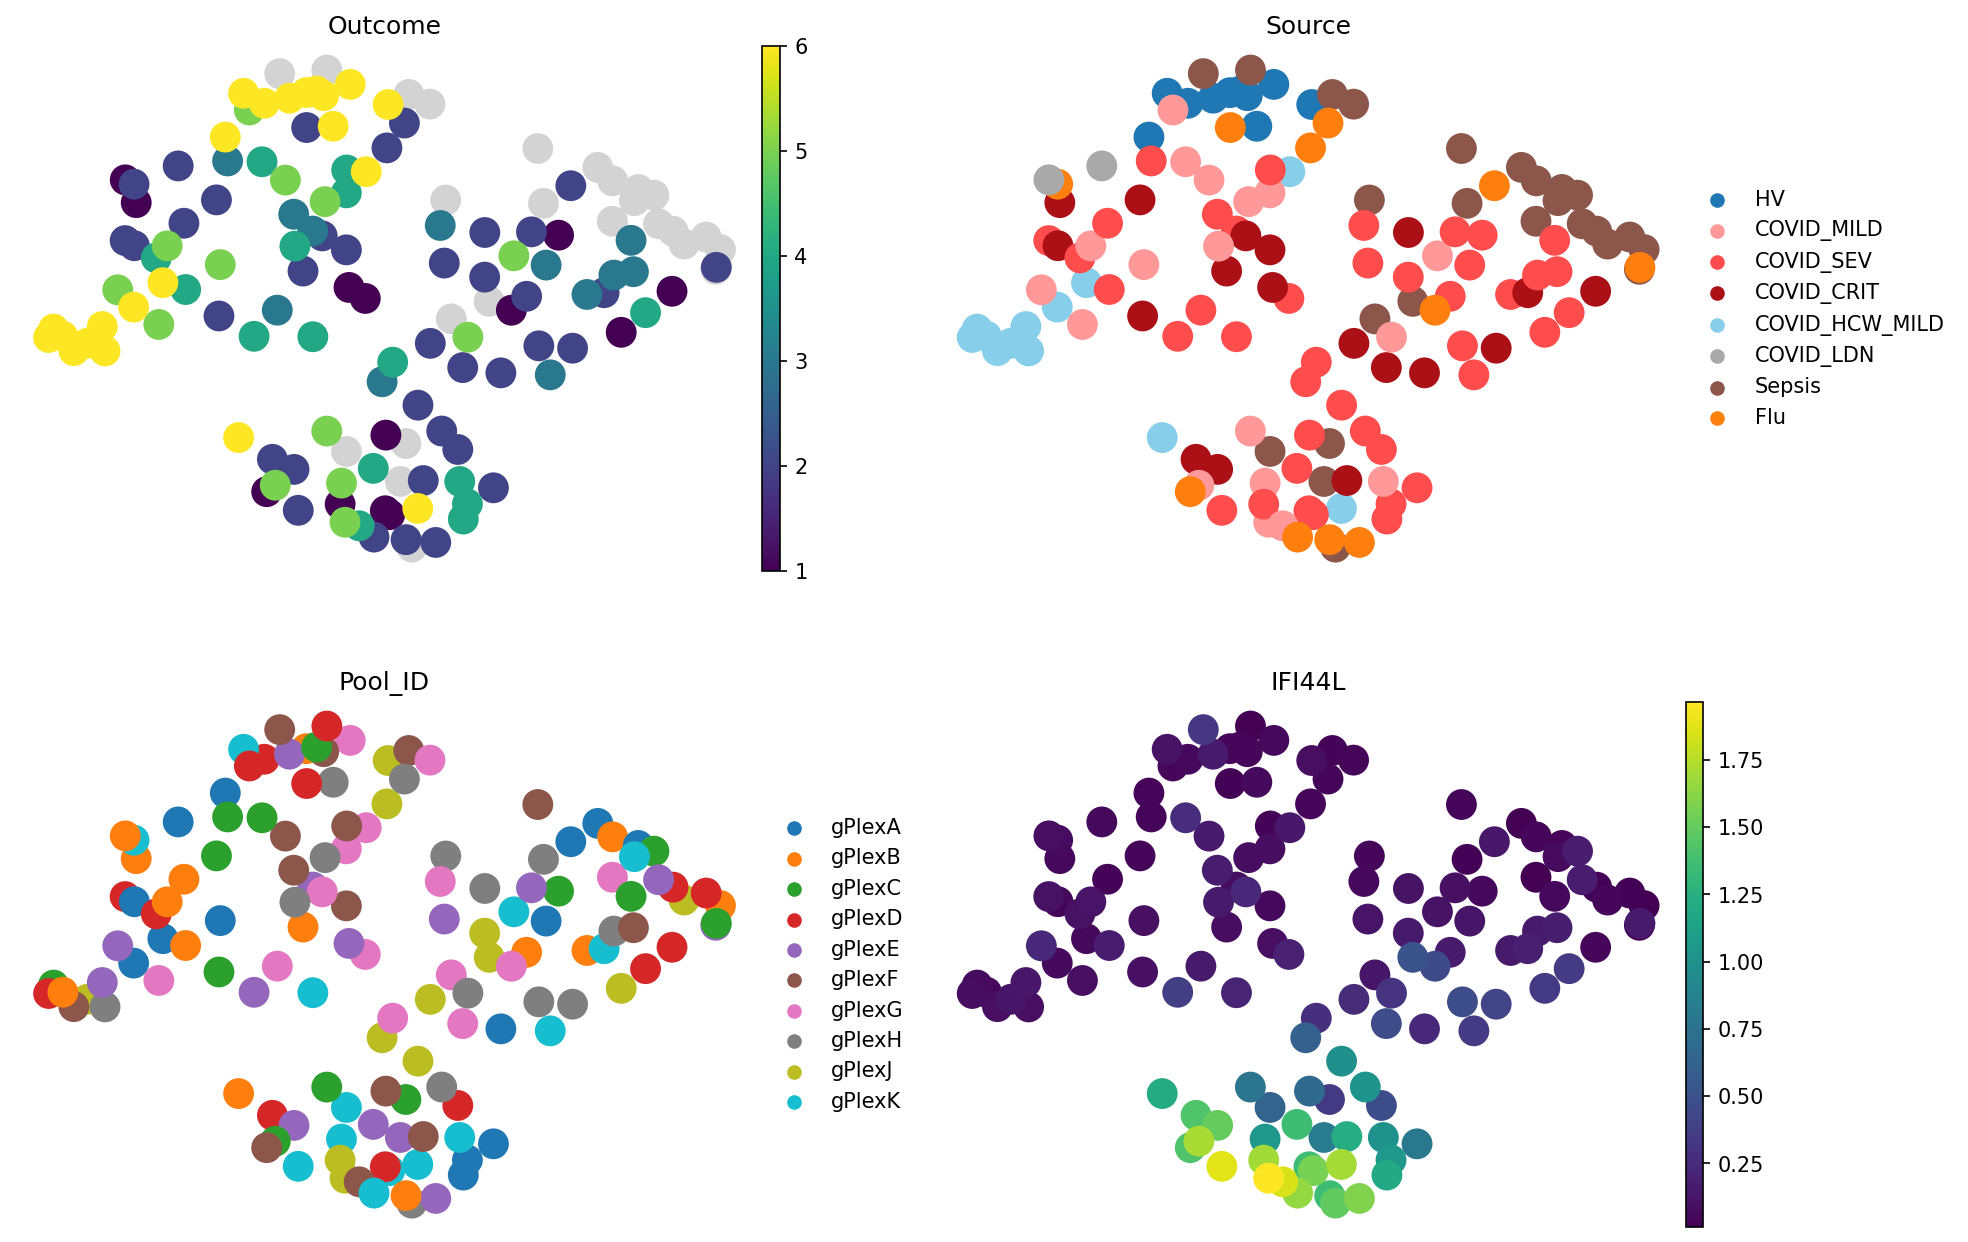

In [30]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_Pseudobulk_scVI", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


Here, we can notice a better grouping of Sources (e.g. Sepsis, and healthy) as well as the outcomes. Interestingly, outcome 6 (not hospitalised) now splits into 2 groups. On the Source plot, we can see that they correspond to different groups: HV (healthy volunteers) and "COVID_HCW_MILD", which encodes healthcare workers dealing with COVID-19 patients. The Pool ID plot shows that these samples come from diverse batches, so the difference is likely biological rather than technical. Immune system of healthcare workers exposed to COVID-19 contains slightly different signture, which is consistently captured by pseudobulking in scVI space, but not in PCA or gene expression.

Long story short, **data preprocessing matters** for sample representations. With good cell embeddigns, such as scVI, even the simplest methods can uncover patient diversity.

But let's stop staring on the UMAPs and compute some metrics. 2D visualisations of complex data give you some hint on what it's hiding, but should never be overinterpreted.

# Evaluating biological information retention and batch mixing in sample representations

What do we expect from a good sample representation? Briefly, we want biologically similar samples to be close to each other in sample representation space. At the same time, we don't want similarity to be explained by batch effects. We previously proposed evaluating both points with k nearest neighbors (KNN)-based prediction:

![knn_metrics](images/benchmarking_tutorial/knn_metrics.jpg)

Approach is simple: predict each covariate from the most similar samples. Evaluate how well it corresponds to true values. For biological covariates, report the prediction quality. For technical, inverse it so that 1 corresponds to perfect mixing, and 0 corresponds to perfect batch prediction.

`patpy` provides a simple interface to these metrics. Let's see how well we can predict the outcome from pseudobulk representations:

In [31]:
pseudobulk_gene_expression.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="classification")

{'score': np.float64(0.1958570399511462),
 'metric': 'f1_macro_calibrated',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

Here, we can see that based on 5 most similar samples, Outcome cannot be predicted so well. For the classification task, $F_1$-macro score is used. This metrics weighs each class equally. It is also calibrated for random prediction so that 0 means that the prediction score is as good as throwing random classes, and 1 means perfect prediction.

Outcome in our data is, however, encoded numerically. We might want to use this information. For example, if the most similar samples have outcome values `[6, 6, 6, 4, 4]`, predicting `5` is much better than predicting `1`. Let's change the prediction task from `classification` (requiring the exact prediction of the class) to `ranking`, which takes into accout how far the prediction was from the correct class:

In [32]:
pseudobulk_gene_expression.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.5822470283432646),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

We can see that prediction is not that terrible. Note that the metric changed to Spearman correlation. Interpretation is the same: 0 means poor prediction while 1 would correspond to a perfect ranking of outcomes.

Now let's see how well samples Pool is represented. This is a technical covariate so we don't want score to be high:

In [33]:
pseudobulk_gene_expression.evaluate_representation(target="Pool_ID", method="knn", n_neighbors=5, task="classification")

{'score': np.float64(0.24192529778333363),
 'metric': 'f1_macro_calibrated',
 'n_unique': 10,
 'n_observations': 137,
 'method': 'knn'}

The value is quite low, so the batch effect does not strongly affect this representation. 

We can also test whether continuous covatiates, such as the number of cells drive the representation. For this, use the `regression` task. The number of cells is not a column of `adata.obs`, but because the method was prepared with `dd`, it is found in the sample table:

In [34]:
pseudobulk_gene_expression.evaluate_representation(
    target="n_cells", 
    method="knn", 
    n_neighbors=5, 
    task="regression"
)

{'score': np.float64(0.2638191423824369),
 'metric': 'spearman_r',
 'n_unique': 137,
 'n_observations': 137,
 'method': 'knn'}

Good news, the number of cells affects the sample representations much less than the outcome!

We can now see which input space better captures biology and is more resistant to batch effects:

In [35]:
scores = []

for method, input_space in zip([pseudobulk_gene_expression, pseudobulk_pca, pseudobulk_scvi], ["expression", "PCA", "scVI"]):
    outcome_score = method.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")["score"]
    n_cells_score = method.evaluate_representation(target="n_cells", method="knn", n_neighbors=5, task="regression")["score"]
    # Inverse technical score
    n_cells_score = 1 - n_cells_score
    scores.append([input_space, outcome_score, n_cells_score])

input_space_results = pd.DataFrame(scores, columns=["Input space", "Outcome prediction", "#cells mixing"])
input_space_results

,Input space,Outcome prediction,#cells mixing
0,expression,0.582247,0.736181
1,PCA,0.575498,0.725148
2,scVI,0.612422,0.647115


<Axes: xlabel='Outcome prediction', ylabel='#cells mixing'>

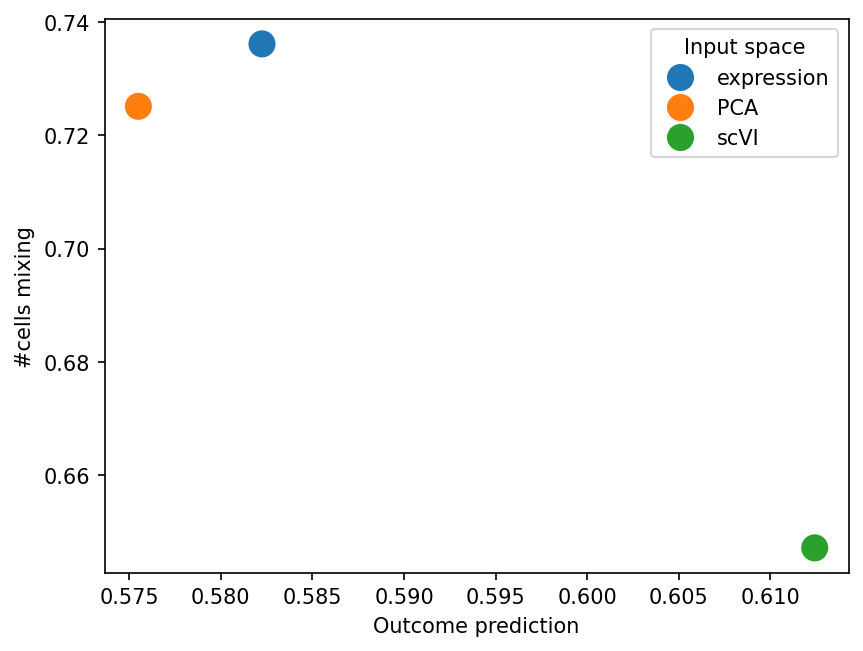

In [36]:
sns.scatterplot(input_space_results, x="Outcome prediction", y="#cells mixing", hue="Input space", s=200)

The results are not drastically different, but scVI captures Outcome slightly better. Note, however, that it is also affected by the number of cells.

Silhouette score, another commonly used metric, is also supported by `patpy`. However, it does not enable evaluating continuous or ranked covariates. Let's still see if it shows us the similar picture:

In [37]:
method.evaluate_representation(target="Pool_ID", method="silhouette")

{'score': -0.04922423646099549,
 'metric': 'silhouette',
 'n_unique': 10,
 'n_observations': 137,
 'method': 'silhouette'}

In [38]:
silhouette_scores = []

for method, input_space in zip([pseudobulk_gene_expression, pseudobulk_pca, pseudobulk_scvi], ["expression", "PCA", "scVI"]):
    outcome_score = method.evaluate_representation(target="Outcome", method="silhouette")["score"]
    pool_id_score = method.evaluate_representation(target="Pool_ID", method="silhouette")["score"]
    silhouette_scores.append([input_space, outcome_score, pool_id_score])

input_space_silhouette_results = pd.DataFrame(silhouette_scores, columns=["Input space", "Outcome clustering", "Pool clustering"])
input_space_silhouette_results

,Input space,Outcome clustering,Pool clustering
0,expression,-0.078705,-0.056767
1,PCA,-0.085367,-0.070996
2,scVI,-0.057449,-0.049224


<Axes: xlabel='Outcome clustering', ylabel='Pool clustering'>

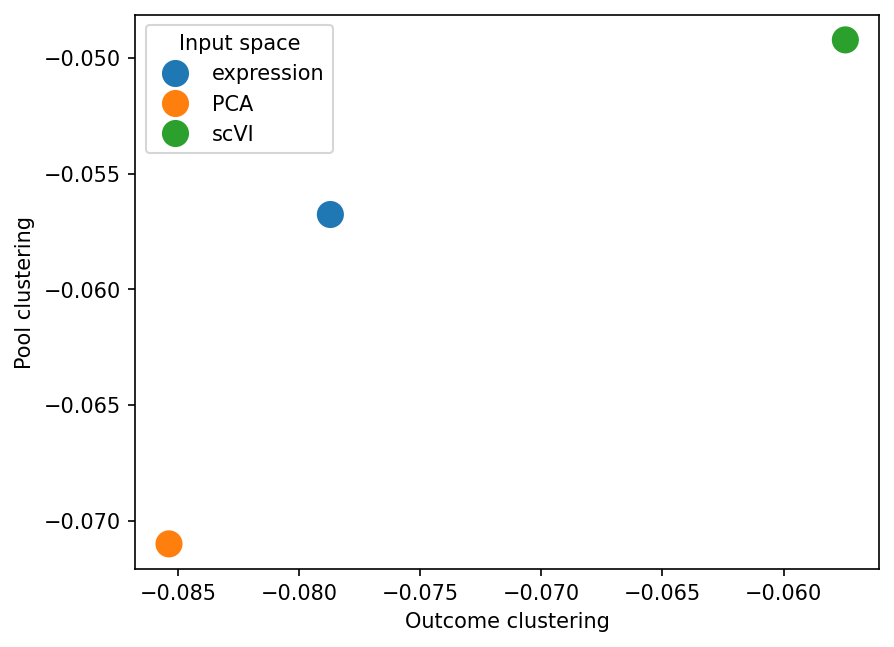

In [39]:
sns.scatterplot(input_space_silhouette_results, x="Outcome clustering", y="Pool clustering", hue="Input space", s=200)

Near 0 (and even slightly negative) silhouette metric values show us that both outcome and pools are not separated in the sample representation. This is expected from what we saw on UMAPs: groups mix a lot rather that showing completely separate clusters. It does not, however, mean that pseudobulk representations do not reflect biology. As we saw from kNN-based metrics, the representations are locally meningful and enable prediction of clinical covariates, such as the outcome.

Let's use another metric to see if COVID-19 severity is preserved in sample representations.

# Evaluating trajectory preservation in sample representations

Besides *local* predictability of sample representations, we also want sample embeddings to have a meaningful *global* structure. When there is a ground truth trajectory in our data, such as disease severity, we can evaluate if samples are ordered correspondingly to this trajectory:

![trajectory_preservation](images/benchmarking_tutorial/trajectory_preservation.png)

First, we need to set a "root sample" – the beginning of our trajectory. The youngest control donor is a reasonable choice:

In [40]:
dd.obs["Age"]

scRNASeq_sample_ID
G05061-Ja005E-PBCa    5.0
G05064-Ja005E-PBCa    5.0
G05073-Ja005E-PBCa    4.0
G05077-Ja005E-PBCa    4.0
G05078-Ja005E-PBCa    3.0
                     ... 
U00607-Ua005E-PBUa    4.0
U00613-Ua005E-PBUa    3.0
U00617-Ua005E-PBUa    6.0
U00619-Ua005E-PBUa    4.0
U00701-Ua005E-PBUa    5.0
Name: Age, Length: 137, dtype: float64

In [41]:
candidates = dd.obs.dropna(subset=["Outcome", "Age"])
root_sample = candidates.sort_values(["Outcome", "Age"], ascending=[False, True]).index[0]
print(
    f"Trajectory root: {root_sample} "
    f"(Outcome={dd.obs.loc[root_sample, 'Outcome']:.0f}, "
    f"Age={dd.obs.loc[root_sample, 'Age']:.0f}, "
    f"Source={dd.obs.loc[root_sample, 'Source']})"
)


Trajectory root: G05078-Ja005E-PBCa (Outcome=6, Age=3, Source=COVID_HCW_MILD)


In [42]:
trajectory_results = patpy.tl.trajectory_correlation(
    meta_adata=meta_adata,
    root_sample=root_sample,
    trajectory_variable="Outcome",
    representations=dd.uns["sample_representations"],
    inverse_trajectory=True,  # COMBAT codes 6 = healthy, 1 = critical, so we need to flip the sign for correlation with pseudotime
)
trajectory_results

Computing diffmap for Pseudobulk_expression


Computing diffmap for Pseudobulk_PCA
Computing diffmap for Pseudobulk_scVI


,correlation
Pseudobulk_expression,0.454022
Pseudobulk_PCA,0.450591
Pseudobulk_scVI,0.400080


We can see that expression-based pseudobulk captures trajectory even better. This is likely due to split between healthcare workers and healthy volunteers in scVI-based representation. We can visualise pseudotime to see it:

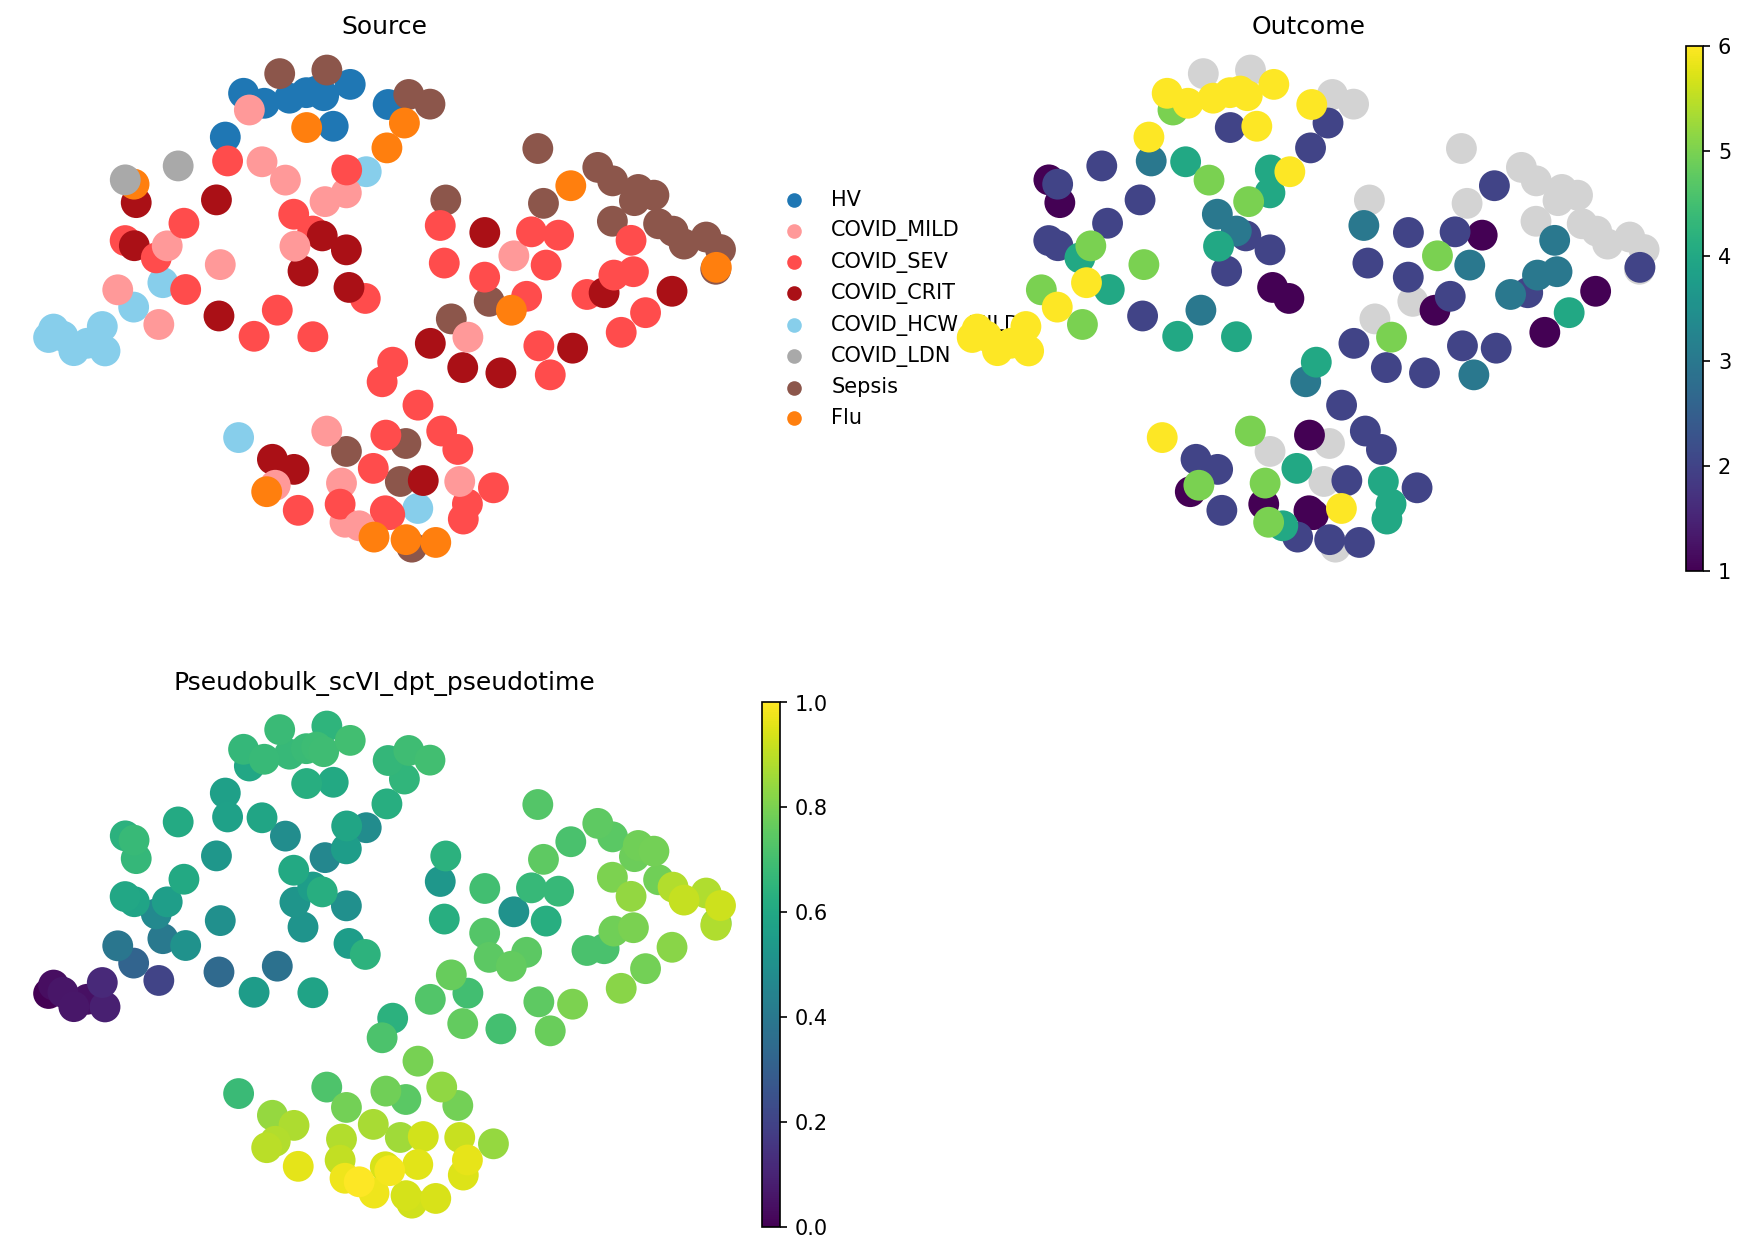

In [43]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_Pseudobulk_scVI", 
    color=["Source", "Outcome", "Pseudobulk_scVI_dpt_pseudotime"],
    frameon=False,
    ncols=2
)


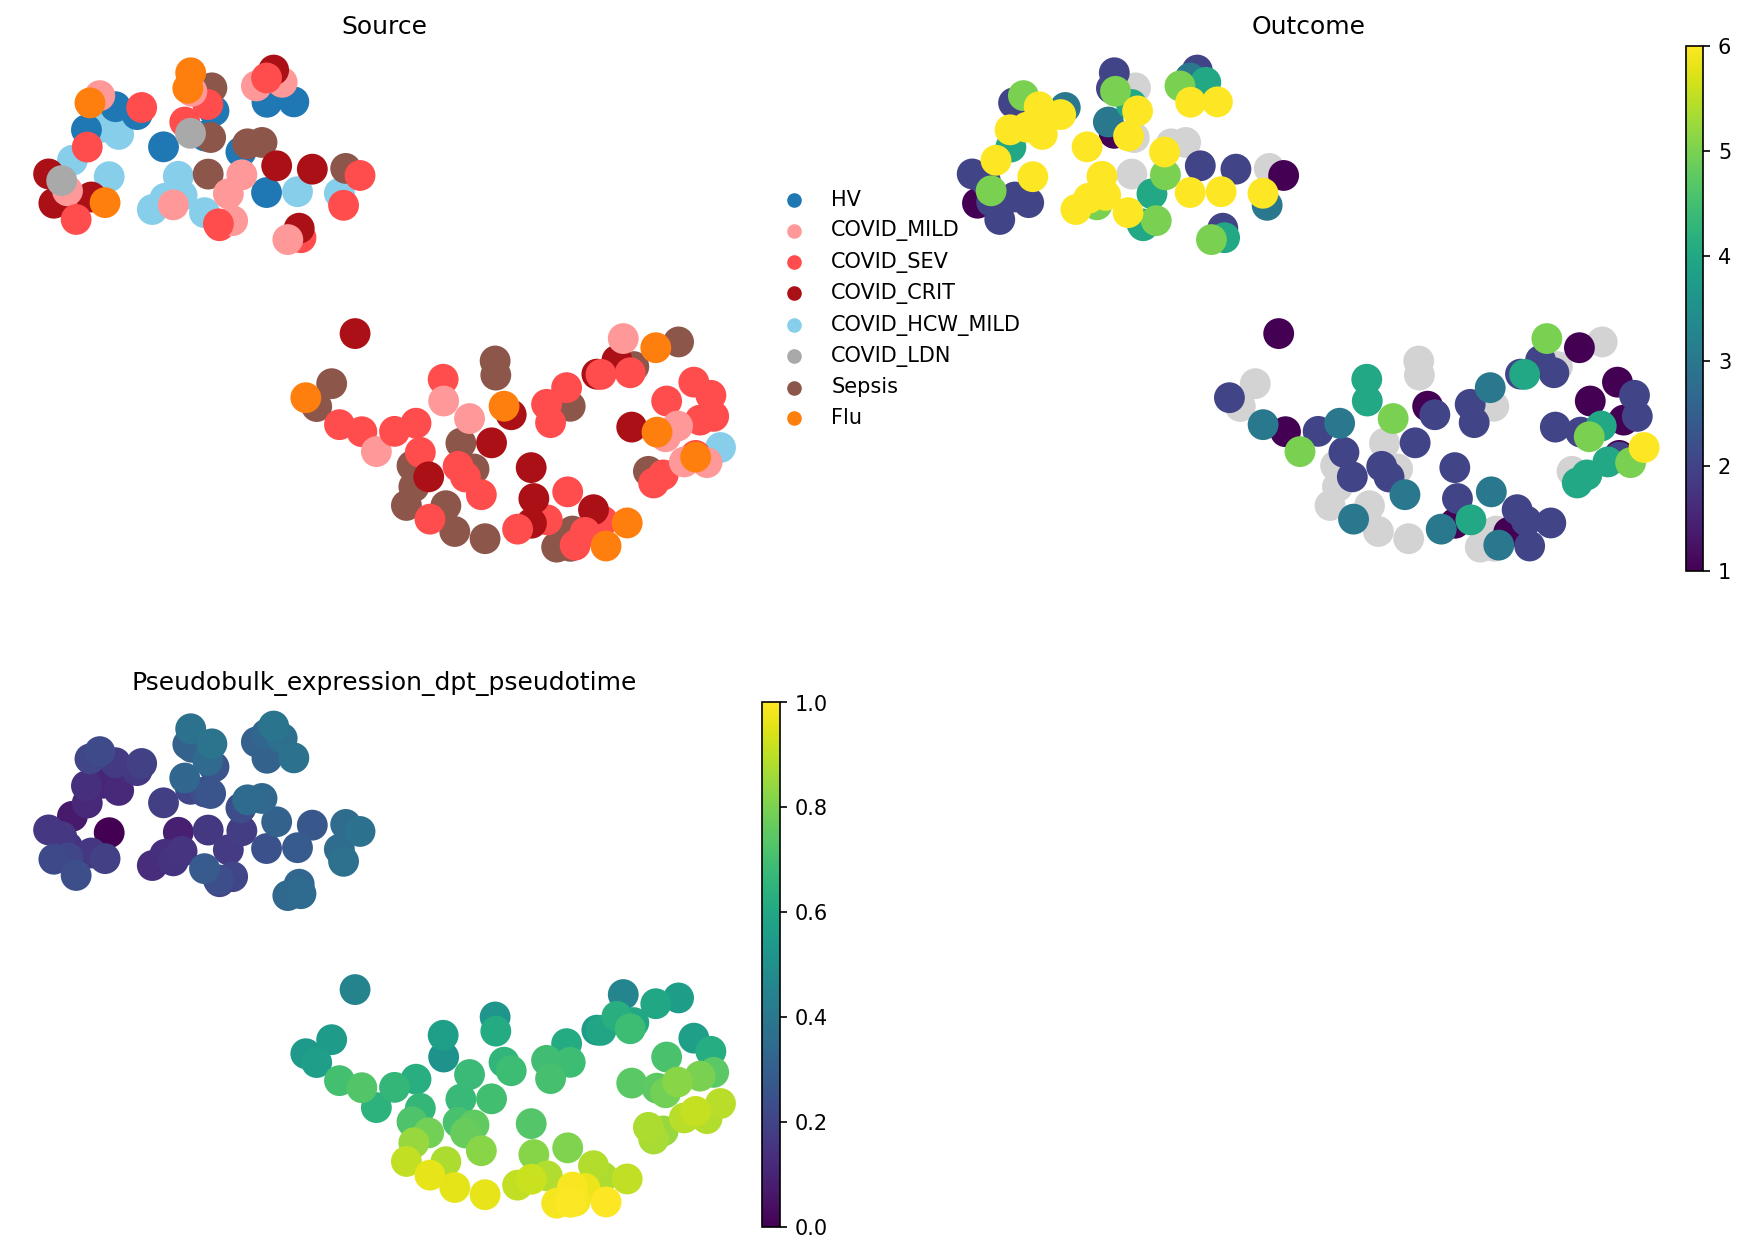

In [44]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_Pseudobulk_expression", 
    color=["Source", "Outcome", "Pseudobulk_expression_dpt_pseudotime"],
    frameon=False,
    ncols=2
)


Indeed, we see that in scVI-based embedding, pseudotime took a wrong turn to the healthy cluster, while expression-based pseudobulk groups all samples with the good outcome together. What's right and what's wrong depends on your research question. For modelling patient trajectories, expression-based embedding would be better, while for understanding COVID-19 response diversity, scVI shows a better picture

## Method 2 — Cell type composition


Another commonly used baseline representation is based on cell type composition differences. It is calculated as a difference between cell type proportions in each sample.

In [45]:
_t0 = _time.time()
composition = patpy.tl.CellGroupComposition(
    sample_key=sample_key, cell_group_key=cell_type_key,
)
composition.prepare_anndata(dd)
composition_distances = composition.calculate_distance_matrix(force=True)
runtimes["combat"]["composition"] = _time.time() - _t0

We can also visualise cell type proportions for each sample:

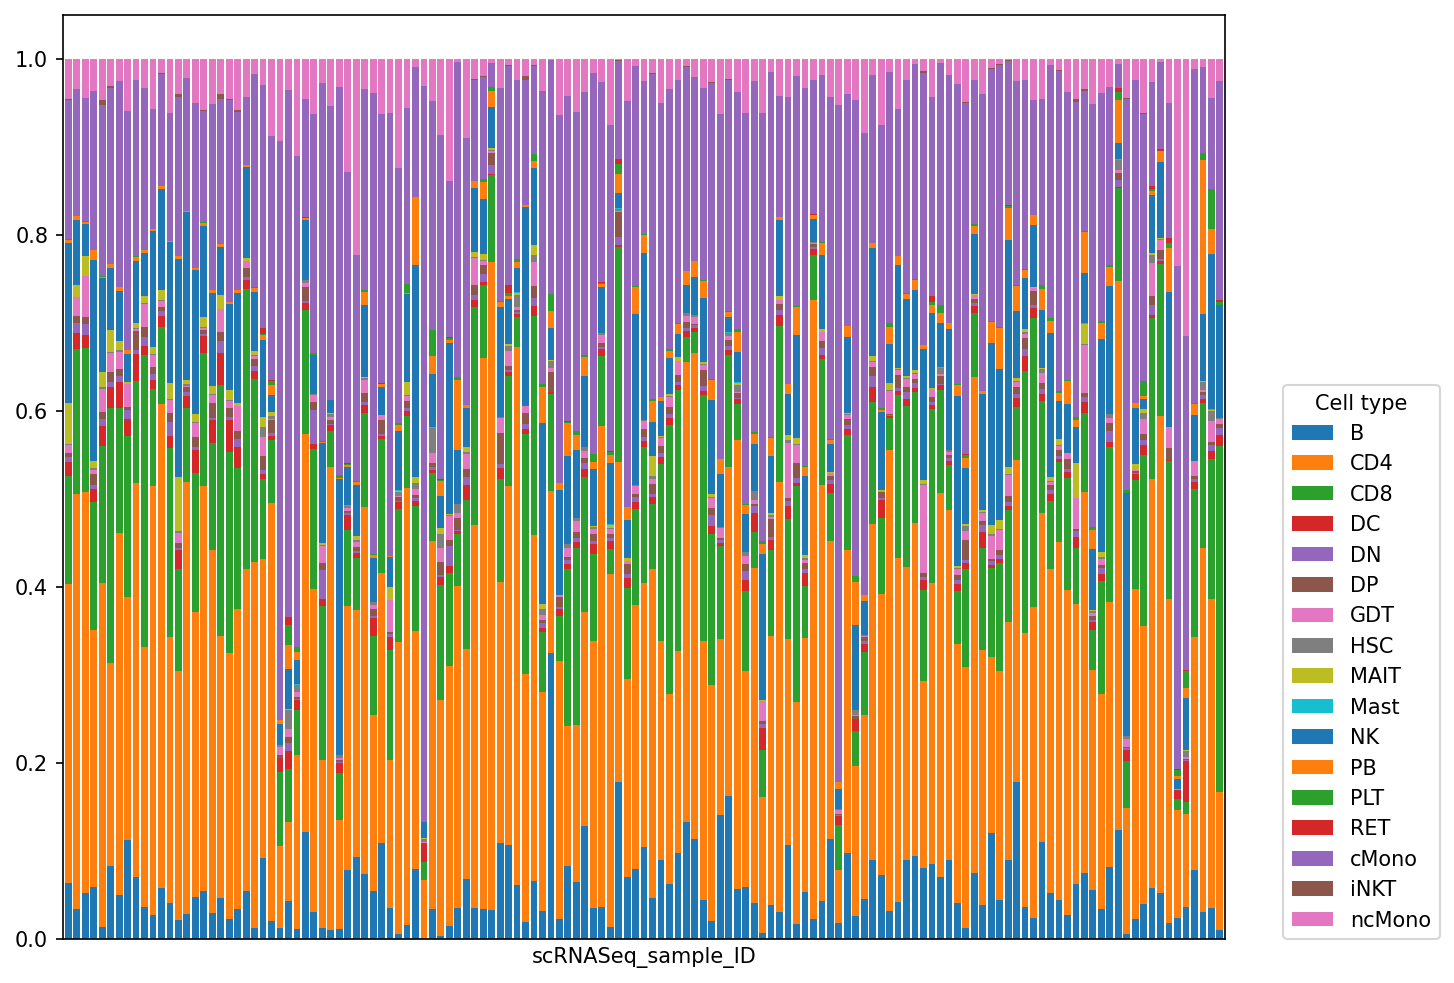

In [46]:
composition.sample_representation.plot(kind="bar", stacked=True, figsize=(10, 8), width=0.8)
plt.xticks([])
plt.legend(loc=(1.05, 0), title="Cell type");

In [47]:
store_representation(composition, "composition")

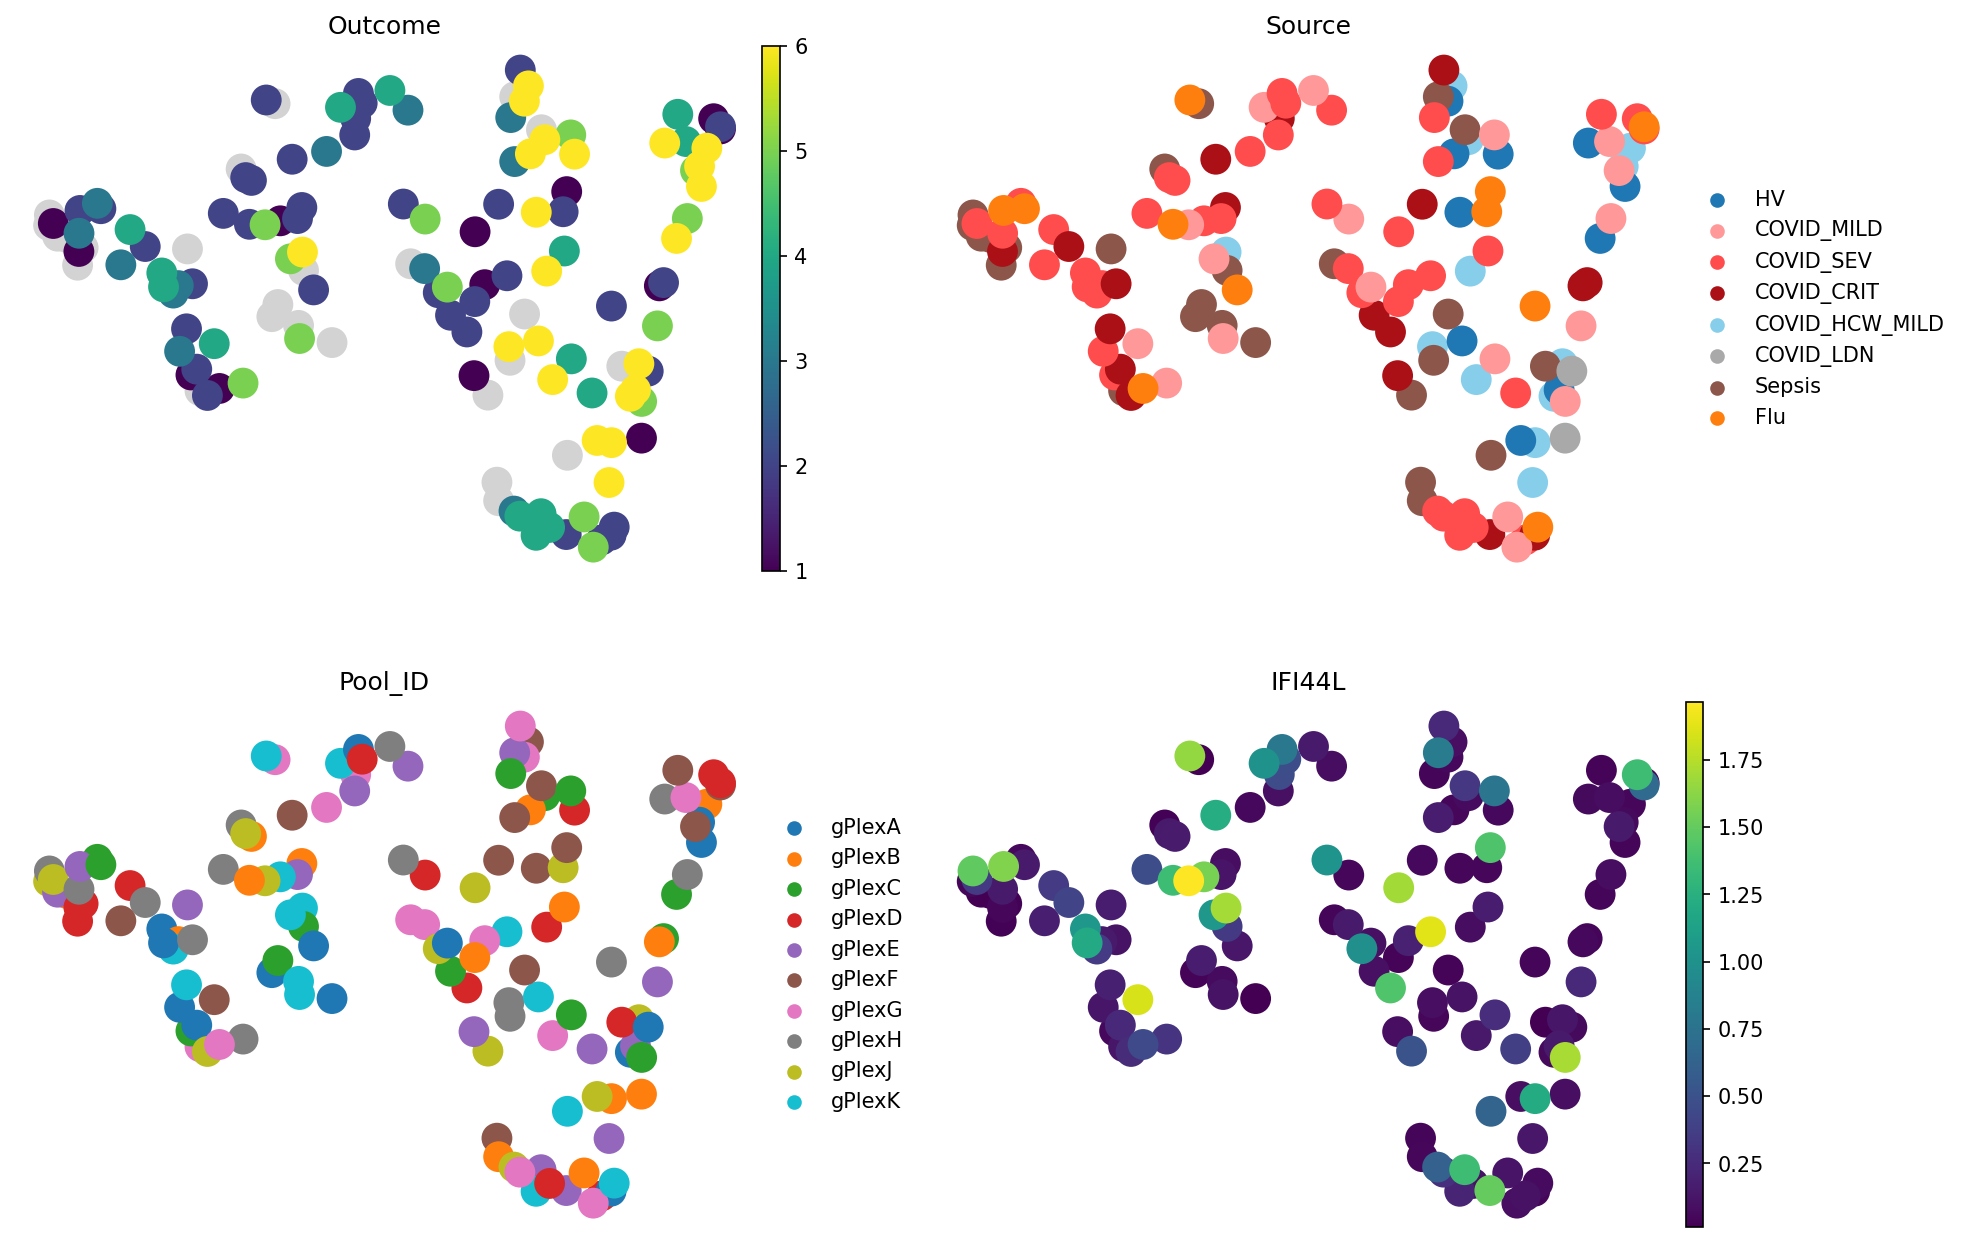

In [48]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_composition", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


We can see that cell type composition reflects patient outcome worse than pseudobulk:

In [49]:
composition.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.4786968063752981),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

However, a better way to compare samples based on compositional data is by applying centered log-ratio (CLR) transformation to the cell type composition. This approach is know in the sample representation literature as SETA or [scECODA](https://www.biorxiv.org/content/10.64898/2026.03.27.714811v1.full). `patpy` enables CLR transform with a single extra argument:

In [50]:
_t0 = _time.time()
composition_clr = patpy.tl.CellGroupComposition(
    sample_key=sample_key, cell_group_key=cell_type_key, 
    apply_clr=True # Transform proportions with centered log-ratio
)
composition_clr.prepare_anndata(dd)
composition_clr.calculate_distance_matrix(force=True)
runtimes["combat"]["composition_clr"] = _time.time() - _t0

In [51]:
store_representation(composition_clr, "composition_clr")

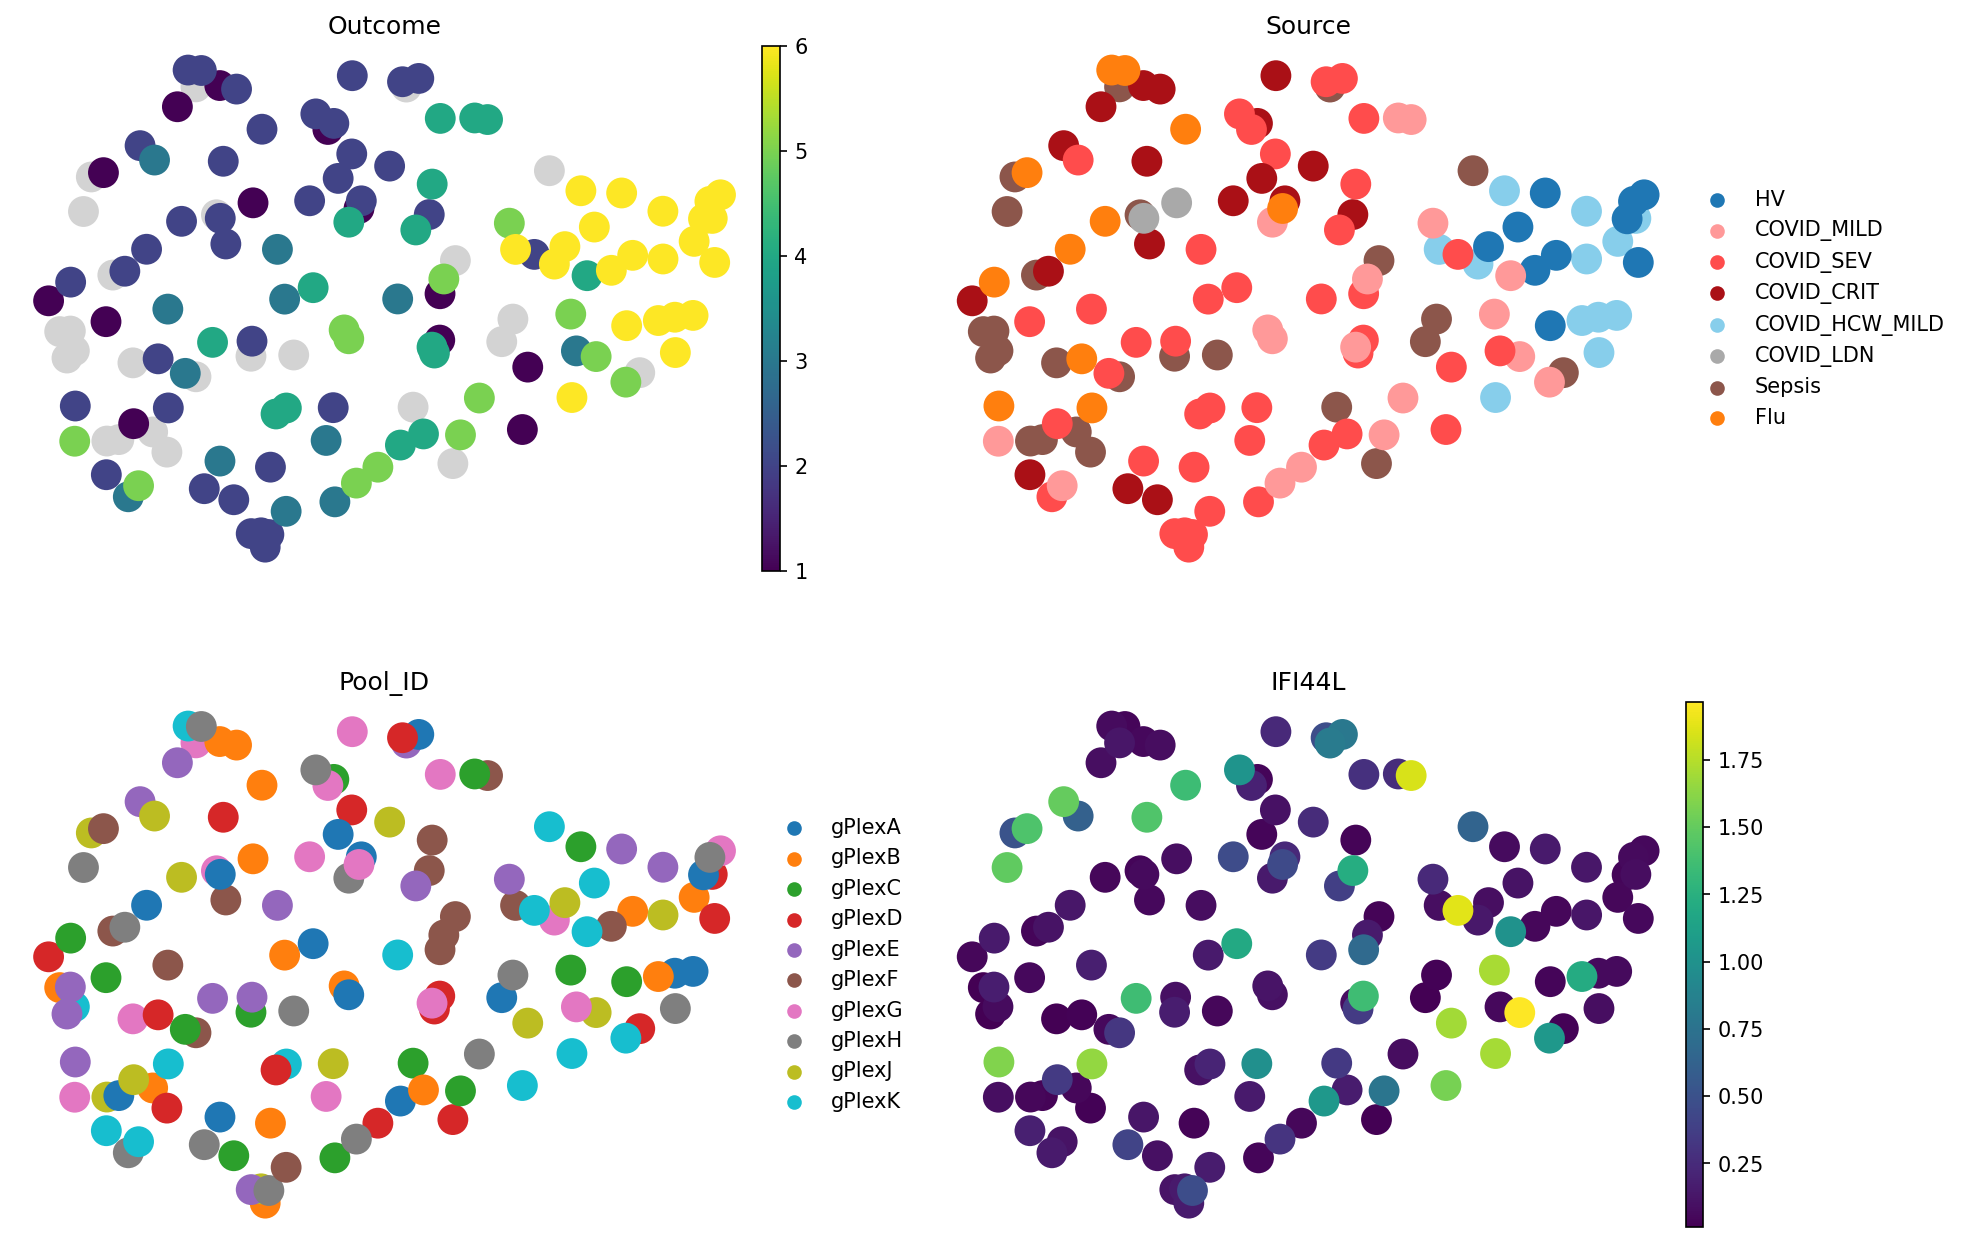

In [52]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_composition_clr", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


CLR-transformed cell type proportions give us the best representation we saw so far! Although, note how IFI44L gene expression gets distributed across the embedding. It makes sense as this method does not distinguish samples with same cell type proportions but different gene expression

In [53]:
composition_clr.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.6751412180597196),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

## Method 3 — PILOT


[PILOT](https://pubmed.ncbi.nlm.nih.gov/38177382/) is an Optimal Transport-based tool, which calculates distances between samples based on cell type proportion differences taking into account cell type similarities. Note that to run it, you need to install the dependencies additionally:

`pip install patpy[pilot]`

In [54]:
_t0 = _time.time()
pilot = patpy.tl.PILOT(
    sample_key=sample_key,
    cell_group_key=cell_type_key,
    layer="X_scVI_batch",
    sample_state_col="Outcome",  # not used for distance calculation
)
pilot.prepare_anndata(dd)
pilot.calculate_distance_matrix()
runtimes["combat"]["pilot"] = _time.time() - _t0
store_representation(pilot, "pilot")

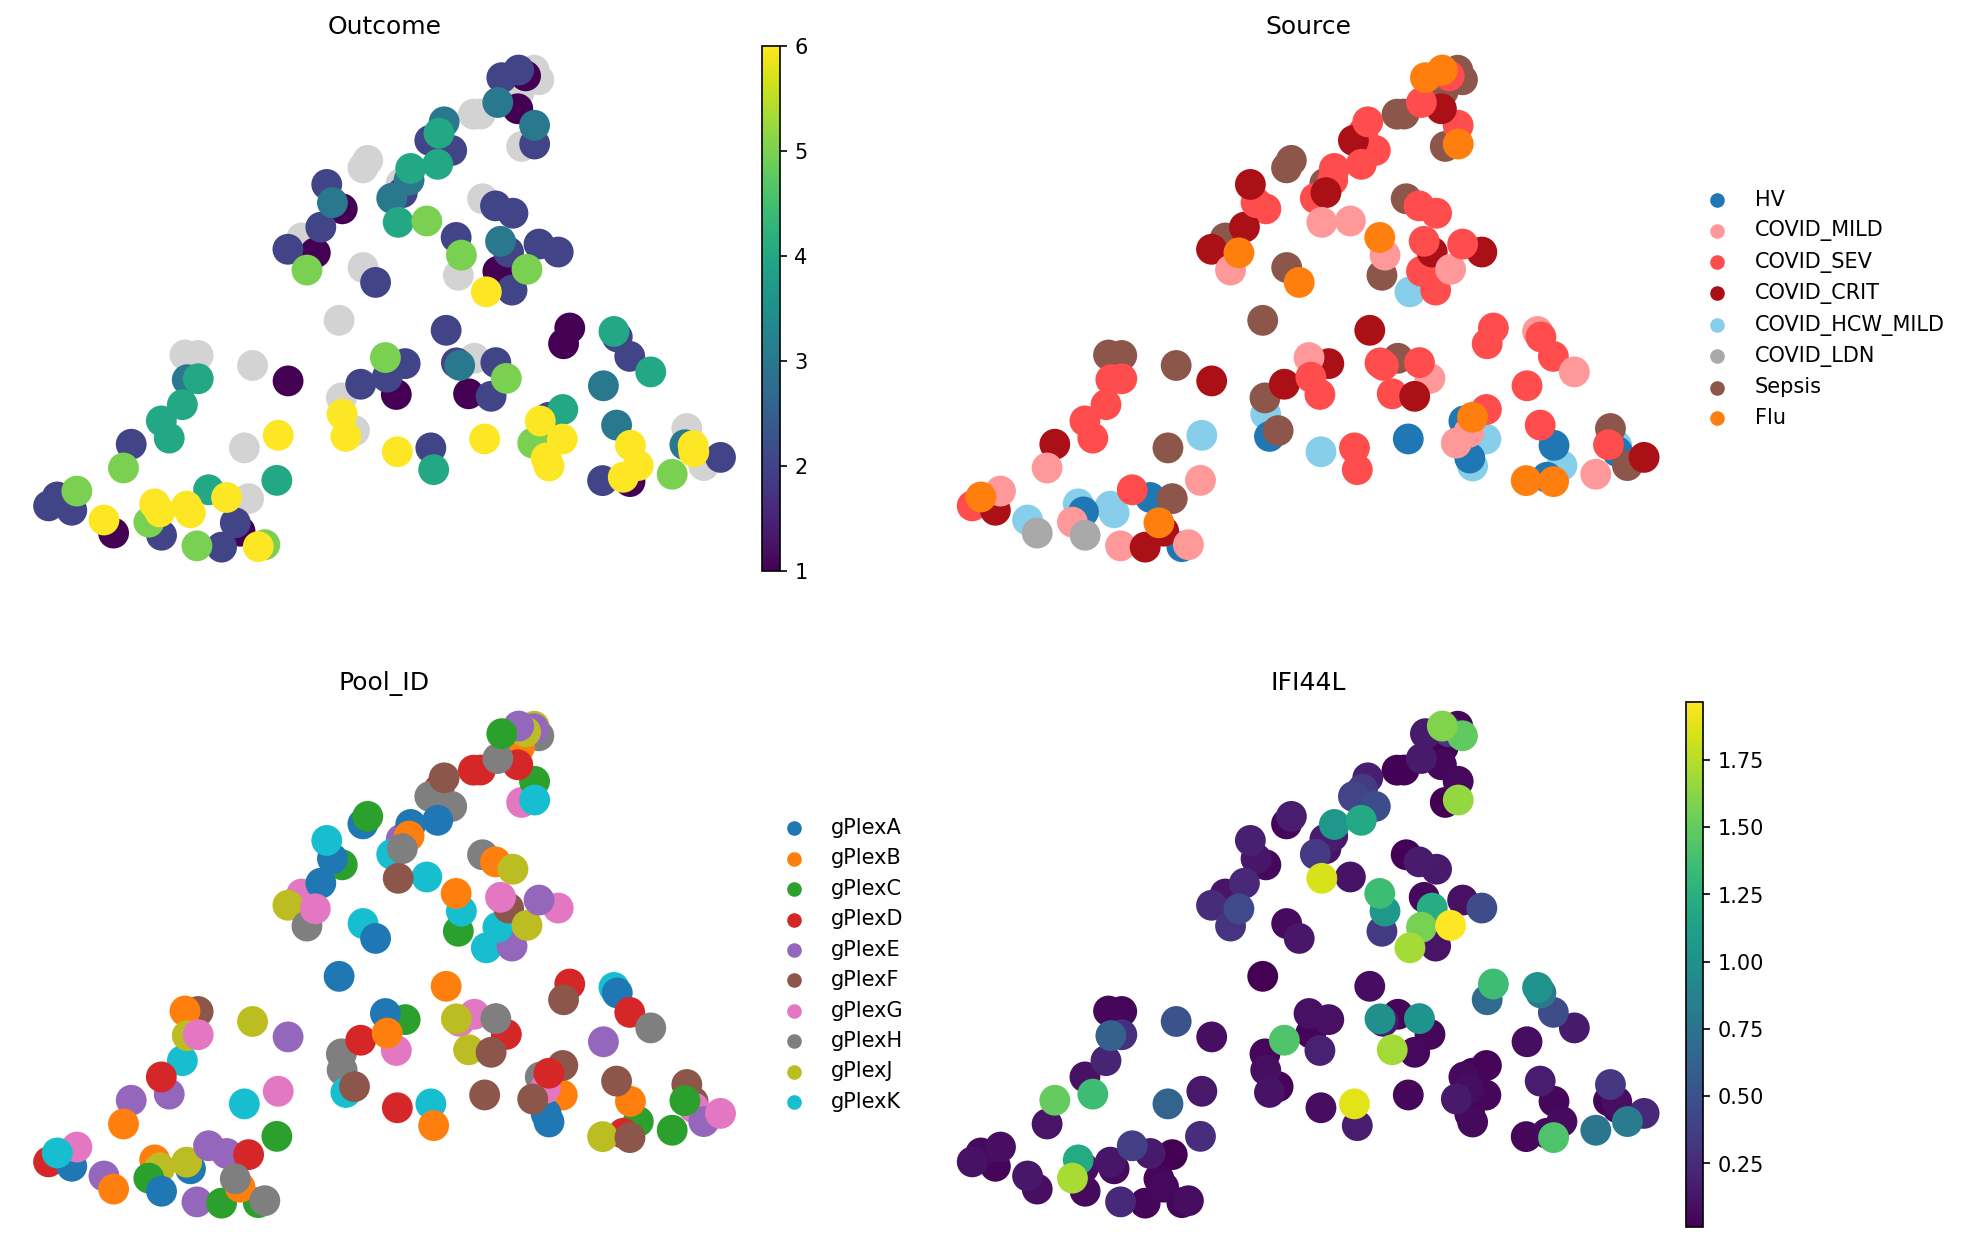

In [55]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_pilot", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


We can see that for COMBAT dataset and outcome signal preservation, PILOT does not outperform simpler baselines:

In [56]:
pilot.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.49516263715930153),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

## Method 4 — GroupedPseudobulk


GroupedPseudobulk is one step richer than Pseudobulk: instead of one vector per sample, you get one vector *per cell type per sample*, then concatenate them. If your biological signal in some cell types respond differently than the global average, this representation will uncover it. Moreover, grouped pseudobulk does not take into account cell type proportion differences, which can be beneficial, when cell type composition is explained by noise rather than by biology

Unlike plain Pseudobulk, this method needs at least a few cells in every (sample, cell_type) pair, so we drop very sparse cell types via `patpy.pp.filter_small_cell_groups`:


In [57]:
adata_for_grouped = patpy.pp.filter_small_cell_groups(
    dd.C,
    sample_key=sample_key,
    cell_group_key=cell_type_key,
    cluster_size_threshold=5,
)

13 cell types removed: B, MAIT, GDT, DP, ncMono, Mast, DN, iNKT, PLT, HSC, PB, RET, DC


In [58]:
_t0 = _time.time()

grouped_pseudobulk = patpy.tl.GroupedPseudobulk(
    sample_key=sample_key,
    cell_group_key=cell_type_key,
    layer="X_scVI_batch",
)
grouped_pseudobulk.prepare_anndata(adata_for_grouped)
grouped_pseudobulk.calculate_distance_matrix();

runtimes["combat"]["grouped_pseudobulk"] = _time.time() - _t0

In [59]:
# So far, sample_representation contains pseudobulks for each of cell types
# Let's concatenate them for each sample to have 1 vector per sample
grouped_pseudobulk.sample_representation = np.concatenate(grouped_pseudobulk.sample_representation, axis=1)

store_representation(grouped_pseudobulk, "grouped_pseudobulk")

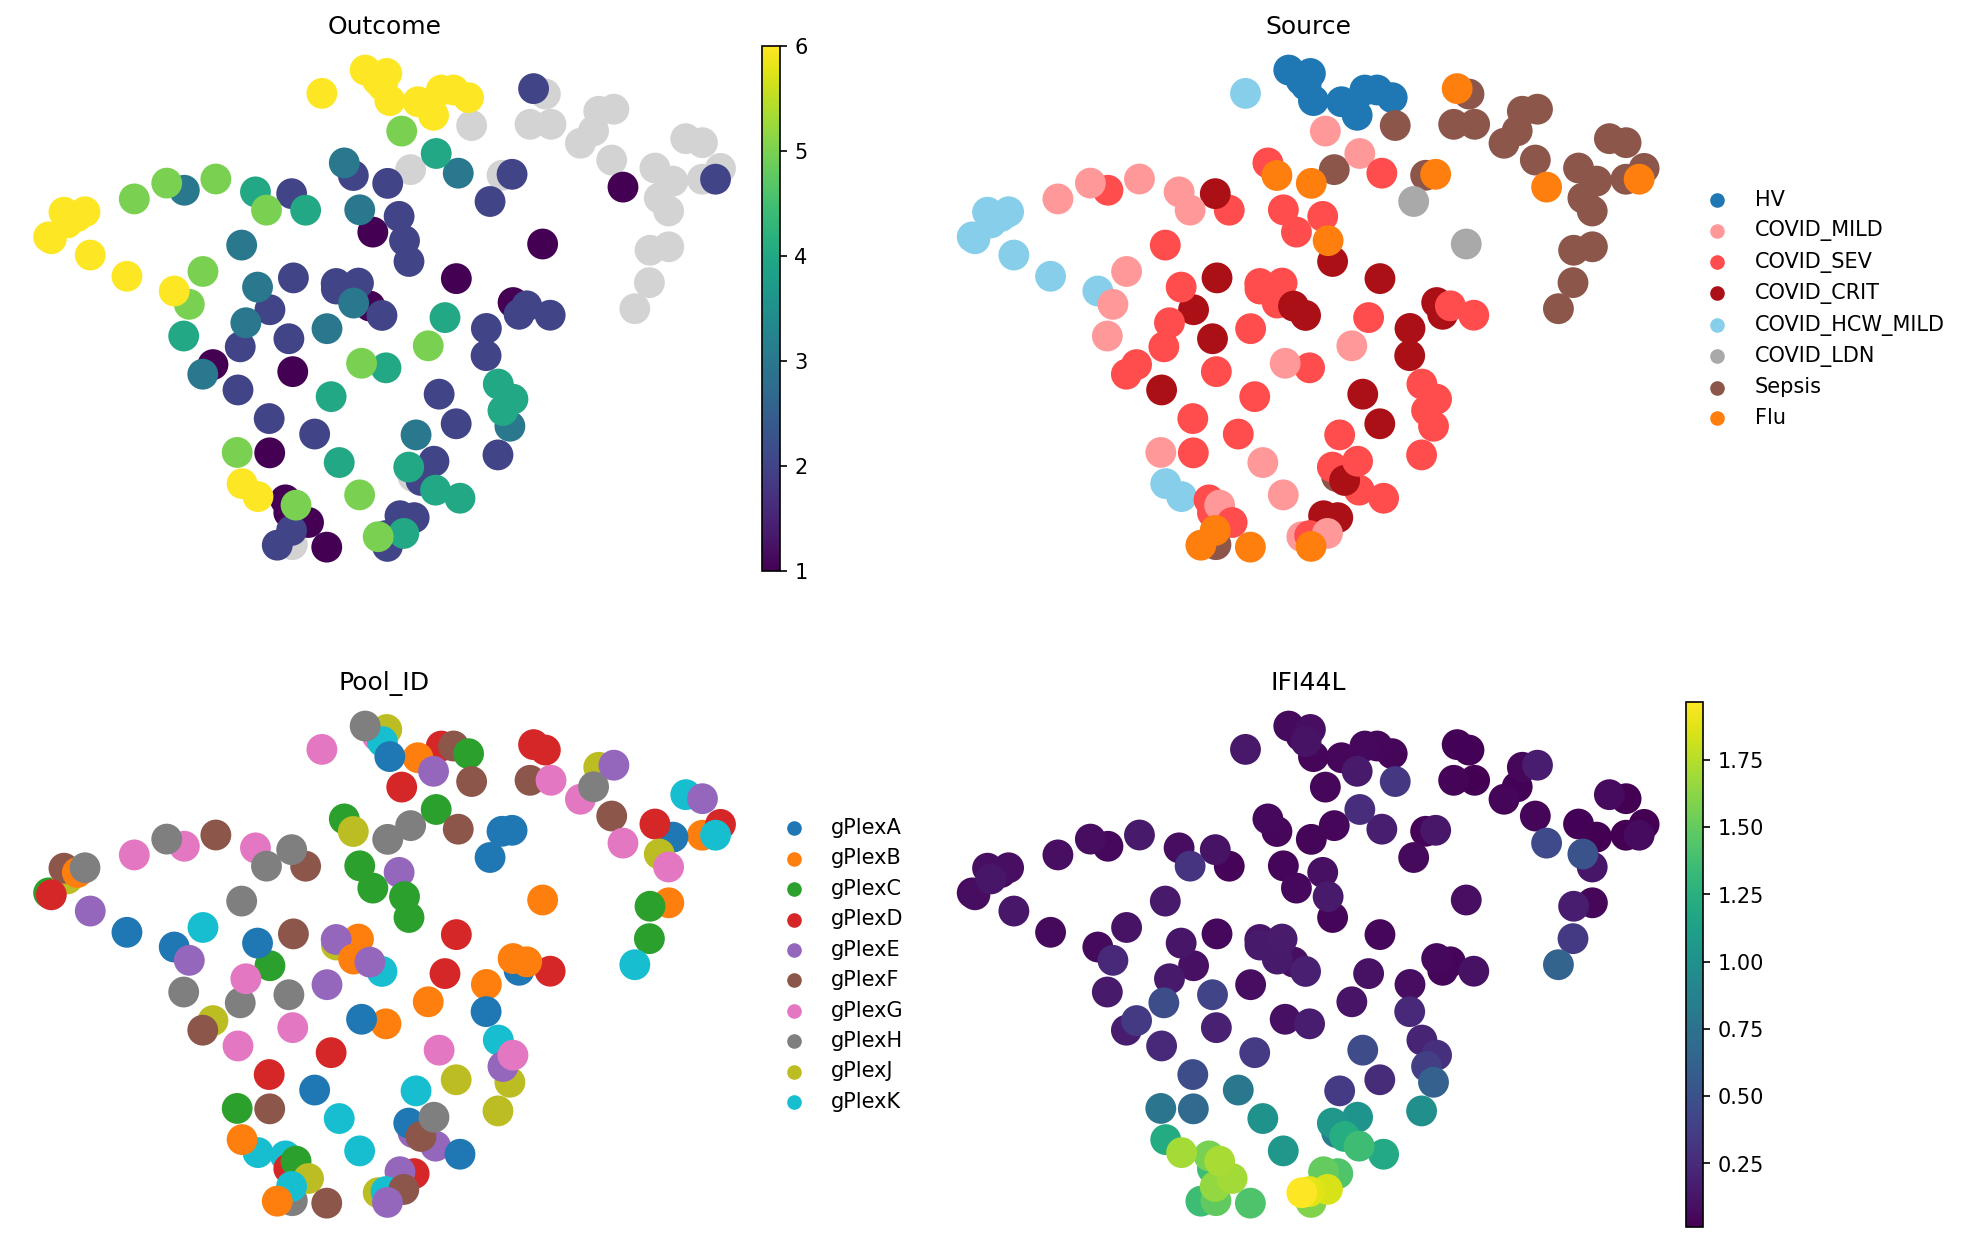

In [60]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_grouped_pseudobulk", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


Despite losing a lot of information about sparse cell types and cell type composition, this is the best representation we saw so far:

In [61]:
grouped_pseudobulk.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.734626387622032),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

## Method 5 — RandomVector (sanity baseline)

RandomVector assigns each sample a vector of Gaussian noise. It exists as a *floor* for the comparison table: any real method should beat random on the clinical covariates and should *not* beat random on the technical ones. It is also a good sanity check for overinterpretation of UMAPs. If you show some people sample representation of this method and they start to see patterns, do not show them UMAPs anymore

In [62]:
_t0 = _time.time()
random_vec = patpy.tl.RandomVector(
    sample_key=sample_key,
    cell_group_key=cell_type_key,
)
random_vec.prepare_anndata(dd)
random_vec.calculate_distance_matrix();
runtimes["combat"]["random_vec"] = _time.time() - _t0


In [63]:
store_representation(random_vec, "random_vec")

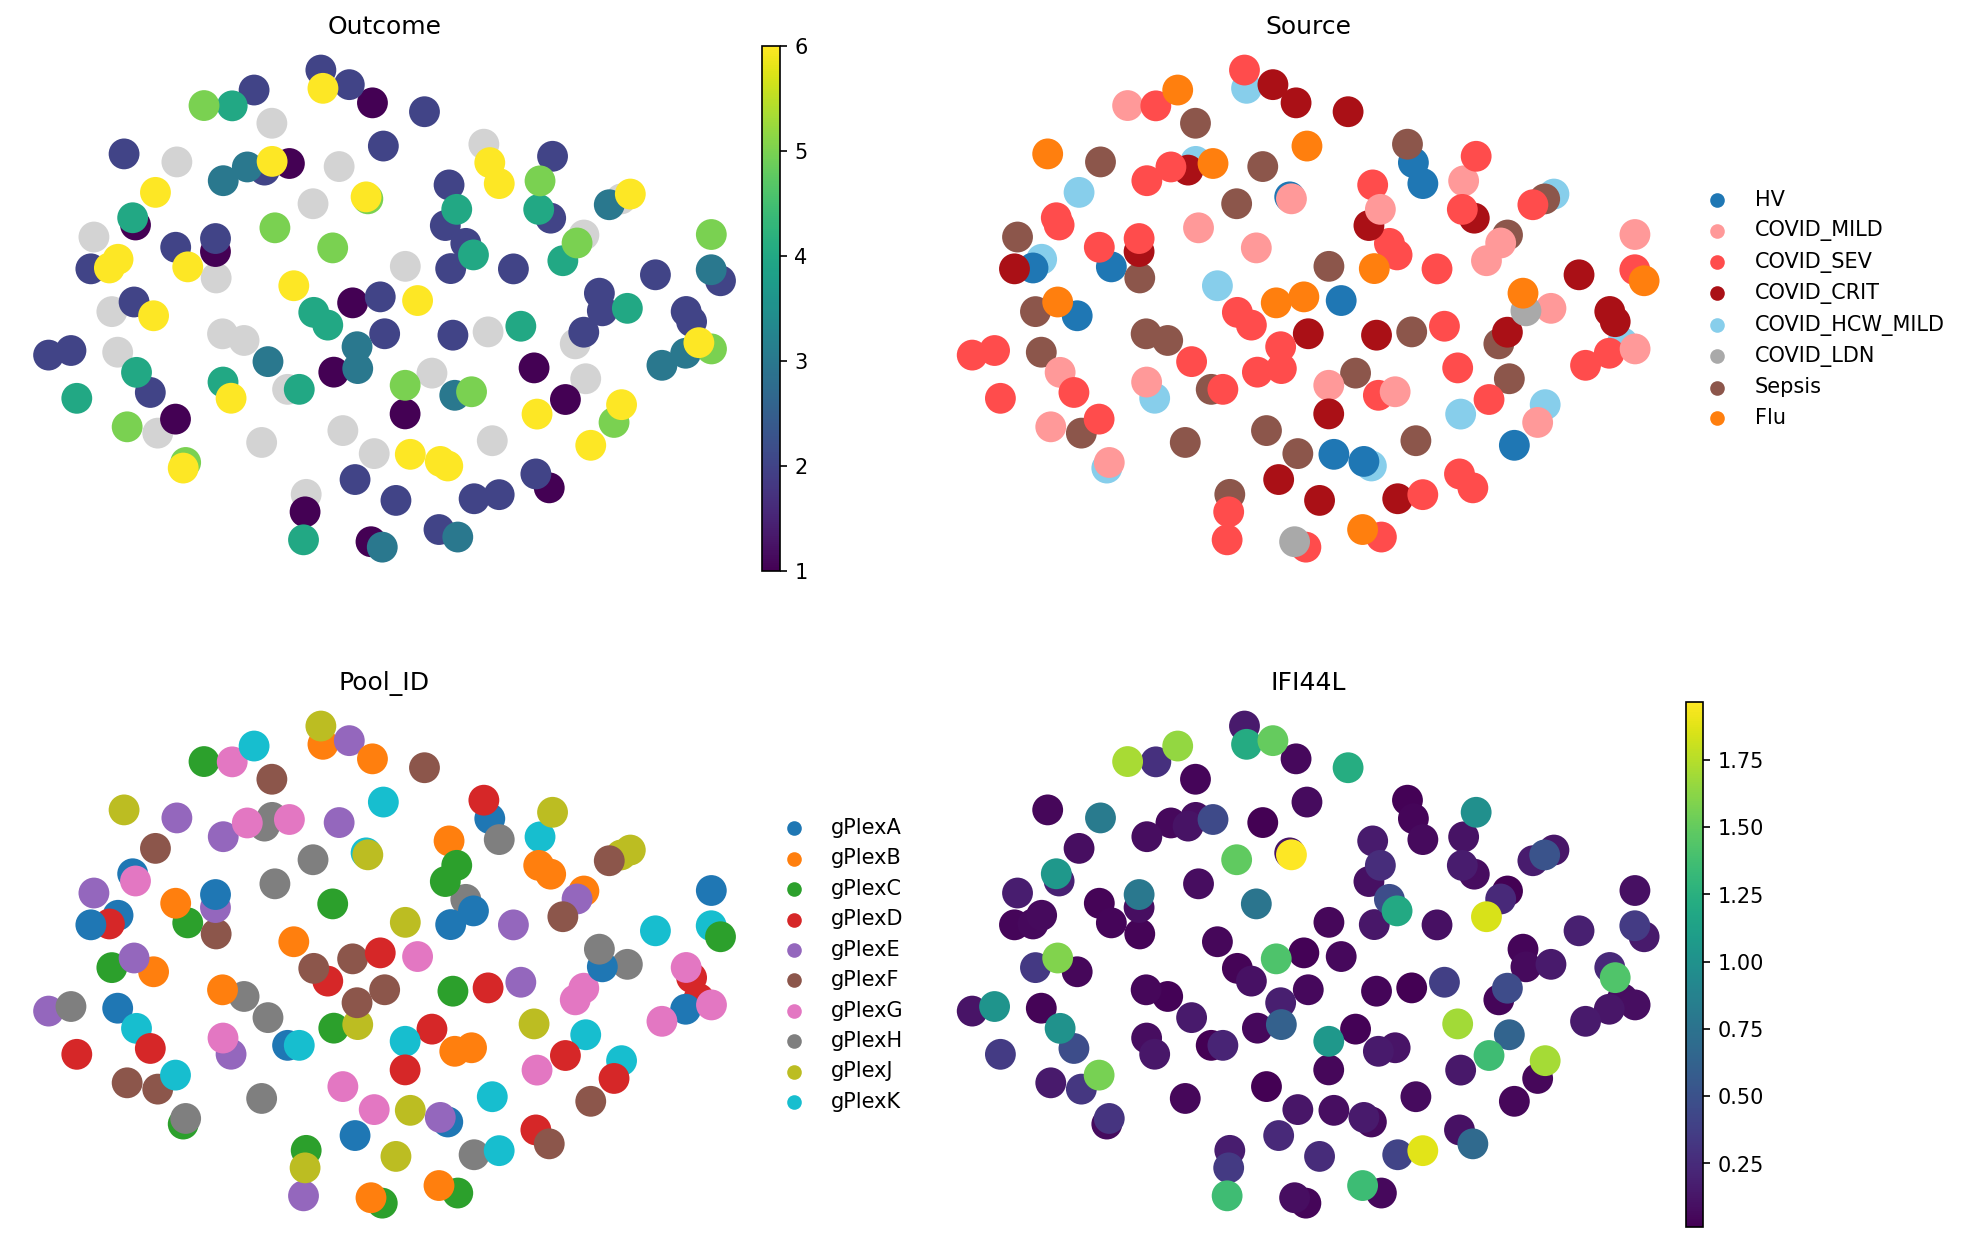

In [64]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_random_vec", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


Do you see this group on the right? No? That's right, there is no structure here beyond noise. Metrics show it clearly:

In [65]:
random_vec.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.0),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

## Method 6 — MOFA


MOFA2 fits a multi-view factor model: each cell type becomes a view, and shared latent factors are inferred across views

Requires `pip install mofapy2` (no `[mofa]` extra in patpy yet).


In [66]:
_t0 = _time.time()
mofa = patpy.tl.MOFA(
    sample_key=sample_key,
    cell_group_key=cell_type_key,
    n_factors=10,
    aggregate_cell_types=True,
    layer="X"
)
mofa.prepare_anndata(adata_for_grouped) # MOFA aggregates cells per cell type and samples too, so provide filtered adata
mofa.calculate_distance_matrix();
runtimes["combat"]["mofa"] = _time.time() - _t0



        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         




Features names not provided, using default naming convention:
- feature1_view1, featureD_viewM

Successfully loaded view='CD8' group='group1' with N=137 samples and D=3000 features...
Successfully loaded view='CD4' group='group1' with N=137 samples and D=3000 features...
Successfully loaded view='NK' group='group1' with N=137 samples and D=3000 features...
Successfully loaded view='cMono' group='group1' with N=137 samples and D=3000 features...





Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on the weights: True
Likelihoods:
- View 0 (CD8): gaussian
- View 1 (CD4): gaussian
- View 2 (NK): gaussian
- View 3 (cMono): gaussian






######################################
## Training the model with seed 67 ##
######################################


ELBO before training: -12030466.13 



Iteration 1: time=0.74, ELBO=2796109.21, deltaELBO=14826575.335 (123.24190252%), Factors=10


Iteration 2: time=1.02, ELBO=4886898.09, deltaELBO=2090788.884 (17.37911784%), Factors=10


... (61 outputs left out)

Iteration 64: time=0.70, ELBO=5206427.31, deltaELBO=73.522 (0.00061113%), Factors=10


Iteration 65: time=0.69, ELBO=5206493.83, deltaELBO=66.517 (0.00055290%), Factors=10


Iteration 66: time=0.91, ELBO=5206553.13, deltaELBO=59.301 (0.00049293%), Factors=10


Iteration 67: time=0.98, ELBO=5206603.95, deltaELBO=50.818 (0.00042241%), Factors=10

Converged!



#######################
## Training finished ##
#######################




In [67]:
store_representation(mofa, "mofa")

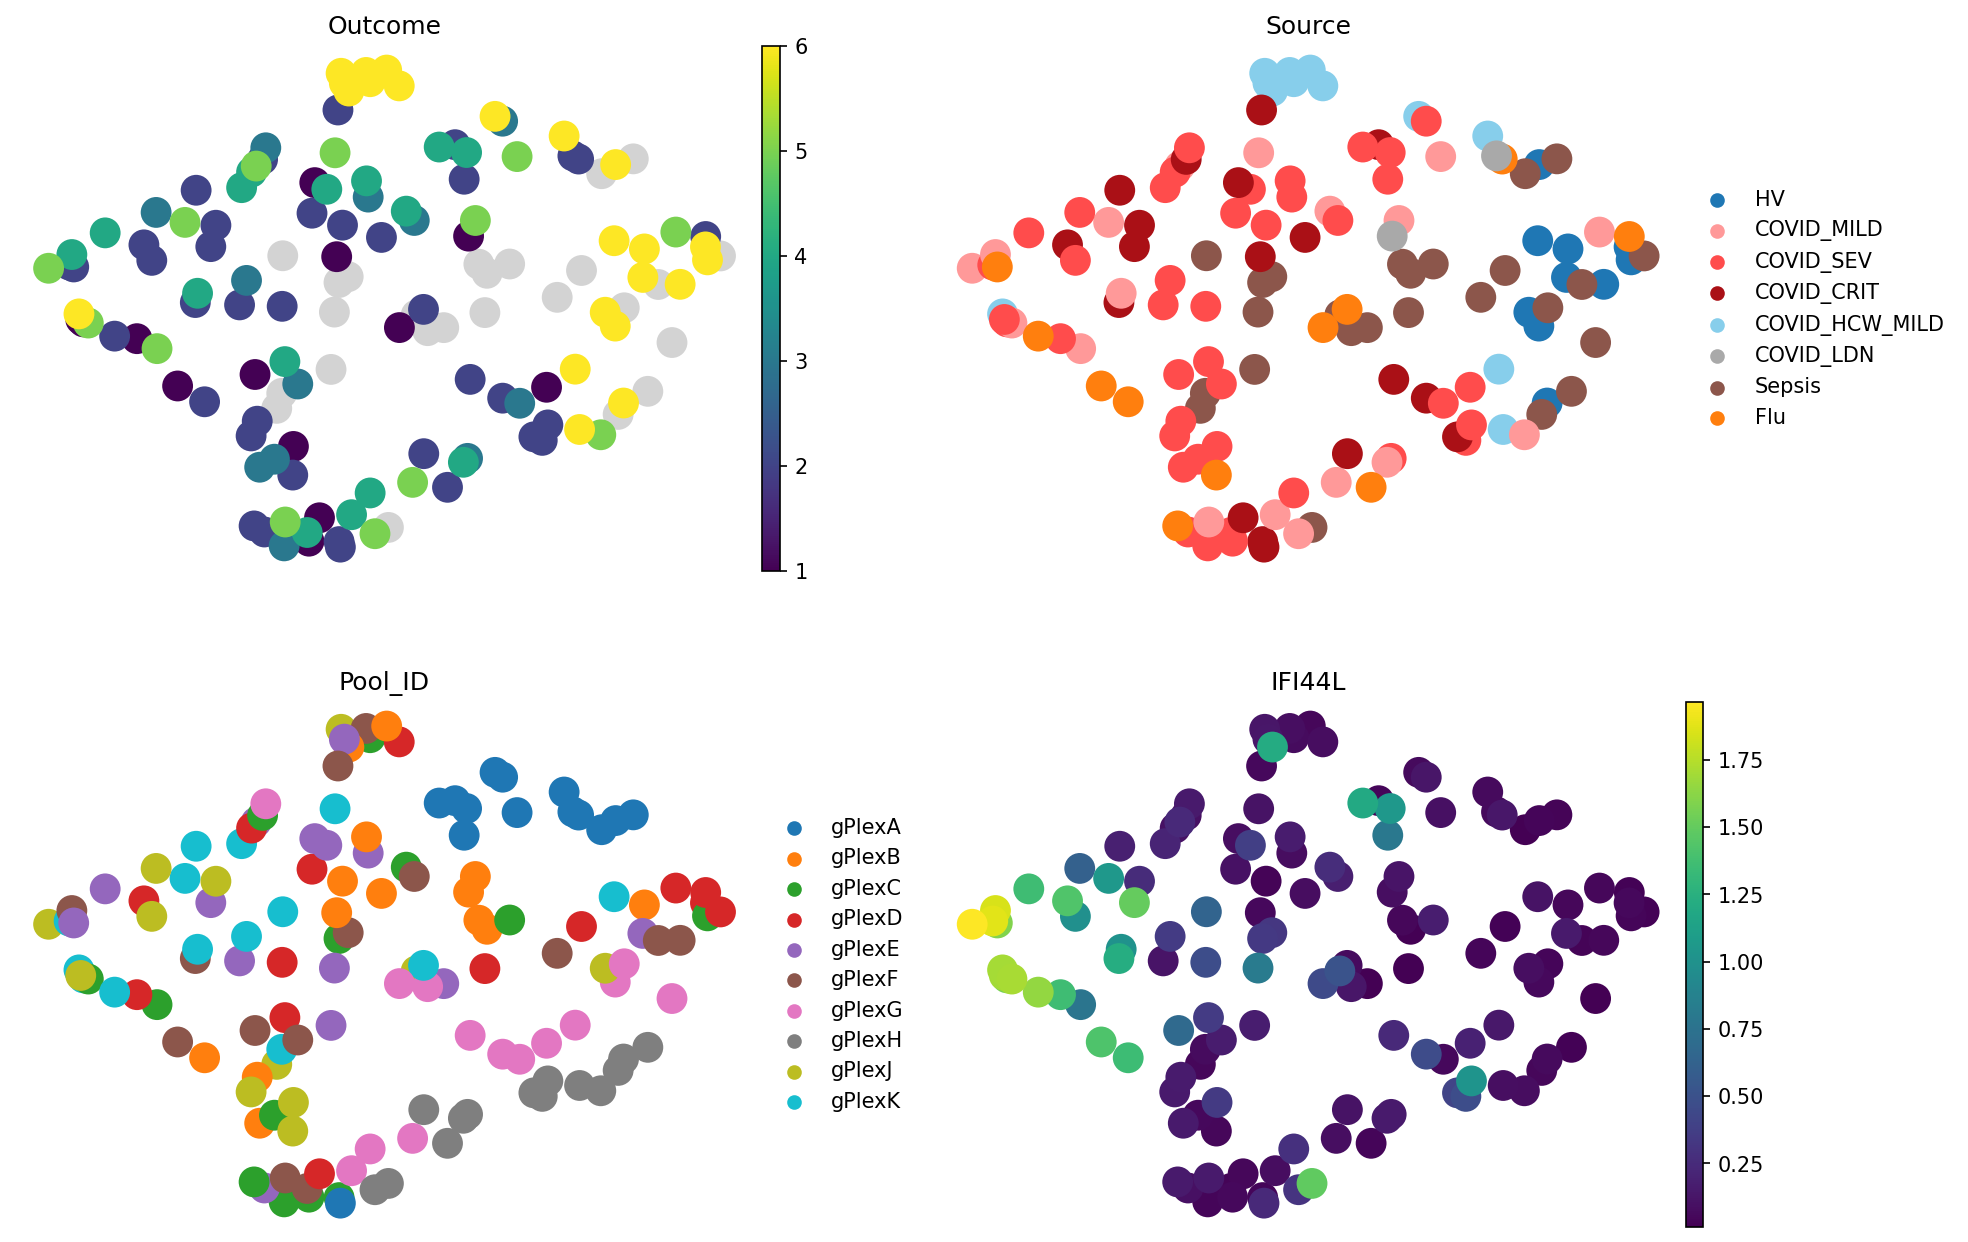

In [68]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_mofa", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


In [69]:
mofa.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.4894432043210996),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

## Method 7 — GloScope (Python)


### Why this method?

GloScope models each sample as a distribution over the cell-state manifold (in some low-dimensional latent embedding) and computes inter-sample distances as a distribution divergence (symmetric KL via k-nearest neighbours). GloScope is cell annotation-free, and directly compares cell density in feature space. It had shown the best performance in our sample representation methods [benchmark](https://openreview.net/forum?id=IoRv5afWtb).

Here, we use the Python reimplementation (`patpy.tl.GloScope_py`); the canonical R version is benchmarked separately in [`sources_of_variation_with_gloscope.ipynb`](./sources_of_variation_with_gloscope.ipynb). Needs `pip install patpy[gloscope-py-cpu]` (or `patpy[gloscope-py-gpu]` for a CUDA speedup).


In [70]:
_t0 = _time.time()
gloscope = patpy.tl.GloScope_py(
    sample_key=sample_key,
    cell_group_key=cell_type_key,
    layer="X_scVI_batch",
    k=25,
    use_gpu=True, # Set to False if your machine doesn't have GPU
)
gloscope.prepare_anndata(dd)
gloscope.calculate_distance_matrix();
runtimes["combat"]["gloscope"] = _time.time() - _t0


In [71]:
store_representation(gloscope, "gloscope")

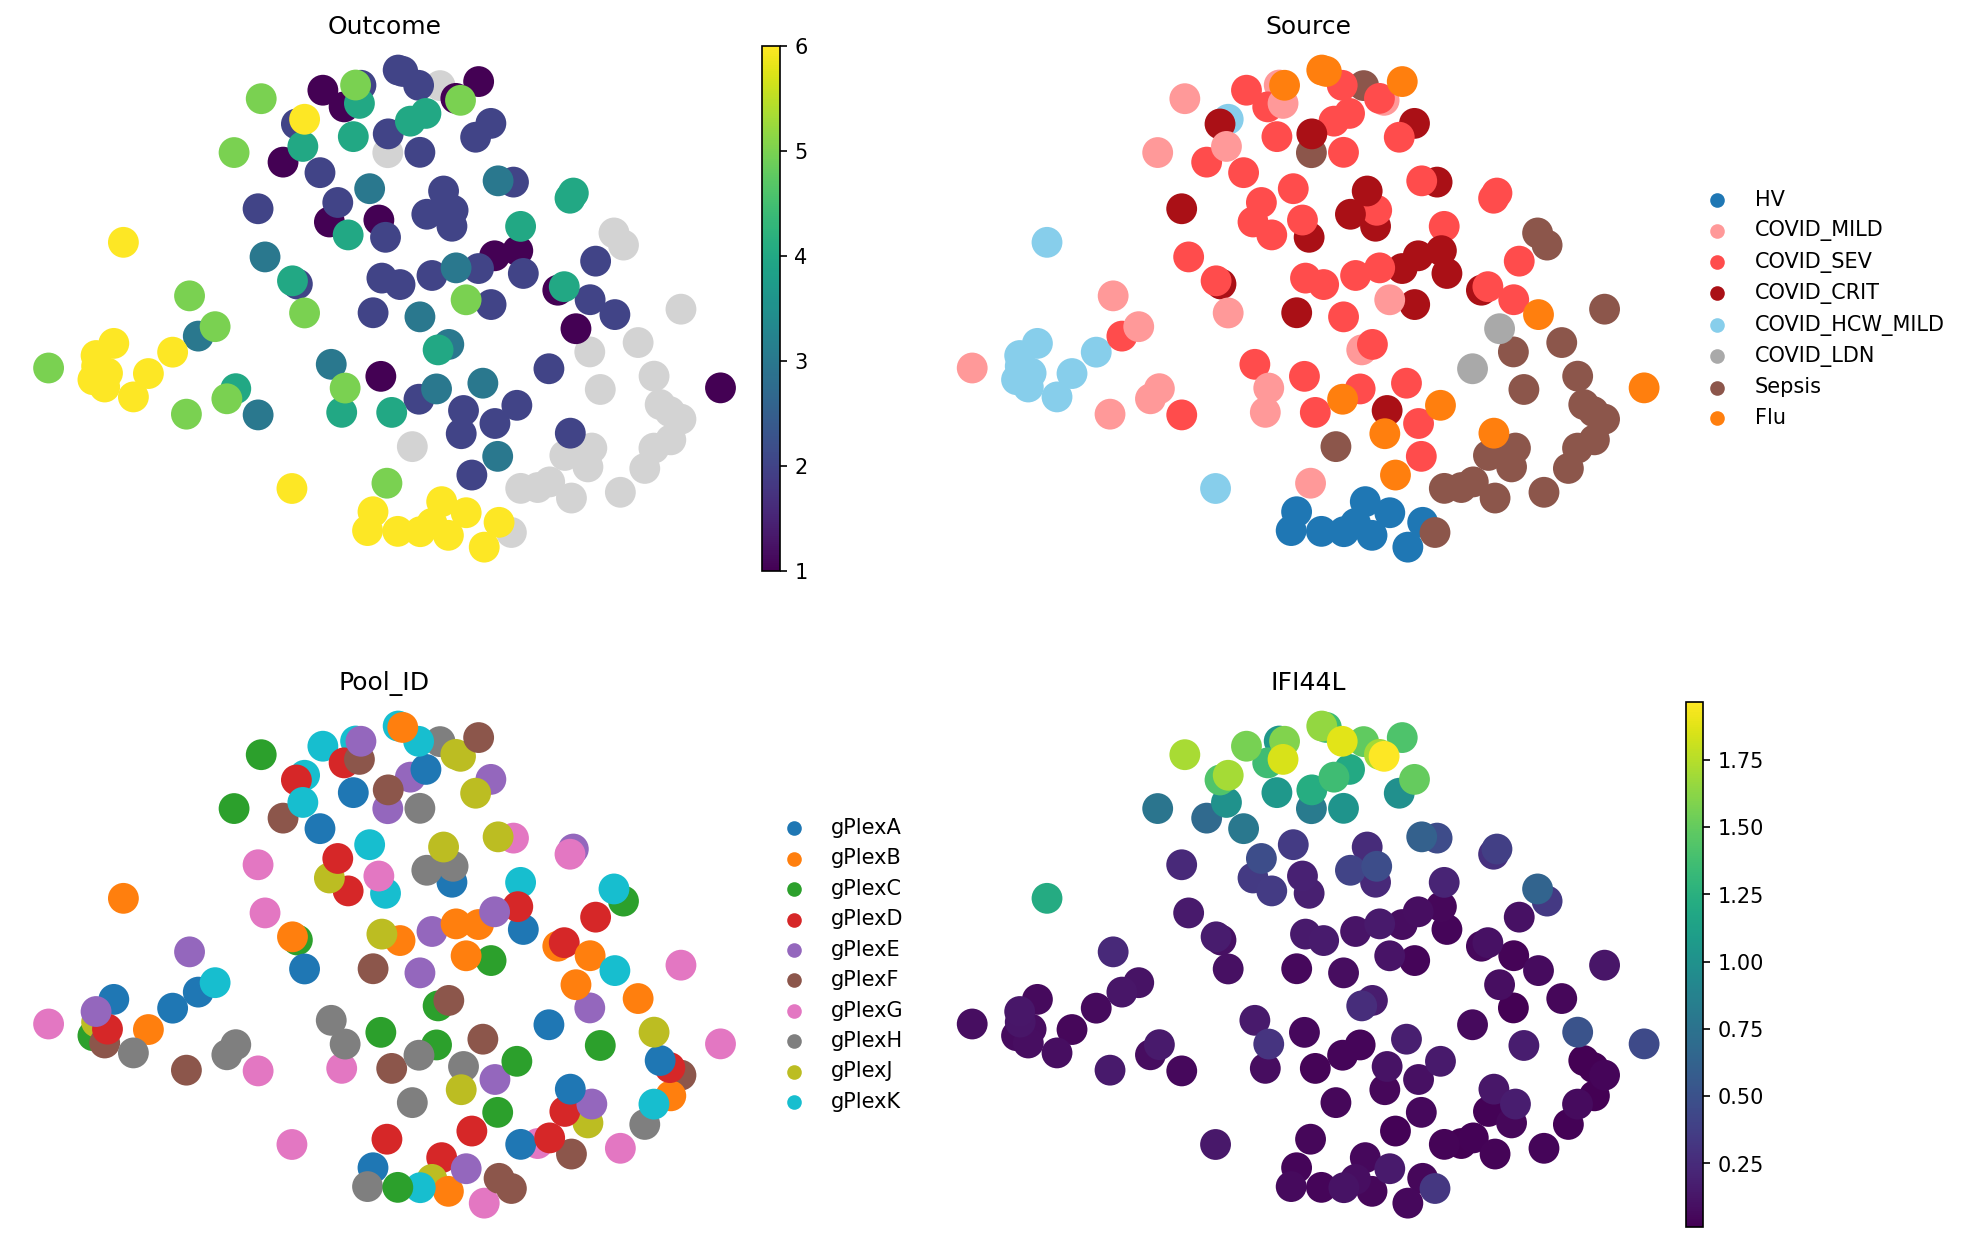

In [72]:
sc.pl.embedding(
    meta_adata,
    basis="X_umap_gloscope", 
    color=["Outcome", "Source", "Pool_ID", "IFI44L"],
    frameon=False,
    ncols=2
)


In [73]:
gloscope.evaluate_representation(target="Outcome", method="knn", n_neighbors=5, task="ranking")

{'score': np.float64(0.7313590352852797),
 'metric': 'spearman_r',
 'n_unique': 6,
 'n_observations': 112,
 'method': 'knn'}

# Putting benchmark together

Let's systematically evaluate all the sample representation methods, using available metadata information. For that, we need to set up a benchmark schema – categorise metadata columns into clinically relevant and technical, and define prediction tasks:

In [74]:
benchmark_schema = {
    "technical": {
        "Institute": "classification",
        "Pool_ID": "classification",
        "n_cells": "regression",
        "median_QC_ngenes": "regression",
        },
    "clinical": {
        "Death28": "classification",
        "Outcome": "ranking", 
        "Source": "classification",
    },
}

results = patpy.tl.evaluation.knn_prediction_score(
    meta_adata,
    benchmark_schema,
    representations=dd.uns["sample_representations"],
    n_neighbors=5,
    reverse_technical_score=True,  # To make higher = better
)

Scores are ranged from 0 to 1

- For covariates that we defined as technical, 0 means that covariate strongly affects the representation, and 1 means that this covariate is randomly distributed across representation
- For biological and clinical covariates, 0 means that a covariate is not represented well (it is randomly distributed), while 1 means that similar patients have similar values of covariate 

In [75]:
knn_results = pd.DataFrame(results)
knn_results.sort_values("score", ascending=False)

,score,metric,n_unique,n_observations,method,representation,covariate,covariate_type
0,1.0,f1_macro_calibrated,2,137,knn,Pseudobulk_expression,Institute,technical
29,1.0,f1_macro_calibrated,10,137,knn,composition_clr,Pool_ID,technical
28,1.0,f1_macro_calibrated,2,137,knn,composition_clr,Institute,technical
21,1.0,f1_macro_calibrated,2,137,knn,composition,Institute,technical
14,1.0,f1_macro_calibrated,2,137,knn,Pseudobulk_scVI,Institute,technical
...,...,...,...,...,...,...,...,...
18,0.0,f1_macro_calibrated,2,137,knn,Pseudobulk_scVI,Death28,clinical
53,0.0,f1_macro_calibrated,2,137,knn,random_vec,Death28,clinical
39,0.0,f1_macro_calibrated,2,137,knn,pilot,Death28,clinical
55,0.0,f1_macro_calibrated,8,137,knn,random_vec,Source,clinical


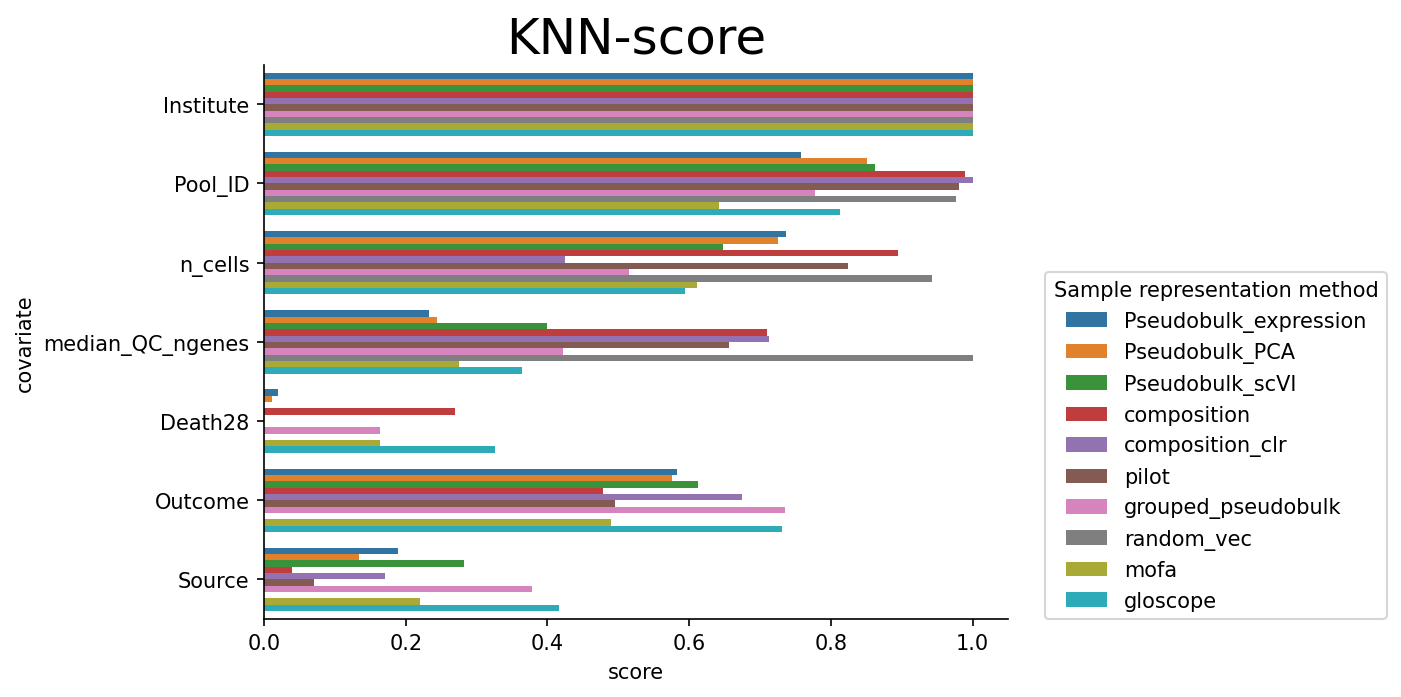

In [76]:
# plt.figure(figsize=(10, 20))
sns.barplot(data=knn_results, y="covariate", x="score", orient="h", hue="representation")
plt.xlim(0, 1.05)
plt.title("KNN-score", fontsize=24)
sns.despine()
plt.legend(loc=(1.05, 0), title="Sample representation method")

We can see that technical covariates are generally mixed well. For clinically relevant variables, there is some diversity. Let's now compare outcome trajectory preservation

## Evaluation 2 — trajectory preservation

In [77]:
trajectory_results = patpy.tl.trajectory_correlation(
    meta_adata=meta_adata,
    root_sample=root_sample,  # Defined above as the youngest healthy sample
    trajectory_variable="Outcome",
    representations=dd.uns["sample_representations"],
    inverse_trajectory=True,
)
trajectory_results


Diffmap for Pseudobulk_expression already computed, skipping
Diffmap for Pseudobulk_PCA already computed, skipping
Diffmap for Pseudobulk_scVI already computed, skipping
Computing diffmap for composition


Computing diffmap for composition_clr
Computing diffmap for pilot
Computing diffmap for grouped_pseudobulk
Computing diffmap for random_vec
Computing diffmap for mofa
Computing diffmap for gloscope


,correlation
composition_clr,0.714885
gloscope,0.509148
Pseudobulk_expression,0.454022
Pseudobulk_PCA,0.450591
pilot,0.418825
Pseudobulk_scVI,0.400080
grouped_pseudobulk,0.364444
mofa,0.313631
composition,0.244055
random_vec,0.014787


Let's now create a clearer visualisation and aggregate all the metrics into 1 score. We compute the total score by weighting batch mixing half as much as trajectory preservation and information retention. The reason is because batch mixing is a very easy task to achieve a high score. If a method doesn't capture any information (like our random baseline), it achieves a perfect batch mixing score. To make sure methods are prioritised by learning biology, we weigh other scores more:

In [78]:
knn_results_wide = knn_results.pivot(index="representation", columns="covariate", values="score")

# Add trajectory preservation score early so it can feed into col_defs below
knn_results_wide["Trajectory"] = (
    trajectory_results.loc[knn_results_wide.index, "correlation"].abs()
)

# Group covariates by the two scoring buckets, with new display names
display_buckets = {
    "Information retention": benchmark_schema["clinical"].keys(),
    "Batch mixing": benchmark_schema["technical"].keys(),
}

# Per-bucket means -> bucket columns
for bucket, cols in display_buckets.items():
    knn_results_wide[bucket] = knn_results_wide[cols].mean(axis=1)

# New total: (2 * info + 2 * trajectory + batch_mixing) / 5
knn_results_wide["Total"] = (
    2 * knn_results_wide["Information retention"]
    + 2 * knn_results_wide["Trajectory"]
    + knn_results_wide["Batch mixing"]
) / 5

cols_order = ["Total", "Information retention", "Trajectory", "Batch mixing"]
cols_order += display_buckets["Information retention"]
cols_order += display_buckets["Batch mixing"]

cmap_bar = LinearSegmentedColormap.from_list(
    name="bugw", colors=["#FF9693", "#f2fbd2", "#c9ecb4", "#93d3ab", "#35b0ab"], N=256,
)

bar_kw = {
    "cmap": cmap_bar, "plot_bg_bar": True, "annotate": True,
    "height": 0.5, "lw": 0.5, "formatter": lambda x: round(x, 2),
}

col_defs = [
    ColumnDefinition("Total", width=0.7, plot_fn=bar, plot_kw=bar_kw),
    ColumnDefinition(
        "Information retention", width=0.8, plot_fn=bar, plot_kw=bar_kw,
        group="aggregate",
    ),
    ColumnDefinition(
        "Trajectory", width=0.7, plot_fn=bar, plot_kw=bar_kw,
        group="aggregate",
    ),
    ColumnDefinition(
        "Batch mixing", width=0.7, plot_fn=bar, plot_kw=bar_kw,
        group="aggregate",
    ),
]
for col in display_buckets["Information retention"]:
    col_defs.append(ColumnDefinition(
        name=col, width=0.55, formatter=lambda x: round(x, 2),
        textprops={"ha": "center", "bbox": {"boxstyle": "circle", "pad": 0.35}},
        cmap=normed_cmap(knn_results["score"], cmap=matplotlib.cm.PiYG, num_stds=2.5),
        group="Information retention covariates",
    ))
for col in display_buckets["Batch mixing"]:
    col_defs.append(ColumnDefinition(
        name=col, width=0.55, formatter=lambda x: round(x, 2),
        textprops={"ha": "center", "bbox": {"boxstyle": "circle", "pad": 0.35}},
        cmap=normed_cmap(knn_results["score"], cmap=matplotlib.cm.PiYG, num_stds=2.5),
        group="Batch mixing covariates",
    ))


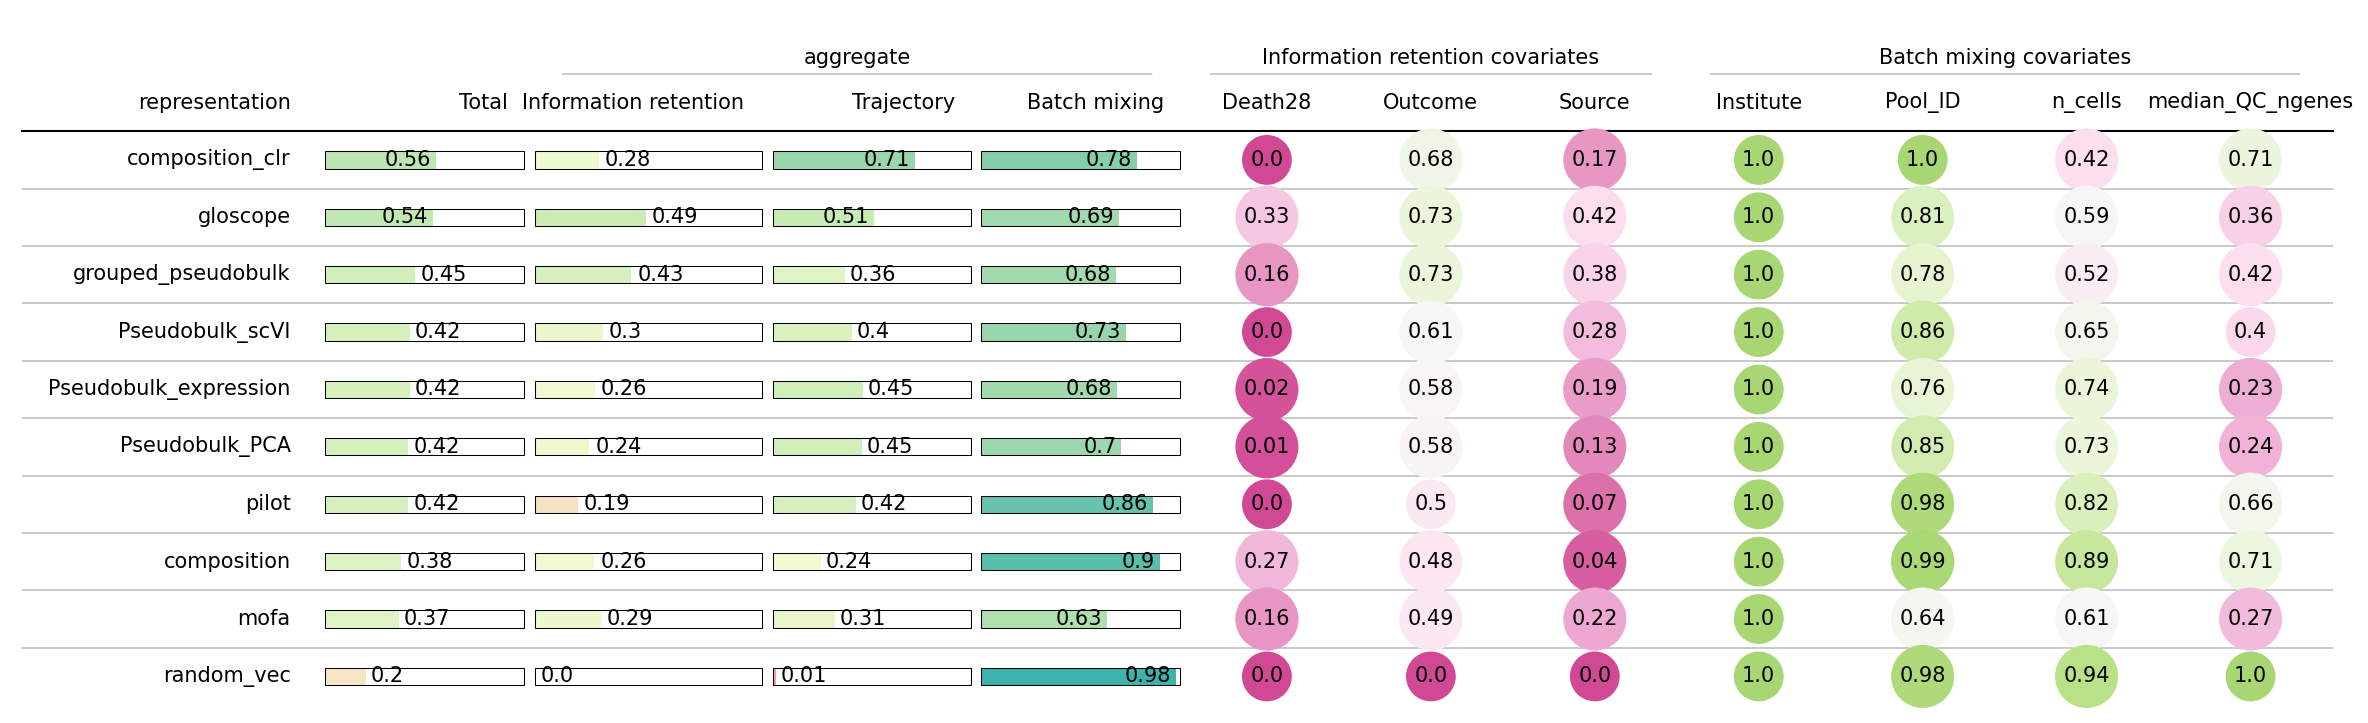

In [79]:
fig, ax = plt.subplots(figsize=(20, 6))
Table(knn_results_wide[cols_order].sort_values("Total", ascending=False), column_definitions=tuple(col_defs), ax=ax)


### How to read this table

Every cell is a score in `[0, 1]` where **higher = better**:

- **Clinical** columns (`Outcome`, `Death28`, `Source`): high means a kNN classifier trained on the sample distances recovers the clinical label.
- **Technical** columns (`Institute`, `Pool_ID`, `n_cells`, `median_QC_ngenes`): high means the *opposite* — how well the batch effect-related covariates **mix**.
- **`trajectory`** is the absolute Spearman correlation between diffusion pseudotime (rooted at the healthiest donor) and `Outcome`. High means the order of severity is preserved along the representation's diffusion graph.
- **`total`** is a weighted average that gives more weight to clinical signal than to batch invariance, so the top of the sorted table is the method most useful for downstream clinical analysis on this dataset.

We can see that **CLR-transformed composition** and **GloScope** are very good in capturing clinical information. While the former better represents trajectory, the latter better groups different health conditions, and even death in 28 days to some extent. Which method to use depends on the research question.

## A reusable benchmark helper

To compare against other datasets we need to repeat the same workflow: run every method, score each one against a "relevant" (clinical) covariate set and a "technical" covariate set, and compute a trajectory correlation. Below is a single helper that does all of that, returning per-method distances, kNN scores, and a summary table. We'll call it three times: once each for COMBAT (already done above), HLCA, and Stephenson.


In [80]:
import time
import gc
import os

def run_all_methods_on_dataset(
    adata,
    *,
    sample_key,
    cell_type_key,
    layer="X_scVI_batch",
    cluster_size_threshold=5,
    skip_methods=None,
    gloscope_use_gpu=None,
):
    """Run sample-representation methods on `adata`.

    Eight methods total (kept in sync with the COMBAT walkthrough above):
    Pseudobulk on the latent space, CellGroupComposition (raw + CLR),
    PILOT, RandomVector, MOFA, GloScope_py, and GroupedPseudobulk.
    MOFA and GroupedPseudobulk both need a filtered AnnData (cell groups
    with very few cells in some samples make their per-(sample,
    cell_type) aggregations degenerate), so we compute it lazily and
    reuse it.

    Returns
    -------
    dict with keys 'distances', 'samples', 'runtimes' (each keyed by method name).
    """
    out = {"distances": {}, "samples": {}, "runtimes": {}}

    skip_methods = set(skip_methods or [])
    _gloscope_gpu = (
        gloscope_use_gpu if gloscope_use_gpu is not None
        else bool(os.environ.get("PATPY_GLOSCOPE_GPU"))
    )

    adata_filtered = None

    def _ensure_filtered():
        nonlocal adata_filtered
        if adata_filtered is None:
            f = patpy.pp.filter_small_cell_groups(
                adata, sample_key=sample_key, cell_group_key=cell_type_key,
                cluster_size_threshold=cluster_size_threshold,
            )
            # On very wide cohorts (HLCA, OneK1K) the filter can wipe every
            # cell type because few donors have >= threshold cells of *every*
            # type. Fall back to the unfiltered adata in that case so MOFA
            # still has something to fit.
            if f.n_obs == 0:
                print(
                    f"  filter_small_cell_groups(threshold={cluster_size_threshold})"
                    f" removed every cell type; falling back to unfiltered adata"
                )
                f = adata
            adata_filtered = f
        return adata_filtered

    # (method_name, source, factory). `source` selects which adata to fit on:
    # "adata" = the input, "filtered" = small-cell-group-filtered copy.
    method_specs = [
        ("pseudobulk",      "adata",    lambda: patpy.tl.Pseudobulk(
            sample_key=sample_key, cell_group_key=cell_type_key, layer=layer)),
        ("composition",     "adata",    lambda: patpy.tl.CellGroupComposition(
            sample_key=sample_key, cell_group_key=cell_type_key)),
        ("composition_clr", "adata",    lambda: patpy.tl.CellGroupComposition(
            sample_key=sample_key, cell_group_key=cell_type_key, apply_clr=True)),
        ("pilot",           "adata",    lambda: patpy.tl.PILOT(
            sample_key=sample_key, cell_group_key=cell_type_key, layer=layer,
            sample_state_col=sample_key)),  # status is unused for the distance; pass a valid obs column so pilotpy does not KeyError
        ("random_vec",      "adata",    lambda: patpy.tl.RandomVector(
            sample_key=sample_key, cell_group_key=cell_type_key)),
        ("mofa",            "filtered", lambda: patpy.tl.MOFA(
            sample_key=sample_key, cell_group_key=cell_type_key,
            n_factors=10, aggregate_cell_types=True)),
        ("gloscope",        "adata",    lambda: patpy.tl.GloScope_py(
            sample_key=sample_key, cell_group_key=cell_type_key, layer=layer, k=25,
            use_gpu=_gloscope_gpu)),
    ]
    for name, source, factory in method_specs:
        if name in skip_methods:
            print(f"  {name}: skipped")
            continue
        try:
            t0 = time.time()
            m = factory()
            src_adata = _ensure_filtered() if source == "filtered" else adata
            m.prepare_anndata(src_adata)
            out["distances"][name] = m.calculate_distance_matrix(force=True)
            out["samples"][name] = list(m.samples)
            out["runtimes"][name] = time.time() - t0
            print(f"  {name}: {out['runtimes'][name]:.1f}s")
        except Exception as e:
            print(f"  {name} FAILED: {type(e).__name__}: {e}")

    # GroupedPseudobulk also needs the filtered adata.
    if "grouped_pseudobulk" in skip_methods:
        print("  grouped_pseudobulk: skipped")
    else:
        try:
            t0 = time.time()
            m = patpy.tl.GroupedPseudobulk(
                sample_key=sample_key, cell_group_key=cell_type_key, layer=layer)
            m.prepare_anndata(_ensure_filtered())
            out["distances"]["grouped_pseudobulk"] = m.calculate_distance_matrix()
            out["samples"]["grouped_pseudobulk"] = list(m.samples)
            out["runtimes"]["grouped_pseudobulk"] = time.time() - t0
            print(f"  grouped_pseudobulk: {out['runtimes']['grouped_pseudobulk']:.1f}s")
        except Exception as e:
            print(f"  grouped_pseudobulk FAILED: {type(e).__name__}: {e}")

    if adata_filtered is not None:
        del adata_filtered
        gc.collect()

    return out


def score_methods_on_dataset(
    bench_result,
    *,
    metadata,
    sample_key,
    schema,
    root_sample,
    trajectory_variable,
    inverse_trajectory=False,
    n_neighbors=5,
):
    """Score the methods produced by `run_all_methods_on_dataset` against
    a SPARE-style `schema` (dict with at least 'relevant' / 'technical' keys
    mapping to {covariate: task}). Uses `patpy.tl.evaluation.knn_prediction_score`
    -- the same entry point as the COMBAT walkthrough -- and adds a trajectory
    correlation if `trajectory_variable` and `root_sample` are present.

    Returns
    -------
    dict with keys 'long' (long-format scores), 'summary' (per-method
    Information retention / Batch mixing / Trajectory / Runtime / Total),
    and 'meta_adata' (the AnnData used for diffmap).
    """
    methods_all = list(bench_result["distances"].keys())
    # Drop methods that ended up with zero samples (otherwise the
    # intersection across methods is empty and nothing gets scored).
    methods = [m for m in methods_all if len(bench_result["samples"][m]) > 0]
    if len(methods) < len(methods_all):
        empty = [m for m in methods_all if m not in methods]
        print(f"  dropping methods with 0 samples: {empty}")
    method_sample_sets = {m: set(bench_result["samples"][m]) for m in methods}
    common = set.intersection(*method_sample_sets.values()) if method_sample_sets else set()
    common = [s for s in metadata.index if s in common]
    print(f"  scoring on {len(common)} samples (methods: {[(m, len(s)) for m, s in method_sample_sets.items()]})")
    if len(common) < 4:
        print("  too few common samples for kNN scoring; returning empty summary")
        empty = pd.Series(np.nan, index=methods)
        summary = pd.DataFrame({
            "Information retention": empty,
            "Batch mixing": empty,
            "Trajectory": empty,
            "Runtime (s)": pd.Series(bench_result["runtimes"]).reindex(methods),
            "Total": empty,
        })
        return {"long": pd.DataFrame(), "summary": summary, "meta_adata": None}
    meta = metadata.loc[common].copy()
    # Drop all-NaN columns -- ehrapy.encode chokes on them
    meta = meta.dropna(axis=1, how="all")
    meta_adata = ep.io.df_to_anndata(meta)
    meta_adata = ep.pp.encode(meta_adata, autodetect=True)
    # Preserve the raw schema columns on .obs so knn_prediction_score can find
    # them after ep.pp.encode renames the encoded versions.
    for cov_tasks in schema.values():
        for col in cov_tasks:
            if col in meta.columns:
                meta_adata.obs[col] = meta[col].values

    for m in methods:
        order = [bench_result["samples"][m].index(s) for s in common]
        d = bench_result["distances"][m]
        meta_adata.obsm[f"{m}_distances"] = d[np.ix_(order, order)]
        _n_nbrs = min(15, max(2, len(common) - 1))
        ep.pp.neighbors(
            meta_adata, use_rep=f"{m}_distances",
            key_added=f"{m}_neighbors", metric="precomputed",
            n_neighbors=_n_nbrs,
        )
    meta_adata.uns["sample_representations"] = list(methods)

    # KNN scoring via the same patpy entry point used in the COMBAT walkthrough.
    schema_present = {
        group: {col: task for col, task in cov_tasks.items() if col in meta.columns}
        for group, cov_tasks in schema.items()
    }
    long_df = patpy.tl.evaluation.knn_prediction_score(
        meta_adata, schema_present, representations=list(methods),
        n_neighbors=n_neighbors, reverse_technical_score=True,
    )

    # Trajectory correlation
    traj_series = pd.Series(np.nan, index=methods)
    if trajectory_variable in meta.columns and root_sample in meta.index:
        # If trajectory_variable is categorical text, encode to ordered numeric
        traj_target = meta[trajectory_variable]
        if traj_target.dtype.name == "category" or traj_target.dtype == object:
            traj_target_num = traj_target.astype("category").cat.codes.astype(float)
            traj_target_num[traj_target.isna()] = np.nan
            meta_adata.obs[trajectory_variable] = traj_target_num.values
        try:
            traj_df = patpy.tl.trajectory_correlation(
                meta_adata=meta_adata, root_sample=root_sample,
                trajectory_variable=trajectory_variable, representations=methods,
                inverse_trajectory=inverse_trajectory,
            )
            traj_series = traj_df["correlation"].abs()
        except Exception as e:
            print(f"  trajectory_correlation failed: {e}")
    else:
        print(
            f"  trajectory skipped: variable={trajectory_variable!r} in metadata? "
            f"{trajectory_variable in meta.columns}; root={root_sample!r} in samples? "
            f"{root_sample in meta.index}"
        )

    # Per-method summary
    methods_idx = pd.Index(methods, name="representation")
    info = pd.Series({
        m: long_df[
            (long_df["representation"] == m)
            & (long_df["covariate_type"].isin(["relevant", "clinical"]))
        ]["score"].mean()
        for m in methods
    })
    batch = pd.Series({
        m: long_df[
            (long_df["representation"] == m)
            & (long_df["covariate_type"] == "technical")
        ]["score"].mean()
        for m in methods
    })
    traj = traj_series.reindex(methods_idx)
    runtimes_s = pd.Series(bench_result["runtimes"]).reindex(methods_idx)

    summary = pd.DataFrame({
        "Information retention": info,
        "Batch mixing": batch,
        "Trajectory": traj,
        "Runtime (s)": runtimes_s,
    })
    # Total: (2*info + 2*traj + batch) / 5; NaN trajectory falls back to 0 weight
    traj_filled = summary["Trajectory"].fillna(0)
    summary["Total"] = (
        2 * summary["Information retention"].fillna(0)
        + 2 * traj_filled
        + summary["Batch mixing"].fillna(0)
    ) / 5
    summary = summary.sort_values("Total", ascending=False)

    return {"long": long_df, "summary": summary, "meta_adata": meta_adata}


### COMBAT summary for the cross-dataset view


In [81]:
# Pre-compute a COMBAT summary in the shape we'll build for HLCA, Stephenson
# and OneK1K. Keep only the scVI pseudobulk variant (the cross-dataset
# helper produces one pseudobulk per dataset) and rename it to match the
# helper's "pseudobulk" key so cross-dataset averaging lines up. The two
# illustrative pseudobulk variants stay in the COMBAT-only table above.
combat_summary = pd.DataFrame({
    "Information retention": knn_results_wide["Information retention"],
    "Batch mixing": knn_results_wide["Batch mixing"],
    "Trajectory": knn_results_wide["Trajectory"],
    "Total": knn_results_wide["Total"],
})
combat_summary = combat_summary.drop(
    ["Pseudobulk_expression", "Pseudobulk_PCA"], errors="ignore"
).rename(index={"Pseudobulk_scVI": "pseudobulk"})
combat_summary["Runtime (s)"] = (
    pd.Series(runtimes["combat"]).reindex(combat_summary.index)
)
combat_summary = combat_summary[
    ["Information retention", "Batch mixing", "Trajectory", "Runtime (s)", "Total"]
]
combat_summary = combat_summary.sort_values("Total", ascending=False)
dataset_summaries["combat"] = combat_summary
combat_summary.round(2)


,Information retention,Batch mixing,Trajectory,Runtime (s),Total
representation,,,,,
composition_clr,0.28,0.78,0.71,0.71,0.56
gloscope,0.49,0.69,0.51,4114.16,0.54
grouped_pseudobulk,0.43,0.68,0.36,1.94,0.45
pseudobulk,0.30,0.73,0.40,0.55,0.42
pilot,0.19,0.86,0.42,17.90,0.42
composition,0.26,0.90,0.24,0.51,0.38
mofa,0.29,0.63,0.31,66.14,0.37
random_vec,0.00,0.98,0.01,0.02,0.20


In [82]:
# COMBAT analysis done; release the AnnData (and any heavy intermediates) so
# HLCA + Stephenson have memory headroom.
del adata, dd, meta_adata, knn_results, knn_results_wide
gc.collect()


12

## Benchmark on HLCA


On to the Human Lung Cell Atlas (HLCA) {cite}`sikkema2023integrated`: ~340 donors across health and lung disease, multiple sequencing platforms. We subsample to 50 donors x 20% cells so each method finishes in a few minutes, then run the same seven methods with the SPARE benchmark schema (clinical / technical / trajectory). The summary table at the end is structurally identical to COMBAT's, just on a different cohort and different question.


In [82]:
hlca, hlca_info = patpy.datasets.hlca(return_dataset_info=True)
print(f"HLCA loaded: {hlca.n_obs} cells, {hlca.obs[hlca_info.sample_key].nunique()} donors")


HLCA loaded: 1687127 cells, 339 donors


In [83]:
hlca = patpy.pp.filter_small_samples(hlca, sample_key=hlca_info.sample_key, sample_size_threshold=200)
print(f'HLCA after QC: {hlca.n_obs} cells, {hlca.obs[hlca_info.sample_key].nunique()} donors')


3 samples removed: homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747244C, homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747NP11, homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747VUHD105


HLCA after QC: 1686679 cells, 336 donors


In [84]:
# Extract sample-level metadata for the SPARE-style scoring (clinical = "relevant",
# technical = batch / acquisition artefacts). Skip "contextual" columns -- we don't
# score them, they're neither clinical signal nor technical noise.
hlca_sample_cols = [
    "tissue", "anatomical_region_ccf_score", "lung_condition", "disease",
    "smoking_status", "suspension_type", "core_or_extension", "fresh_or_frozen",
    "sequencing_platform", "subject_type", "assay", "development_stage",
    "BMI", "age_or_mean_of_age_range", "sex",
]
# Only ask for columns that exist
hlca_sample_cols = [c for c in hlca_sample_cols if c in hlca.obs.columns]
hlca_meta = patpy.pp.extract_metadata(hlca, hlca_info.sample_key, hlca_sample_cols)
hlca_qc = patpy.pp.calculate_cell_qc_metrics(
    hlca, sample_key=hlca_info.sample_key,
    cell_qc_vars=[c for c in ["n_genes_by_counts", "total_counts", "pct_counts_mt"] if c in hlca.obs.columns],
)
hlca_ncells = patpy.pp.calculate_n_cells_per_sample(hlca, hlca_info.sample_key)
hlca_meta = pd.concat([hlca_meta, hlca_qc.loc[hlca_meta.index], hlca_ncells.loc[hlca_meta.index]], axis=1)
hlca_meta.head()


,tissue,anatomical_region_ccf_score,lung_condition,disease,smoking_status,suspension_type,core_or_extension,fresh_or_frozen,sequencing_platform,subject_type,assay,development_stage,BMI,age_or_mean_of_age_range,sex,median_n_genes_by_counts,median_total_counts,median_pct_counts_mt,n_cells
donor_id,,,,,,,,,,,,,,,,,,,
homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747Donor_02,lung parenchyma,0.97,Healthy,normal,former,cell,core,fresh,Illumina HiSeq 4000,organ_donor,10x 3' v2,55-year-old stage,NaN,55.0,male,204.0,330.554077,0.0,3832
homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747cc05p,lung,NaN,Healthy,normal,NaN,cell,extension,NaN,NaN,NaN,10x 3' v2,unknown,NaN,NaN,unknown,145.0,301.329895,0.0,1687
homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747VUHD68,lung parenchyma,0.97,Healthy,normal,former,cell,core,fresh,Illumina NovaSeq 6000 S1,organ_donor,10x 5' v1,41-year-old stage,23.5,41.0,male,183.0,344.931091,0.0,7850
homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747D062,lung,NaN,Healthy,normal,NaN,nucleus,extension,NaN,NaN,NaN,10x 3' v3,newborn stage (0-28 days),NaN,0.0,male,135.0,231.189117,0.0,4852
homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747donor 1,lung parenchyma,0.97,Healthy (tumor adjacent),normal,former,cell,core,fresh,Illumina NovaSeq 6000,alive_disease,10x 3' v2,75-year-old stage,24.6,75.0,male,197.0,338.632477,0.0,7523


In [85]:
print("Running methods on HLCA (skip GroupedPseudobulk -- per-cell-type filter\n"
      "     wipes too many sparse cell types; CPU GloScope -- cuml OOMs on V100\n"
      "     with 1.7M cells):")
hlca_bench = run_all_methods_on_dataset(
    hlca,
    sample_key=hlca_info.sample_key,
    cell_type_key=hlca_info.cell_type_key,
    layer="X_scVI_batch",
    skip_methods=["grouped_pseudobulk"],
    gloscope_use_gpu=True  # A100 GPU is fast enough on the new env,
)
runtimes["hlca"] = hlca_bench["runtimes"]


Running methods on HLCA (skip GroupedPseudobulk -- per-cell-type filter
     wipes too many sparse cell types; CPU GloScope -- cuml OOMs on V100
     with 1.7M cells):


  pseudobulk: 1.8s


  composition: 7.0s


  composition_clr: 0.7s


  pilot: 31.8s
  random_vec: 0.0s


51 cell types removed: alveolar type 1 fibroblast cell, non-classical monocyte, smooth muscle cell, ionocyte, B cell, club cell, hematopoietic stem cell, pulmonary alveolar type 1 cell, mast cell, bronchial goblet cell, lung pericyte, ciliated columnar cell of tracheobronchial tree, alveolar adventitial fibroblast, respiratory basal cell, serous secreting cell, endothelial cell of lymphatic vessel, brush cell of tracheobronchial tree, fibroblast, capillary endothelial cell, lung neuroendocrine cell, classical monocyte, plasma cell, acinar cell, CD8-positive, alpha-beta T cell, vein endothelial cell, tracheobronchial goblet cell, conventional dendritic cell, tracheobronchial serous cell, pulmonary artery endothelial cell, elicited macrophage, alveolar macrophage, stromal cell, respiratory hillock cell, CD4-positive, alpha-beta T cell, epithelial cell of alveolus of lung, pulmonary alveolar type 2 cell, natural killer cell, tracheobronchial smooth muscle cell, bronchus fibroblast of lung

... (99 outputs left out)

Iteration 94: time=1.86, ELBO=50896515.67, deltaELBO=861.492 (0.00049391%), Factors=10


Iteration 95: time=1.83, ELBO=50897382.43, deltaELBO=866.758 (0.00049693%), Factors=10

Converged!



#######################
## Training finished ##
#######################




  mofa: 550.6s


  gloscope: 205.6s
  grouped_pseudobulk: skipped


In [86]:
# SPARE schema for HLCA (https://github.com/lueckenlab/SPARE/blob/main/data/hlca/benchmark_schema.json)
hlca_schema = {
    "relevant": {
        "tissue": "classification",
        "anatomical_region_ccf_score": "regression",
        "lung_condition": "classification",
        "disease": "classification",
        "smoking_status": "classification",
    },
    "technical": {
        "suspension_type": "classification",
        "core_or_extension": "classification",
        "fresh_or_frozen": "classification",
        "sequencing_platform": "classification",
        "subject_type": "classification",
        "assay": "classification",
        "median_n_genes_by_counts": "regression",
        "median_total_counts": "regression",
        "median_pct_counts_mt": "regression",
        "n_cells": "regression",
        "development_stage": "classification",
    },
}

hlca_scored = score_methods_on_dataset(
    hlca_bench,
    metadata=hlca_meta,
    sample_key=hlca_info.sample_key,
    schema=hlca_schema,
    root_sample="homosapiens_None_2023_None_sikkemalisa_002_d10_1101_2022_03_10_483747D322",
    trajectory_variable="anatomical_region_ccf_score",
    inverse_trajectory=False,
)
dataset_summaries["hlca"] = hlca_scored["summary"]
hlca_scored["summary"].round(2)


  scoring on 336 samples (methods: [('pseudobulk', 336), ('composition', 336), ('composition_clr', 336), ('pilot', 336), ('random_vec', 336), ('mofa', 336), ('gloscope', 336)])


! Feature 'median_pct_counts_mt' was detected as categorical features stored numerically.Please verify and correct using `ep.ad.replace_feature_types` if necessary.


! Feature types were inferred and stored in adata.var[feature_type]. Please verify using `ep.ad.feature_type_overview` and adjust if necessary using `ep.ad.replace_feature_types`.


Output()

Computing diffmap for pseudobulk


Computing diffmap for composition
Computing diffmap for composition_clr
Computing diffmap for pilot
Computing diffmap for random_vec
Computing diffmap for mofa
Computing diffmap for gloscope


,Information retention,Batch mixing,Trajectory,Runtime (s),Total
composition_clr,0.55,0.36,0.81,0.69,0.61
pseudobulk,0.53,0.38,0.81,1.84,0.61
gloscope,0.58,0.33,0.76,205.63,0.60
pilot,0.47,0.46,0.80,31.82,0.60
composition,0.45,0.47,0.40,6.98,0.43
mofa,0.36,0.52,0.45,550.62,0.43
random_vec,0.00,0.99,0.08,0.02,0.23


In [87]:
# Free HLCA to keep peak memory low before Stephenson loads
del hlca, hlca_bench, hlca_scored
gc.collect()


9

## Benchmark on Stephenson


A third cohort to show the workflow generalises beyond two datasets. Stephenson et al. {cite}`stephenson2021single` is another COVID-19 PBMC study, with 131 donors collected across three UK sites -- so a different clinical schema (`Worst_Clinical_Status`, `Status_on_day_collection_summary`) and a different technical artefact (`Site`).


In [88]:
stephenson, stephenson_info = patpy.datasets.stephenson(return_dataset_info=True)
print(f'Stephenson: {stephenson.n_obs} cells, {stephenson.obs[stephenson_info.sample_key].nunique()} donors')

Stephenson: 639482 cells, 131 donors


In [89]:
stephenson_sample_cols = [
    "Status", "Status_on_day_collection_summary", "Days_from_onset",
    "Worst_Clinical_Status", "Outcome", "disease", "Site",
    "Swab_result", "Smoker", "sex", "development_stage",
]
stephenson_sample_cols = [c for c in stephenson_sample_cols if c in stephenson.obs.columns]
stephenson = patpy.pp.filter_small_samples(stephenson, sample_key=stephenson_info.sample_key, sample_size_threshold=200)
stephenson_meta = patpy.pp.extract_metadata(stephenson, stephenson_info.sample_key, stephenson_sample_cols)
stephenson_qc = patpy.pp.calculate_cell_qc_metrics(
    stephenson, sample_key=stephenson_info.sample_key,
    cell_qc_vars=[c for c in ["n_genes_by_counts", "total_counts", "pct_counts_mt"] if c in stephenson.obs.columns],
)
stephenson_ncells = patpy.pp.calculate_n_cells_per_sample(stephenson, stephenson_info.sample_key)
stephenson_meta = pd.concat(
    [stephenson_meta, stephenson_qc.loc[stephenson_meta.index], stephenson_ncells.loc[stephenson_meta.index]],
    axis=1,
)
print(f"Stephenson metadata shape: {stephenson_meta.shape}")


0 samples removed: 


Stephenson metadata shape: (131, 15)


In [90]:
print("Running 7 methods on Stephenson:")
stephenson_bench = run_all_methods_on_dataset(
    stephenson,
    sample_key=stephenson_info.sample_key,
    cell_type_key=stephenson_info.cell_type_key,
    layer="X_scVI_batch",
)
runtimes["stephenson"] = stephenson_bench["runtimes"]


Running 7 methods on Stephenson:


  pseudobulk: 0.3s


  composition: 0.5s


  composition_clr: 0.2s


  pilot: 5.5s
  random_vec: 0.0s


45 cell types removed: naive thymus-derived CD4-positive, alpha-beta T cell, effector memory CD4-positive, alpha-beta T cell, group 2 innate lymphoid cell, human, erythrocyte, B cell, CD14-low, CD16-positive monocyte, CD34-positive, CD38-negative hematopoietic stem cell, CD14-positive monocyte, malignant cell, dendritic cell, human, erythroid progenitor cell, mammalian, IgM plasma cell, effector memory CD8-positive, alpha-beta T cell, T follicular helper cell, T-helper 2 cell, T-helper 22 cell, IgA plasma cell, unswitched memory B cell, CD8-positive, alpha-beta T cell, megakaryocyte, myeloid dendritic cell, myeloid lineage restricted progenitor cell, gamma-delta T cell, class switched memory B cell, regulatory T cell, CD16-negative, CD56-bright natural killer cell, human, CD4-positive, alpha-beta T cell, ILC1, human, T-helper 17 cell, natural killer cell, hematopoietic precursor cell, mucosal invariant T cell, naive thymus-derived CD8-positive, alpha-beta T cell, platelet, IgG plasma c

... (48 outputs left out)

Iteration 46: time=0.02, ELBO=1196644.78, deltaELBO=12.885 (0.00044954%), Factors=10


Iteration 47: time=0.02, ELBO=1196656.00, deltaELBO=11.220 (0.00039142%), Factors=10

Converged!



#######################
## Training finished ##
#######################




  mofa: 73.4s


  gloscope: 32.8s
  grouped_pseudobulk: 0.0s


In [91]:
# SPARE schema for Stephenson (https://github.com/lueckenlab/SPARE/blob/main/data/stephenson/benchmark_schema.json)
stephenson_schema = {
    "relevant": {
        "Status": "classification",
        "Status_on_day_collection_summary": "classification",
        "Days_from_onset": "regression",
        "Worst_Clinical_Status": "classification",
        "Outcome": "classification",
        "disease": "classification",
    },
    "technical": {
        "Site": "classification",
        "median_n_genes_by_counts": "regression",
        "median_total_counts": "regression",
        "median_pct_counts_mt": "regression",
        "n_cells": "regression",
    },
}

stephenson_scored = score_methods_on_dataset(
    stephenson_bench,
    metadata=stephenson_meta,
    sample_key=stephenson_info.sample_key,
    schema=stephenson_schema,
    root_sample="MH8919226",
    trajectory_variable="Status_on_day_collection_summary",
    inverse_trajectory=False,
)
dataset_summaries["stephenson"] = stephenson_scored["summary"]
stephenson_scored["summary"].round(2)


  scoring on 131 samples (methods: [('pseudobulk', 131), ('composition', 131), ('composition_clr', 131), ('pilot', 131), ('random_vec', 131), ('mofa', 131), ('gloscope', 131), ('grouped_pseudobulk', 131)])
! Features 'Days_from_onset', 'median_pct_counts_mt' were detected as categorical features stored numerically.Please verify and correct using `ep.ad.replace_feature_types` if necessary.


! Feature types were inferred and stored in adata.var[feature_type]. Please verify using `ep.ad.feature_type_overview` and adjust if necessary using `ep.ad.replace_feature_types`.


Output()

Computing diffmap for pseudobulk
Computing diffmap for composition
Computing diffmap for composition_clr
Computing diffmap for pilot
Computing diffmap for random_vec
Computing diffmap for mofa
Computing diffmap for gloscope
Computing diffmap for grouped_pseudobulk


,Information retention,Batch mixing,Trajectory,Runtime (s),Total
composition_clr,0.47,0.32,0.17,0.22,0.32
grouped_pseudobulk,0.23,0.56,0.23,0.03,0.30
gloscope,0.30,0.45,0.14,32.79,0.27
pseudobulk,0.35,0.39,0.10,0.34,0.26
pilot,0.13,0.47,0.22,5.49,0.23
composition,0.09,0.42,0.20,0.55,0.20
random_vec,0.00,0.94,0.02,0.04,0.20
mofa,0.14,0.39,0.14,73.40,0.19


In [92]:
del stephenson, stephenson_bench, stephenson_scored
gc.collect()


9

## Benchmark on OneK1K


Fourth and largest cohort: OneK1K {cite}`yazar2022singlecell` -- 981 donors, 1.25M PBMCs, sequenced as a single immune-aging study. The clinical signal here is `age` (regression), and the trajectory variable is also `age` (rooted at the youngest donor `177_178`). The latent space available is `X_scANVI_batch` rather than `X_scVI_batch`.


In [93]:
onek1k, onek1k_info = patpy.datasets.onek1k(return_dataset_info=True)
onek1k = patpy.pp.filter_small_samples(onek1k, sample_key=onek1k_info.sample_key, sample_size_threshold=200)
print(f'OneK1K after QC: {onek1k.n_obs} cells, {onek1k.obs[onek1k_info.sample_key].nunique()} donors')


0 samples removed: 


OneK1K after QC: 1248980 cells, 981 donors


In [94]:
onek1k_sample_cols = ['age', 'sex', 'pool_number']
onek1k_sample_cols = [c for c in onek1k_sample_cols if c in onek1k.obs.columns]
onek1k_meta = patpy.pp.extract_metadata(onek1k, onek1k_info.sample_key, onek1k_sample_cols)
onek1k_qc = patpy.pp.calculate_cell_qc_metrics(
    onek1k, sample_key=onek1k_info.sample_key,
    cell_qc_vars=[c for c in ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'] if c in onek1k.obs.columns],
)
onek1k_ncells = patpy.pp.calculate_n_cells_per_sample(onek1k, onek1k_info.sample_key)
onek1k_meta = pd.concat(
    [onek1k_meta, onek1k_qc.loc[onek1k_meta.index], onek1k_ncells.loc[onek1k_meta.index]],
    axis=1,
)
print(f'OneK1K metadata shape: {onek1k_meta.shape}')


OneK1K metadata shape: (981, 7)


In [95]:
print("Running methods on OneK1K (skip GroupedPseudobulk -- 981 samples x 60+\n"
      "     cell types is the same density problem as HLCA; CPU GloScope to avoid\n"
      "     cuml OOM on 1.25M cells):")
onek1k_bench = run_all_methods_on_dataset(
    onek1k,
    sample_key=onek1k_info.sample_key,
    cell_type_key=onek1k_info.cell_type_key,
    layer='X_scANVI_batch',
    skip_methods=['grouped_pseudobulk'],
    gloscope_use_gpu=True  # A100 GPU is fast enough on the new env,
)
runtimes['onek1k'] = onek1k_bench['runtimes']


Running methods on OneK1K (skip GroupedPseudobulk -- 981 samples x 60+
     cell types is the same density problem as HLCA; CPU GloScope to avoid
     cuml OOM on 1.25M cells):


  pseudobulk: 1.9s


  composition: 0.4s


  composition_clr: 0.4s


  pilot: 137.2s
  random_vec: 0.1s


25 cell types removed: innate lymphoid cell, transitional stage B cell, effector memory CD4-positive, alpha-beta T cell, erythrocyte, CD14-low, CD16-positive monocyte, CD14-positive monocyte, central memory CD8-positive, alpha-beta T cell, CD8-positive, alpha-beta T cell, conventional dendritic cell, gamma-delta T cell, CD16-negative, CD56-bright natural killer cell, human, regulatory T cell, CD4-positive, alpha-beta T cell, mucosal invariant T cell, hematopoietic precursor cell, naive thymus-derived CD8-positive, alpha-beta T cell, platelet, plasmablast, peripheral blood mononuclear cell, plasmacytoid dendritic cell, double negative thymocyte, CD4-positive, alpha-beta cytotoxic T cell, naive B cell, memory B cell, dendritic cell


... (17 outputs left out)

Iteration 13: time=0.43, ELBO=51419923.92, deltaELBO=371.474 (0.00046081%), Factors=10


Iteration 14: time=0.43, ELBO=51420264.66, deltaELBO=340.734 (0.00042268%), Factors=10

Converged!



#######################
## Training finished ##
#######################




  mofa: 303.5s


  gloscope: 892.7s
  grouped_pseudobulk: skipped


In [96]:
# SPARE schema for OneK1K (https://github.com/lueckenlab/SPARE/blob/main/data/onek1k/benchmark_schema.json)
onek1k_schema = {
    'relevant': {
        'age': 'regression',
    },
    'technical': {
        'pool_number': 'classification',
        'median_n_genes_by_counts': 'regression',
        'median_total_counts': 'regression',
        'median_pct_counts_mt': 'regression',
        'n_cells': 'regression',
    },
}

onek1k_scored = score_methods_on_dataset(
    onek1k_bench,
    metadata=onek1k_meta,
    sample_key=onek1k_info.sample_key,
    schema=onek1k_schema,
    root_sample='177_178',
    trajectory_variable='age',
    inverse_trajectory=False,
)
dataset_summaries['onek1k'] = onek1k_scored['summary']
onek1k_scored['summary'].round(2)


  scoring on 981 samples (methods: [('pseudobulk', 981), ('composition', 981), ('composition_clr', 981), ('pilot', 981), ('random_vec', 981), ('mofa', 981), ('gloscope', 981)])


! Feature 'median_pct_counts_mt' was detected as categorical features stored numerically.Please verify and correct using `ep.ad.replace_feature_types` if necessary.


! Feature types were inferred and stored in adata.var[feature_type]. Please verify using `ep.ad.feature_type_overview` and adjust if necessary using `ep.ad.replace_feature_types`.


Output()

Computing diffmap for pseudobulk


Computing diffmap for composition
Computing diffmap for composition_clr
Computing diffmap for pilot
Computing diffmap for random_vec
Computing diffmap for mofa
Computing diffmap for gloscope


,Information retention,Batch mixing,Trajectory,Runtime (s),Total
composition,0.58,0.61,0.40,0.44,0.51
pilot,0.57,0.61,0.38,137.22,0.50
composition_clr,0.61,0.50,0.38,0.39,0.50
gloscope,0.65,0.44,0.29,892.66,0.46
pseudobulk,0.48,0.53,0.37,1.93,0.45
mofa,0.33,0.47,0.17,303.45,0.29
random_vec,0.05,1.00,0.07,0.14,0.24


In [97]:
del onek1k, onek1k_bench, onek1k_scored
gc.collect()


9

## Cross-dataset summary


Same workflow, three datasets, three sets of scores. Below we average each method's score across the four datasets to get a single number per method per metric, then plot the trade-off: information retention vs batch mixing, with trajectory preservation encoded as marker size and colour. The closer a method is to the top-right corner of the scatter plot, the better it scores on both criteria.


In [98]:
def _stack_summaries(summaries):
    """Concat per-dataset summaries into a long-format DataFrame."""
    frames = []
    for name, df in summaries.items():
        f = df.copy()
        f["dataset"] = name
        f.index.name = "representation"
        frames.append(f.reset_index())
    return pd.concat(frames, ignore_index=True)


def _mean_summary(summaries):
    """Average each metric across datasets for each method."""
    long = _stack_summaries(summaries)
    agg = long.groupby("representation")[
        ["Information retention", "Batch mixing", "Trajectory", "Total", "Runtime (s)"]
    ].mean()
    return agg.sort_values("Total", ascending=False)


cross_summary = _mean_summary(dataset_summaries)
cross_summary.round(2)


,Information retention,Batch mixing,Trajectory,Total,Runtime (s)
representation,,,,,
composition_clr,0.48,0.49,0.52,0.50,0.38
gloscope,0.50,0.48,0.40,0.46,344.49
pilot,0.34,0.60,0.46,0.44,168.27
pseudobulk,0.41,0.51,0.42,0.44,1.10
composition,0.34,0.60,0.31,0.38,2.06
grouped_pseudobulk,0.33,0.62,0.30,0.37,0.54
mofa,0.28,0.50,0.27,0.32,235.62
random_vec,0.01,0.97,0.07,0.23,0.05


In [57]:
readable_method_names = {
    "composition_clr": "Composition-CLR",
    "gloscope": "GloScope",
    "pilot": "PILOT",
    "pseudobulk": "Latent pseudobulk",
    "composition": "Composition",
    "grouped_pseudobulk": "Grouped pseudobulk",
    "mofa": "MOFA",
    "random_vec": "Random",
}

Text(0.5, 0.98, 'Sample representation method comparison (average metrics across 4 datasets)')

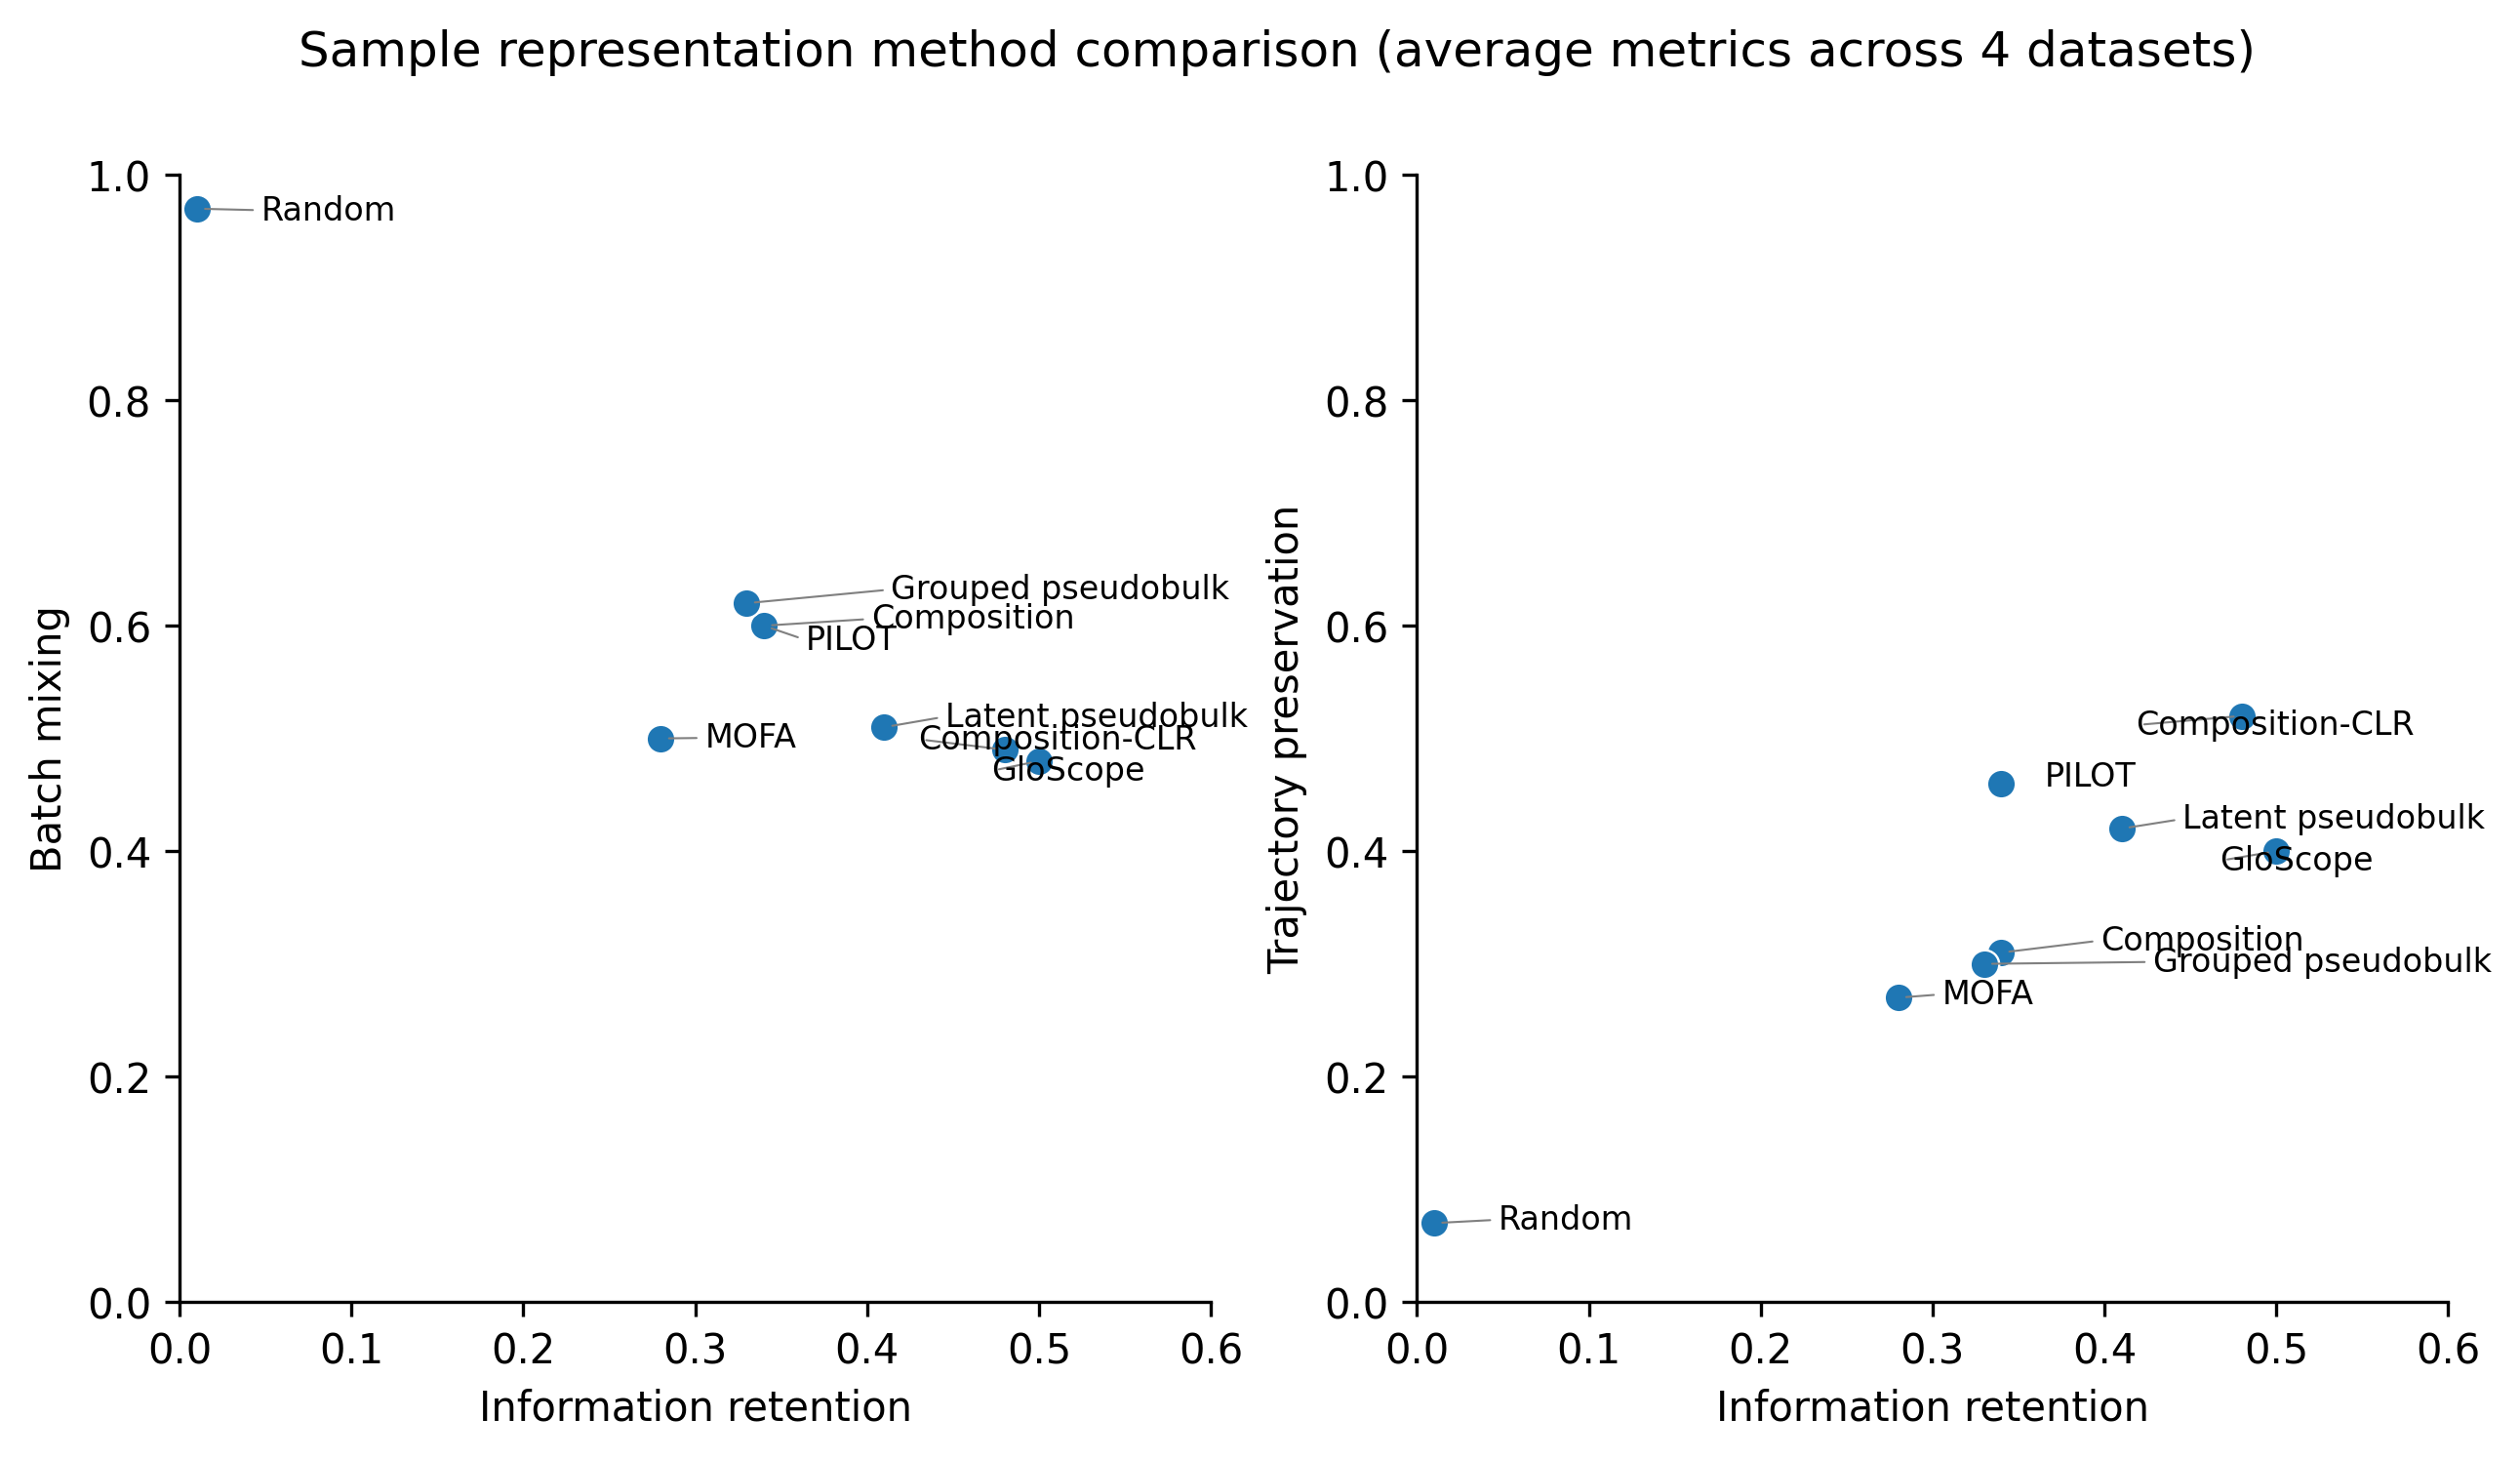

In [68]:
from adjustText import adjust_text

fig, axes = plt.subplots(ncols=2, figsize=(10, 5), dpi=300)

sns.scatterplot(
    cross_summary,
    x="Information retention",
    y="Batch mixing",
    ax=axes[0],
    s=50
)

sns.scatterplot(
    cross_summary,
    x="Information retention",
    y="Trajectory",
    ax=axes[1],
    s=50
)

texts_0, texts_1 = [], []

for method, row in cross_summary.iterrows():
    texts_0.append(
        axes[0].text(
            x=row["Information retention"],
            y=row["Batch mixing"],
            s=readable_method_names[method],
            fontdict={"size": 8},
            ha="left",
            va="center"
        )
    )

    texts_1.append(
        axes[1].text(
            x=row["Information retention"],
            y=row["Trajectory"],
            s=readable_method_names[method],
            fontdict={"size": 8},
            ha="left",
            va="center"
        )
    )

# adjust_text(texts_0, ax=axes[0], only_move={"text": "xy"}, explode_radius=400, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5), ha="left")
# adjust_text(texts_1, ax=axes[1], only_move={"text": "xy"}, explode_radius=400, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5), ha="left")

adjust_text(texts_0, ax=axes[0], force_text=(0.5, 0.5), arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
adjust_text(texts_1, ax=axes[1], force_text=(0.5, 0.5), arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))


for t in texts_0 + texts_1:
    t.set_horizontalalignment("left")

for ax in axes:
    ax.set_xlim(0, cross_summary["Information retention"].max() + 0.1)
    ax.set_ylim(0, 1)
    sns.despine(fig, ax)

axes[1].set_ylabel("Trajectory preservation")

fig.suptitle("Sample representation method comparison (average metrics across 4 datasets)")

Reading the scatter: top-right = best on both criteria.

**Note on coverage.** Some methods are not run on every dataset, so their averaged scores aggregate over fewer datasets than others. `GroupedPseudobulk` is skipped on HLCA and OneK1K (the per-cell-type filter wipes too many sparse cell types at those donor counts). Every other method, including `PILOT`, runs on all four datasets. Read the per-method scores together with the runtime table below to see which methods contributed to each average.

### Runtime per method per dataset (seconds)


In [100]:
runtime_table = pd.DataFrame(runtimes).round(1)
runtime_table["mean"] = runtime_table.mean(axis=1).round(1)
runtime_table.sort_values("mean")


,combat,hlca,stephenson,onek1k,mean
random_vec,0.0,0.0,0.0,0.1,0.0
composition_clr,0.2,0.7,0.2,0.4,0.4
grouped_pseudobulk,1.1,NaN,0.0,NaN,0.6
pseudobulk,0.3,1.8,0.3,1.9,1.1
composition,0.3,7.0,0.5,0.4,2.0
pilot,498.6,31.8,5.5,137.2,168.3
mofa,15.0,550.6,73.4,303.5,235.6
gloscope,246.9,205.6,32.8,892.7,344.5


We can see that baselines perform very strongly, especially CLR-transformed cell type composition. GloScope is the only method performing on par or better than the baselines for information retention, which we previously observed In the [SPARE sample representation methods benchmark](https://openreview.net/forum?id=IoRv5afWtb). PILOT on average performs well for trajectory preservation.

But as we have seen in this tutorial, performance of methods varies from one dataset to another. What works the best on average might hold for your data. Using `patpy`, you can quickly test what works for your case, and make the most from your data.

## Other methods and tutorials

We covered Pseudobulk, GroupedPseudobulk, CellGroupComposition, PILOT, MOFA, GloScope (Python), and a RandomVector baseline. `patpy` also ships:

- **`patpy.tl.MrVI`** — deep generative model. Requires GPU and takes very long to run. It is more convenient to run it in a separate environment.
- **`patpy.tl.SCPoli`** — conditional VAE that learns a per-sample prototype, batch-aware by construction. Needs `pip install patpy[scpoli]` and (currently) an `anndata < 0.12` env because `scarches` requirements.
- **`patpy.tl.DiffusionEarthMoverDistance`** — diffusion EMD over composition. Needs `pip install patpy[diffusionemd]` and `scikit-learn < 1.5` for the underlying `DiffusionEMD` package.

Related tutorials:
- [`sources_of_variation_with_gloscope.ipynb`](./sources_of_variation_with_gloscope.ipynb) — deep-dive on GloScope, including the R setup.
- [`supervised_methods_example.ipynb`](./supervised_methods_example.ipynb) — running supervised methods fine-tuned for a specific covariate prediction (MixMIL, PULSAR, PaSCient) via `patpy` interface.
- [`differential_analysis.ipynb`](./differential_analysis.ipynb) — interpreting sample-level variation with differential expression analysis.